# CIFAR-10 **Animal** Image Classification with a CNN

This notebook builds a Convolutional Neural Network (CNN) that classifies images into
**6 animal categories** taken from the CIFAR-10 dataset:

> `bird`, `cat`, `deer`, `dog`, `frog`, `horse`

The original CIFAR-10 dataset has 10 classes, 4 of which are vehicles
(`airplane`, `automobile`, `ship`, `truck`). We deliberately **drop the vehicle
classes** so the model only ever has to tell animals apart from other animals.

This notebook is adapted and heavily re-commented from the general structure of
popular public CIFAR-10 CNN walkthroughs (e.g. Farzad Nekouei's
"CIFAR-10 Image Classification with CNN" on Kaggle), rewritten from scratch here so that:

1. Only the **animal** subset of CIFAR-10 is used.
2. Every cell is explained in plain language, aimed at someone who has
   never built a CNN before.
3. At the end, we discuss exactly **which hyperparameters to tune**, and how
   tuning them trades off accuracy against overfitting.

### What is CIFAR-10?
CIFAR-10 is a classic benchmark dataset of 60,000 tiny (32×32 pixel) color
photographs, split into 10 categories, 6,000 images per category
(5,000 for training, 1,000 for testing). It ships directly with Keras, so no
manual download is required — `keras.datasets.cifar10.load_data()` handles it.

### Why filter down to only animals?
- It turns a 10-class problem into an easier **6-class problem**, which is a
  nice way to see how dataset design affects model difficulty.
- Animal classes (bird, cat, deer, dog, frog, horse) are visually more similar
  to *each other* than to vehicles, so this is actually a slightly **harder**
  fine-grained task than the full 10-class problem, even though there are
  fewer classes — a good learning example of "fewer classes doesn't always
  mean easier."


## How to run this notebook

**Single entry point:** *Runtime → Run all* runs the whole project, from data download to final figures. Everything already trained is loaded from Drive, and anything missing is trained automatically. The only interaction is the optional image upload in **PIPELINE 7/9** (cancel it to use sample test images).

Every result is saved to Google Drive (`OUT_DIR`), so a new session never has to download or retrain anything that already exists. Each cell is labelled with its section and position, e.g. `[SHORTCUT 3/9]`, and stops with a clear message if a cell it depends on hasn't been run yet.

| Section | Run when | Re-run when |
|---|---|---|
| **Setup** (6 cells) | Every new session, top to bottom | You change `FORCE_*` switches, the data split or `LEVELS` |
| **Four-run experiment** (3 cells) | Once; later sessions load the saved runs | You change `LEVELS` or set `FORCE_RETRAIN = True` |
| **Shortcut experiment** (9 cells) | After the four runs; trains the shortcut models once | You change `SC_CFG`; figures (9/9) are optional |
| **Track 1** (7 cells + reload) | Any time after the above; measurement only, takes seconds | You change `T1_CFG`; every run is saved in its own folder |
| **Grayscale robustness** (5 cells) | After the four runs; trains its variants once | You change `GRAY_CFG` / `GRAY_VARIANTS`; only changed variants retrain |
| **Consistency training** (6 cells) | After the shortcut experiment and Track 1 cell 4/7; trains its variants once | You change `CONS_CFG` / `CONS_VARIANTS`; only changed variants retrain |
| **Final pipeline** (9 cells) | After everything above; cell 7/9 asks for an image upload | Any time: analyse new images with `run_pipeline(path)` |
| **Final figures** (10 cells) | After the pipeline; saves to `docs/final_figures/` | After retraining anything, to refresh the figures |

Cells marked *Definitions only* just define functions; re-run them only after editing them.

## Setup
Shared by everything below. Run all six cells at the start of each session.

In [1]:
# [SETUP 1/6] Imports, switches, save location and small helpers.
# Run once per session (re-run only if Colab restarts).
import os, json, time, hashlib
import numpy as np, pandas as pd, tensorflow as tf, matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers
from scipy.stats import wilcoxon

FORCE_REDOWNLOAD = False   # True = ignore the cached dataset / test sets and rebuild them
FORCE_RETRAIN = False      # True = retrain models even when saved ones exist
SEED = 42
ANIMALS = ['bird', 'cat', 'deer', 'dog', 'frog', 'horse']

# Save to Google Drive if it's connected; otherwise to local Colab disk (lost when the runtime resets).
try:
    from google.colab import drive
    drive.mount('/content/drive', timeout_ms=120000)
except Exception as e:
    print('Drive not connected (', e, ')')
OUT_DIR = ('/content/drive/MyDrive/cifar10_animal_runs' if os.path.isdir('/content/drive/MyDrive')
           else '/content/cifar10_animal_runs')
if not OUT_DIR.startswith('/content/drive'):
    print('WARNING: saving to local Colab disk - copy OUT_DIR to Drive before the session ends.')
DATA_DIR = os.path.join(OUT_DIR, 'data')
os.makedirs(DATA_DIR, exist_ok=True)
print('Saving everything to', OUT_DIR)

def require(*names, cell):
    """Stop with a clear message if an earlier cell hasn't been run in this session."""
    missing = [n for n in names if n not in globals()]
    if missing:
        raise RuntimeError(f'Missing {missing} - run the "{cell}" cell first.')

def save_model_atomic(model, path):
    """Save to a temp file then rename, so a disconnect mid-save never leaves a corrupt model."""
    tmp = path.replace('.keras', '.partial.keras')
    model.save(tmp); os.replace(tmp, path)

Mounted at /content/drive
Saving everything to /content/drive/MyDrive/cifar10_animal_runs


In [2]:
# [SETUP 2/6] Dataset loader: Hugging Face uoft-cs/cifar10, downloaded once and cached in DATA_DIR.
# Later sessions read the cached file (checked against a checksum) instead of downloading.
HF_DATASET = 'uoft-cs/cifar10'
DATA_FILE = os.path.join(DATA_DIR, 'cifar10_hf_uoft-cs.npz')
META_FILE = os.path.join(DATA_DIR, 'cifar10_hf_uoft-cs.meta.json')

def _sha256(*arrays):
    h = hashlib.sha256()
    for a in arrays:
        h.update(np.ascontiguousarray(a).tobytes())
    return h.hexdigest()

def load_cifar10_cached():
    """((x_train, y_train), (x_test, y_test)): raw uint8 images and (N, 1) labels, as Hugging Face gives them."""
    if os.path.exists(DATA_FILE) and os.path.exists(META_FILE) and not FORCE_REDOWNLOAD:
        with np.load(DATA_FILE) as d:
            arrs = d['x_train'], d['y_train'], d['x_test'], d['y_test']
        with open(META_FILE) as fh:
            meta = json.load(fh)
        if _sha256(*arrs) == meta['sha256']:
            print(f'Loaded cached {HF_DATASET} from {DATA_FILE} (saved {meta["saved_at"]})')
            return (arrs[0], arrs[1]), (arrs[2], arrs[3])
        print('Cached data failed its checksum - downloading again.')
    from datasets import load_dataset
    print(f'Downloading {HF_DATASET} from Hugging Face ...')
    hf = load_dataset(HF_DATASET)
    to_np = lambda split: (np.stack([np.array(im) for im in hf[split]['img']]),
                           np.array(hf[split]['label']).reshape(-1, 1))
    (a, b), (c, d) = to_np('train'), to_np('test')
    tmp = DATA_FILE.replace('.npz', '.partial.npz')        # write-then-rename: no half-written cache
    np.savez(tmp, x_train=a, y_train=b, x_test=c, y_test=d)
    os.replace(tmp, DATA_FILE)
    with open(META_FILE, 'w') as fh:
        json.dump(dict(source=f'https://huggingface.co/datasets/{HF_DATASET}', sha256=_sha256(a, b, c, d),
                       shapes={k: list(v.shape) for k, v in
                               dict(x_train=a, y_train=b, x_test=c, y_test=d).items()},
                       saved_at=time.strftime('%Y-%m-%d %H:%M:%S')), fh, indent=2)
    print('Saved dataset to', DATA_FILE)
    return (a, b), (c, d)

In [3]:
# [SETUP 3/6] Load the data, keep the 6 animal classes, scale to 0-1, split train / validation / test.
# Re-run this cell to get fresh, untouched copies of the arrays.
require('load_cifar10_cached', cell='SETUP 2/6')
(xtr, ytr), (xte, yte) = load_cifar10_cached()

def keep_animals(x, y):
    y = y.flatten(); m = np.isin(y, [2, 3, 4, 5, 6, 7])
    return x[m].astype('float32') / 255.0, (y[m] - 2).astype('int64')

xtr, ytr = keep_animals(xtr, ytr); xte, yte = keep_animals(xte, yte)
perm = np.random.default_rng(SEED).permutation(len(xtr))
xtr, ytr = xtr[perm], ytr[perm]
nval = int(len(xtr) * 0.12)
xval, yval, xtr, ytr = xtr[:nval], ytr[:nval], xtr[nval:], ytr[nval:]
print('train', xtr.shape, 'val', xval.shape, 'test', xte.shape)

Loaded cached uoft-cs/cifar10 from /content/drive/MyDrive/cifar10_animal_runs/data/cifar10_hf_uoft-cs.npz (saved 2026-10-27 15:27:21)
train (26400, 32, 32, 3) val (3600, 32, 32, 3) test (6000, 32, 32, 3)


In [4]:
# [SETUP 4/6] Augmentation levels and the function that applies them.
# Edit LEVELS here, then re-run this cell and everything below that you want updated.
LEVELS = {
    'run1_original': None,
    'run2_mild':     dict(rotation=0.03, brightness=0.08, contrast=0.10, sat=(0.8, 1.2), hue=0.03, swap_p=0.0),
    'run3_stronger': dict(rotation=0.08, brightness=0.15, contrast=0.25, sat=(0.5, 1.5), hue=0.10, swap_p=0.15),
    'run4_heavy':    dict(rotation=0.12, brightness=0.20, contrast=0.35, sat=(0.3, 1.7), hue=0.25, swap_p=0.60),
}
# rotation factor x 360 = max degrees (0.03 = ±11°, 0.08 = ±29°, 0.12 = ±43°)
# swap_p = chance an image gets its R/G/B channels shuffled (e.g. red fur -> blue fur)

PERMS = tf.constant(np.stack([np.eye(3)[list(p)].T for p in
    [(0,1,2),(0,2,1),(1,0,2),(1,2,0),(2,0,1),(2,1,0)]]), tf.float32)

def make_alter(cfg, seed):
    if cfg is None:
        return lambda x: x
    rot = layers.RandomRotation(cfg['rotation'], fill_mode='reflect', seed=seed)
    def alter(x):
        b = tf.shape(x)[0]
        x = rot(x, training=True)
        x = x + tf.random.uniform([b, 1, 1, 1], -cfg['brightness'], cfg['brightness'])
        mean = tf.reduce_mean(x, axis=[1, 2, 3], keepdims=True)
        x = (x - mean) * tf.random.uniform([b, 1, 1, 1], 1 - cfg['contrast'], 1 + cfg['contrast']) + mean
        hsv = tf.image.rgb_to_hsv(tf.clip_by_value(x, 0., 1.))
        h = tf.math.floormod(hsv[..., 0] + tf.random.uniform([b, 1, 1], -cfg['hue'], cfg['hue']), 1.0)
        s = tf.clip_by_value(hsv[..., 1] * tf.random.uniform([b, 1, 1], cfg['sat'][0], cfg['sat'][1]), 0., 1.)
        x = tf.image.hsv_to_rgb(tf.stack([h, s, hsv[..., 2]], -1))
        if cfg['swap_p'] > 0:
            idx = tf.random.uniform([b], 1, 6, dtype=tf.int32)
            idx = tf.where(tf.random.uniform([b]) < cfg['swap_p'], idx, tf.zeros_like(idx))
            x = tf.einsum('bhwc,bcd->bhwd', x, tf.gather(PERMS, idx))
        return tf.clip_by_value(x, 0., 1.)
    return alter

In [5]:
# [SETUP 5/6] Fixed altered copies of the test set (one per level), cached so every session scores
# exactly the same images. The file name includes a hash of LEVELS, so editing a level makes a new cache.
require('xte', cell='SETUP 3/6'); require('LEVELS', 'make_alter', cell='SETUP 4/6')
lvl_hash = hashlib.sha256(json.dumps(LEVELS, sort_keys=True).encode()).hexdigest()[:10]
TEST_SETS_FILE = os.path.join(DATA_DIR, f'altered_test_sets_seed999_{lvl_hash}.npz')
if os.path.exists(TEST_SETS_FILE) and not FORCE_REDOWNLOAD:
    with np.load(TEST_SETS_FILE) as d:
        test_sets = {k: d[k] for k in LEVELS}
    print('Loaded altered test sets from', TEST_SETS_FILE)
else:
    tf.keras.utils.set_random_seed(999)
    test_sets = {}
    for name, cfg in LEVELS.items():
        f = make_alter(cfg, seed=999)
        test_sets[name] = np.concatenate([f(tf.constant(xte[i:i+500])).numpy() for i in range(0, len(xte), 500)])
    tmp = TEST_SETS_FILE.replace('.npz', '.partial.npz')
    np.savez(tmp, **test_sets); os.replace(tmp, TEST_SETS_FILE)
    print('Saved altered test sets to', TEST_SETS_FILE)

Loaded altered test sets from /content/drive/MyDrive/cifar10_animal_runs/data/altered_test_sets_seed999_c913e1460d.npz


In [6]:
# [SETUP 6/6] The CNN used by the four runs and the shortcut experiment.
# (Named build_run_model because Section 7 further down defines a different build_model.)
def build_run_model():
    inp = keras.Input((32, 32, 3)); x = inp
    for f in (32, 64, 128):
        for _ in range(2):
            x = layers.Conv2D(f, 3, padding='same', activation='relu')(x); x = layers.BatchNormalization()(x)
        x = layers.MaxPooling2D()(x); x = layers.Dropout(0.25)(x)
    x = layers.Flatten()(x); x = layers.Dense(256, activation='relu')(x)
    x = layers.BatchNormalization()(x); x = layers.Dropout(0.5)(x)
    return keras.Model(inp, layers.Dense(6, activation='softmax')(x))

def load_run_model(name):
    """Reload a finished augmentation run, e.g. load_run_model('run4_heavy')."""
    return keras.models.load_model(os.path.join(OUT_DIR, name, f'{name}_model.keras'))

## Four-run augmentation experiment
Run 1: no changes | Run 2: mild colour + rotation | Run 3: stronger | Run 4: heavy colour swaps.
Each run trains a CNN on images altered at that level, then tests it on clean test images **and** on test images altered at every level (a robustness check). Saved runs are loaded instead of retrained.

In [7]:
# [FOUR-RUN 1/3] Train-or-load for one augmentation run. Definitions only; nothing runs yet.
def show_training_samples(ds, name, run_dir):
    sx, sy = next(iter(ds))
    plt.figure(figsize=(10, 3.5))
    for i in range(12):
        plt.subplot(2, 6, i + 1); plt.imshow(sx[i]); plt.title(ANIMALS[int(sy[i])], fontsize=8); plt.axis('off')
    plt.suptitle(f'{name}: training images'); plt.tight_layout()
    plt.savefig(os.path.join(run_dir, 'sample_images.png'), dpi=120); plt.show()

def train_or_load_run(run_i, name, cfg):
    """Returns this run's results dict. Skips training when the model + results are already saved."""
    run_dir = os.path.join(OUT_DIR, name); os.makedirs(run_dir, exist_ok=True)
    model_path = os.path.join(run_dir, f'{name}_model.keras')
    res_path = os.path.join(run_dir, f'{name}_results.json')
    if not FORCE_RETRAIN and os.path.exists(model_path):
        if os.path.exists(res_path):
            print(f'{name}: saved model + results found -> skipping training')
            with open(res_path) as fh:
                return json.load(fh)
        print(f'{name}: saved model found but no results -> loading and re-evaluating')
        model, history, minutes = keras.models.load_model(model_path), {}, None
    else:
        print(f'{name}: training, settings {cfg}')
        tf.keras.utils.set_random_seed(SEED)
        alter = make_alter(cfg, seed=100 + run_i)
        ds = (tf.data.Dataset.from_tensor_slices((xtr, ytr)).shuffle(len(xtr), seed=SEED)
              .batch(64).map(lambda x, y: (alter(x), y)).prefetch(tf.data.AUTOTUNE))
        show_training_samples(ds, name, run_dir)
        model = build_run_model()
        model.compile(optimizer=keras.optimizers.Adam(1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
        t0 = time.time()
        hist = model.fit(ds, validation_data=(xval, yval), epochs=25, verbose=2, callbacks=[
            keras.callbacks.EarlyStopping('val_loss', patience=5, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau('val_loss', factor=0.5, patience=2, min_lr=1e-6)])
        history = {k: [float(v) for v in vs] for k, vs in hist.history.items()}
        minutes = round((time.time() - t0) / 60, 1)
        save_model_atomic(model, model_path)
        print('saved model to', model_path)
    acc = {f'test_{k}': float(model.evaluate(v, yte, verbose=0)[1]) for k, v in test_sets.items()}
    res = dict(run=name, settings=cfg, epochs_trained=len(history.get('loss', [])) or None, minutes=minutes,
               best_val_accuracy=float(max(history['val_accuracy'])) if history else None, **acc, history=history)
    with open(res_path, 'w') as fh:
        json.dump(res, fh, indent=2)
    print({k: round(v, 4) for k, v in acc.items()})
    return res

In [8]:
# [FOUR-RUN 2/3] Run all four levels. Saved runs load in seconds; missing ones train (~3 min each on GPU).
require('test_sets', cell='SETUP 5/6'); require('build_run_model', cell='SETUP 6/6')
require('train_or_load_run', cell='FOUR-RUN 1/3')
run_results = {}
for run_i, (name, cfg) in enumerate(LEVELS.items()):
    run_results[name] = train_or_load_run(run_i, name, cfg)

run1_original: saved model + results found -> skipping training
run2_mild: saved model + results found -> skipping training
run3_stronger: saved model + results found -> skipping training
run4_heavy: saved model + results found -> skipping training


In [9]:
# [FOUR-RUN 3/3] Comparison table: rows = how the model was trained, columns = which test set.
require('run_results', cell='FOUR-RUN 2/3')
run_table = pd.DataFrame({n: {k.replace('test_', 'tested on '): r[k] for k in r if k.startswith('test_')}
                          for n, r in run_results.items()}).T
run_table.to_csv(os.path.join(OUT_DIR, 'all_runs_summary.csv'))
print('Test accuracy % (rows = trained with, columns = tested on):')
display((run_table * 100).round(2))

Test accuracy % (rows = trained with, columns = tested on):


,tested on run1_original,tested on run2_mild,tested on run3_stronger,tested on run4_heavy
run1_original,84.02,77.87,65.90,50.93
run2_mild,82.35,81.97,70.93,55.57
run3_stronger,81.97,82.52,79.07,72.50
run4_heavy,76.95,76.23,75.28,73.52


## Controlled shortcut experiment (with vs. without the shortcut)
* **Injected shortcut** – a 4×4 colour patch in the corner encodes the class in 95% of training and validation images. Every test image is scored *clean*, with a *neutral grey patch* (occlusion control), with the *correct* patch and with a *wrong-class* patch.
* **Natural colour shortcut** – the same images in grayscale and with RGB→BGR swapped.

Results go to `OUT_DIR/shortcut_experiment/`. Baselines are the four-run models; shortcut models are trained once (cell 3/9) and reloaded afterwards. Cells 4–9 only measure and can be re-run freely.

In [10]:
# [SHORTCUT 1/9] Settings and the colour patch that acts as the injected shortcut.
# Edit SC_CFG here; re-run this cell and the shortcut cells below it.
require('xtr', 'xval', 'yval', cell='SETUP 3/6')
SC_CFG = dict(
    patch_size=4,                                   # k x k pixels, top-left corner
    shortcut_p=0.95,                                # share of train/val images carrying their class patch
    train_levels=['run1_original', 'run4_heavy'],   # augmentation levels to test (any keys of LEVELS)
    n_per_class=None,                               # None = all test images; e.g. 200 for a quick run
    epochs=25, batch=64, seed=SEED,
)
SC_DIR = os.path.join(OUT_DIR, 'shortcut_experiment'); os.makedirs(SC_DIR, exist_ok=True)
PATCH_SIZE, NC = SC_CFG['patch_size'], len(ANIMALS)
PATCH_COLORS = np.array([[1, 0, 0], [0, 1, 0], [0, 0, 1],      # bird=red, cat=green, deer=blue
                         [1, 1, 0], [1, 0, 1], [0, 1, 1]],     # dog=yellow, frog=magenta, horse=cyan
                        'float32')
NEUTRAL = np.array([0.5, 0.5, 0.5], 'float32')

def add_patch(x, colors, mask=None):
    """numpy: paint a KxK patch of the given per-image colour (N,3); mask picks which images."""
    x = x.copy()
    mask = np.ones(len(x), bool) if mask is None else mask
    x[mask, :PATCH_SIZE, :PATCH_SIZE, :] = colors[mask][:, None, None, :]
    return x

def tf_add_patch(x, y, p):
    """tf.data version: each image gets its class patch with probability p, applied AFTER augmentation."""
    if p <= 0:
        return x
    K, (H, W) = PATCH_SIZE, xtr.shape[1:3]
    has = tf.cast(tf.random.uniform([tf.shape(x)[0]]) < p, x.dtype)[:, None, None, None]
    col = tf.gather(tf.constant(PATCH_COLORS), y)[:, None, None, :]
    region = tf.pad(tf.ones([K, K, 1], x.dtype), [[0, H - K], [0, W - K], [0, 0]])[None]
    m = region * has
    return x * (1 - m) + col * m

# Validation follows the training distribution: a clean val set would let EarlyStopping
# quietly select against the shortcut and confound the test.
xval_sc = add_patch(xval, PATCH_COLORS[yval],
                    np.random.default_rng(SC_CFG['seed'] + 1).random(len(xval)) < SC_CFG['shortcut_p'])

In [11]:
# [SHORTCUT 2/9] Train-or-load for baseline / shortcut models. Definitions only.
def get_sc_model(level, shortcut):
    """Baseline = the model the four-run cells saved. Shortcut = trained here once, then reloaded."""
    tag = 'shortcut' if shortcut else 'baseline'
    out = os.path.join(SC_DIR, f'{level}_{tag}.keras')
    hist_path = out.replace('.keras', '_history.json')
    candidates = [out] if shortcut else [os.path.join(OUT_DIR, level, f'{level}_model.keras'), out]
    for saved in ([] if FORCE_RETRAIN else candidates):
        if os.path.exists(saved):
            print(f'loading {level} | {tag} from {saved} (no retraining)')
            h = json.load(open(hist_path)) if os.path.exists(hist_path) else None
            return keras.models.load_model(saved), h
    print(f'\n=== training {level} | {tag} ===')
    tf.keras.utils.set_random_seed(SC_CFG['seed'])
    alter = make_alter(LEVELS[level], seed=100 + list(LEVELS).index(level))
    p = SC_CFG['shortcut_p'] if shortcut else 0.0
    ds = (tf.data.Dataset.from_tensor_slices((xtr, ytr)).shuffle(len(xtr), seed=SC_CFG['seed'])
          .batch(SC_CFG['batch']).map(lambda x, y: (tf_add_patch(alter(x), y, p), y))
          .prefetch(tf.data.AUTOTUNE))
    model = build_run_model()
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    hist = model.fit(ds, validation_data=(xval_sc if shortcut else xval, yval),
                     epochs=SC_CFG['epochs'], verbose=2, callbacks=[
        keras.callbacks.EarlyStopping('val_loss', patience=5, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau('val_loss', factor=0.5, patience=2, min_lr=1e-6)])
    save_model_atomic(model, out)
    h = {k: [float(v) for v in vs] for k, vs in hist.history.items()}
    with open(hist_path, 'w') as fh:
        json.dump(h, fh)
    print('saved', out)
    return model, h

In [12]:
# [SHORTCUT 3/9] Load (or, the first time, train) baseline + shortcut models for each level.
require('xval_sc', cell='SHORTCUT 1/9'); require('get_sc_model', cell='SHORTCUT 2/9')
sc_models, sc_histories = {}, {}
for level in SC_CFG['train_levels']:
    for shortcut in (False, True):
        name = f"{level}|{'shortcut' if shortcut else 'baseline'}"
        sc_models[name], sc_histories[name] = get_sc_model(level, shortcut)

loading run1_original | baseline from /content/drive/MyDrive/cifar10_animal_runs/run1_original/run1_original_model.keras (no retraining)
loading run1_original | shortcut from /content/drive/MyDrive/cifar10_animal_runs/shortcut_experiment/run1_original_shortcut.keras (no retraining)
loading run4_heavy | baseline from /content/drive/MyDrive/cifar10_animal_runs/run4_heavy/run4_heavy_model.keras (no retraining)
loading run4_heavy | shortcut from /content/drive/MyDrive/cifar10_animal_runs/shortcut_experiment/run4_heavy_shortcut.keras (no retraining)


In [13]:
# [SHORTCUT 4/9] Fixed test images and the six test conditions (same images in every condition).
sc_rng = np.random.default_rng(SC_CFG['seed'] + 2)
if SC_CFG['n_per_class']:
    sc_idx = np.sort(np.concatenate([sc_rng.choice(np.where(yte == c)[0], SC_CFG['n_per_class'], replace=False)
                                     for c in range(NC)]))
else:
    sc_idx = np.arange(len(xte))
sc_x0, sc_y0 = xte[sc_idx], yte[sc_idx]
sc_n = len(sc_idx)
sc_wrong = (sc_y0 + 1) % NC                       # fixed "misleading" class for the conflict test

SC_CONDITIONS = {   # name: (probe family, images)
    'clean':            ('injected_patch', sc_x0),
    'neutral_patch':    ('injected_patch', add_patch(sc_x0, np.tile(NEUTRAL, (sc_n, 1)))),
    'aligned_shortcut': ('injected_patch', add_patch(sc_x0, PATCH_COLORS[sc_y0])),
    'conflicting':      ('injected_patch', add_patch(sc_x0, PATCH_COLORS[sc_wrong])),
    'grayscale':        ('natural_color',  np.repeat(tf.image.rgb_to_grayscale(sc_x0).numpy(), 3, -1)),
    'channel_swap_bgr': ('natural_color',  sc_x0[..., ::-1].copy()),
}
print(f'{sc_n} test images x {len(SC_CONDITIONS)} conditions')

6000 test images x 6 conditions


In [14]:
# [SHORTCUT 5/9] Per-image predictions + confidence for every model and condition.
require('sc_models', cell='SHORTCUT 3/9'); require('SC_CONDITIONS', cell='SHORTCUT 4/9')
rows, ar = [], np.arange(sc_n)
for mname, model in sc_models.items():
    level, kind = mname.split('|')
    for cname, (family, xc) in SC_CONDITIONS.items():
        prob = model.predict(xc, batch_size=512, verbose=0)
        pred = prob.argmax(1)
        rows.append(pd.DataFrame(dict(
            model=mname, train_level=level, model_kind=kind, probe=family, condition=cname,
            image_idx=sc_idx, true_label=sc_y0, true_name=np.array(ANIMALS)[sc_y0],
            pred_label=pred, pred_name=np.array(ANIMALS)[pred], correct=pred == sc_y0,
            true_conf=prob[ar, sc_y0], max_conf=prob.max(1),
            misleading_class=sc_wrong, misleading_conf=prob[ar, sc_wrong],
            followed_misleading=pred == sc_wrong)))
sc_per_image = pd.concat(rows, ignore_index=True)
sc_per_image.to_csv(os.path.join(SC_DIR, 'per_image_results.csv'), index=False)
print(len(sc_per_image), 'rows saved to per_image_results.csv')

144000 rows saved to per_image_results.csv


In [15]:
# [SHORTCUT 6/9] Organise: paired with/without table, summary by condition, effect sizes, per class.
require('sc_per_image', cell='SHORTCUT 5/9')
sc_paired = sc_per_image.pivot_table(index=['model', 'image_idx', 'true_name'], columns='condition',
                                     values='true_conf').reset_index()
SC_EFFECTS = {   # name: (with, without, what it isolates)
    'shortcut_gain (aligned - neutral)':     ('aligned_shortcut', 'neutral_patch', 'pure effect of a label-coding colour; occlusion held fixed'),
    'shortcut_harm (conflicting - neutral)': ('conflicting', 'neutral_patch', 'confidence lost when the cue points to a wrong class'),
    'occlusion (neutral - clean)':           ('neutral_patch', 'clean', 'control: cost of covering the corner at all'),
    'color_reliance (clean - grayscale)':    ('clean', 'grayscale', 'confidence that depends on colour'),
    'color_reliance (clean - bgr swap)':     ('clean', 'channel_swap_bgr', 'confidence that depends on the colour mapping'),
}
for ename, (a, b, _) in SC_EFFECTS.items():
    sc_paired[ename] = sc_paired[a] - sc_paired[b]

sc_summary = (sc_per_image.groupby(['model', 'probe', 'condition'], sort=False)
              .agg(n_images=('correct', 'size'), accuracy=('correct', 'mean'),
                   mean_true_conf=('true_conf', 'mean'), median_true_conf=('true_conf', 'median'),
                   mean_max_conf=('max_conf', 'mean'), followed_misleading=('followed_misleading', 'mean'))
              .reset_index())
sc_summary.loc[sc_summary.condition != 'conflicting', 'followed_misleading'] = np.nan

eff_rows = []
for mname, g in sc_paired.groupby('model', sort=False):
    for ename, (a, b, meaning) in SC_EFFECTS.items():
        d = g[ename].to_numpy(); se = d.std(ddof=1) / np.sqrt(len(d))
        try:
            p = wilcoxon(d).pvalue if np.any(d != 0) else 1.0
        except ValueError:
            p = np.nan
        eff_rows.append(dict(model=mname, effect=ename, isolates=meaning, mean_delta=d.mean(),
                             ci95_low=d.mean() - 1.96 * se, ci95_high=d.mean() + 1.96 * se,
                             share_images_up=(d > 0.01).mean(), share_images_down=(d < -0.01).mean(),
                             wilcoxon_p=p))
sc_effects = pd.DataFrame(eff_rows)
sc_per_class = (sc_per_image.groupby(['model', 'condition', 'true_name'])
                .agg(accuracy=('correct', 'mean'), mean_true_conf=('true_conf', 'mean')).reset_index())

In [16]:
# [SHORTCUT 7/9] Save the organised tables and the settings used.
require('sc_effects', cell='SHORTCUT 6/9')
sc_paired.to_csv(os.path.join(SC_DIR, 'paired_confidence.csv'), index=False)
sc_summary.to_csv(os.path.join(SC_DIR, 'summary_by_condition.csv'), index=False)
sc_effects.to_csv(os.path.join(SC_DIR, 'effects_summary.csv'), index=False)
sc_per_class.to_csv(os.path.join(SC_DIR, 'per_class_summary.csv'), index=False)
with open(os.path.join(SC_DIR, 'config.json'), 'w') as fh:
    json.dump(dict(SC_CFG, patch_colors=dict(zip(ANIMALS, PATCH_COLORS.tolist())),
                   neutral=NEUTRAL.tolist(), n_test_images=int(sc_n), histories=sc_histories), fh, indent=2)
print('Saved CSVs and config.json to', SC_DIR)

Saved CSVs and config.json to /content/drive/MyDrive/cifar10_animal_runs/shortcut_experiment


In [17]:
# [SHORTCUT 8/9] Result tables + plain-language verdict per model.
require('sc_effects', cell='SHORTCUT 6/9')
cond_order = list(SC_CONDITIONS)
print('Mean TRUE-class confidence (rows = model, cols = test condition):')
display(sc_summary.pivot(index='model', columns='condition', values='mean_true_conf')[cond_order].round(3))
print('Accuracy:')
display(sc_summary.pivot(index='model', columns='condition', values='accuracy')[cond_order].round(3))
print('Share of conflicting images predicted as the patch class (compare shortcut rows to baseline rows):')
display(sc_summary[sc_summary.condition == 'conflicting'].set_index('model')[['followed_misleading']].round(3))
print('Paired effects (mean change in true-class confidence):')
display(sc_effects.pivot(index='model', columns='effect', values='mean_delta').round(3))

key = 'shortcut_gain (aligned - neutral)'
for mname in sc_models:
    e = sc_effects[sc_effects.model == mname].set_index('effect').mean_delta
    f = sc_summary[(sc_summary.model == mname) & (sc_summary.condition == 'conflicting')].followed_misleading.iloc[0]
    print(f"{mname:28s} shortcut gain {e[key]:+.3f} | conflict harm "
          f"{e['shortcut_harm (conflicting - neutral)']:+.3f} | follows wrong patch {f:.1%} | "
          f"colour reliance {e['color_reliance (clean - grayscale)']:+.3f}")

Mean TRUE-class confidence (rows = model, cols = test condition):


condition,clean,neutral_patch,aligned_shortcut,conflicting,grayscale,channel_swap_bgr
model,,,,,,
run1_original|baseline,0.809,0.806,0.807,0.796,0.740,0.690
run1_original|shortcut,0.566,0.563,1.000,0.006,0.509,0.450
run4_heavy|baseline,0.687,0.684,0.683,0.682,0.688,0.686
run4_heavy|shortcut,0.417,0.414,1.000,0.000,0.415,0.412


Accuracy:


condition,clean,neutral_patch,aligned_shortcut,conflicting,grayscale,channel_swap_bgr
model,,,,,,
run1_original|baseline,0.840,0.839,0.840,0.828,0.775,0.725
run1_original|shortcut,0.671,0.670,1.000,0.002,0.628,0.556
run4_heavy|baseline,0.770,0.768,0.766,0.766,0.768,0.768
run4_heavy|shortcut,0.529,0.527,1.000,0.000,0.535,0.530


Share of conflicting images predicted as the patch class (compare shortcut rows to baseline rows):


,followed_misleading
model,
run1_original|baseline,0.023
run1_original|shortcut,0.998
run4_heavy|baseline,0.032
run4_heavy|shortcut,1.000


Paired effects (mean change in true-class confidence):


effect,color_reliance (clean - bgr swap),color_reliance (clean - grayscale),occlusion (neutral - clean),shortcut_gain (aligned - neutral),shortcut_harm (conflicting - neutral)
model,,,,,
run1_original|baseline,0.119,0.069,-0.003,0.001,-0.010
run1_original|shortcut,0.117,0.058,-0.003,0.437,-0.557
run4_heavy|baseline,0.001,-0.001,-0.002,-0.002,-0.003
run4_heavy|shortcut,0.005,0.002,-0.003,0.586,-0.414


run1_original|baseline       shortcut gain +0.001 | conflict harm -0.010 | follows wrong patch 2.3% | colour reliance +0.069
run1_original|shortcut       shortcut gain +0.437 | conflict harm -0.557 | follows wrong patch 99.8% | colour reliance +0.058
run4_heavy|baseline          shortcut gain -0.002 | conflict harm -0.003 | follows wrong patch 3.2% | colour reliance -0.001
run4_heavy|shortcut          shortcut gain +0.586 | conflict harm -0.414 | follows wrong patch 100.0% | colour reliance +0.002


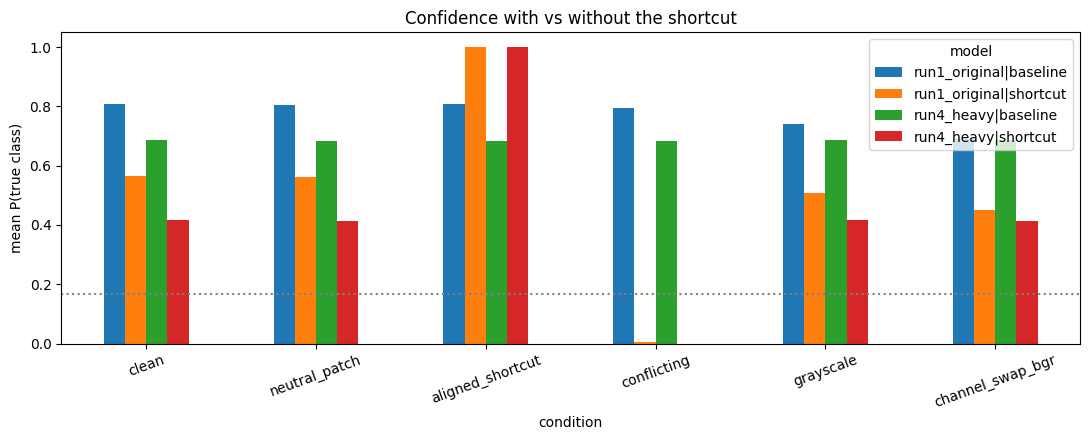

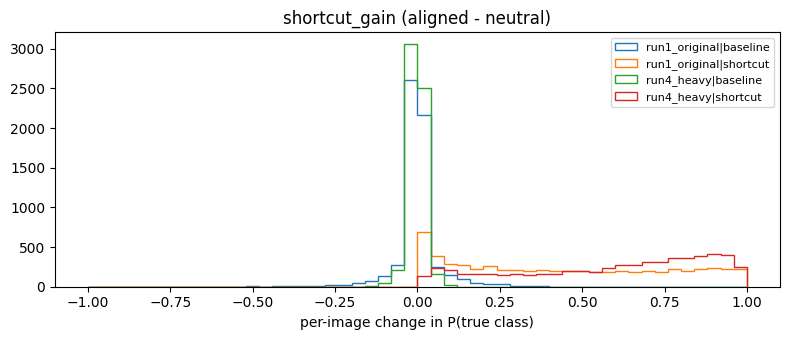

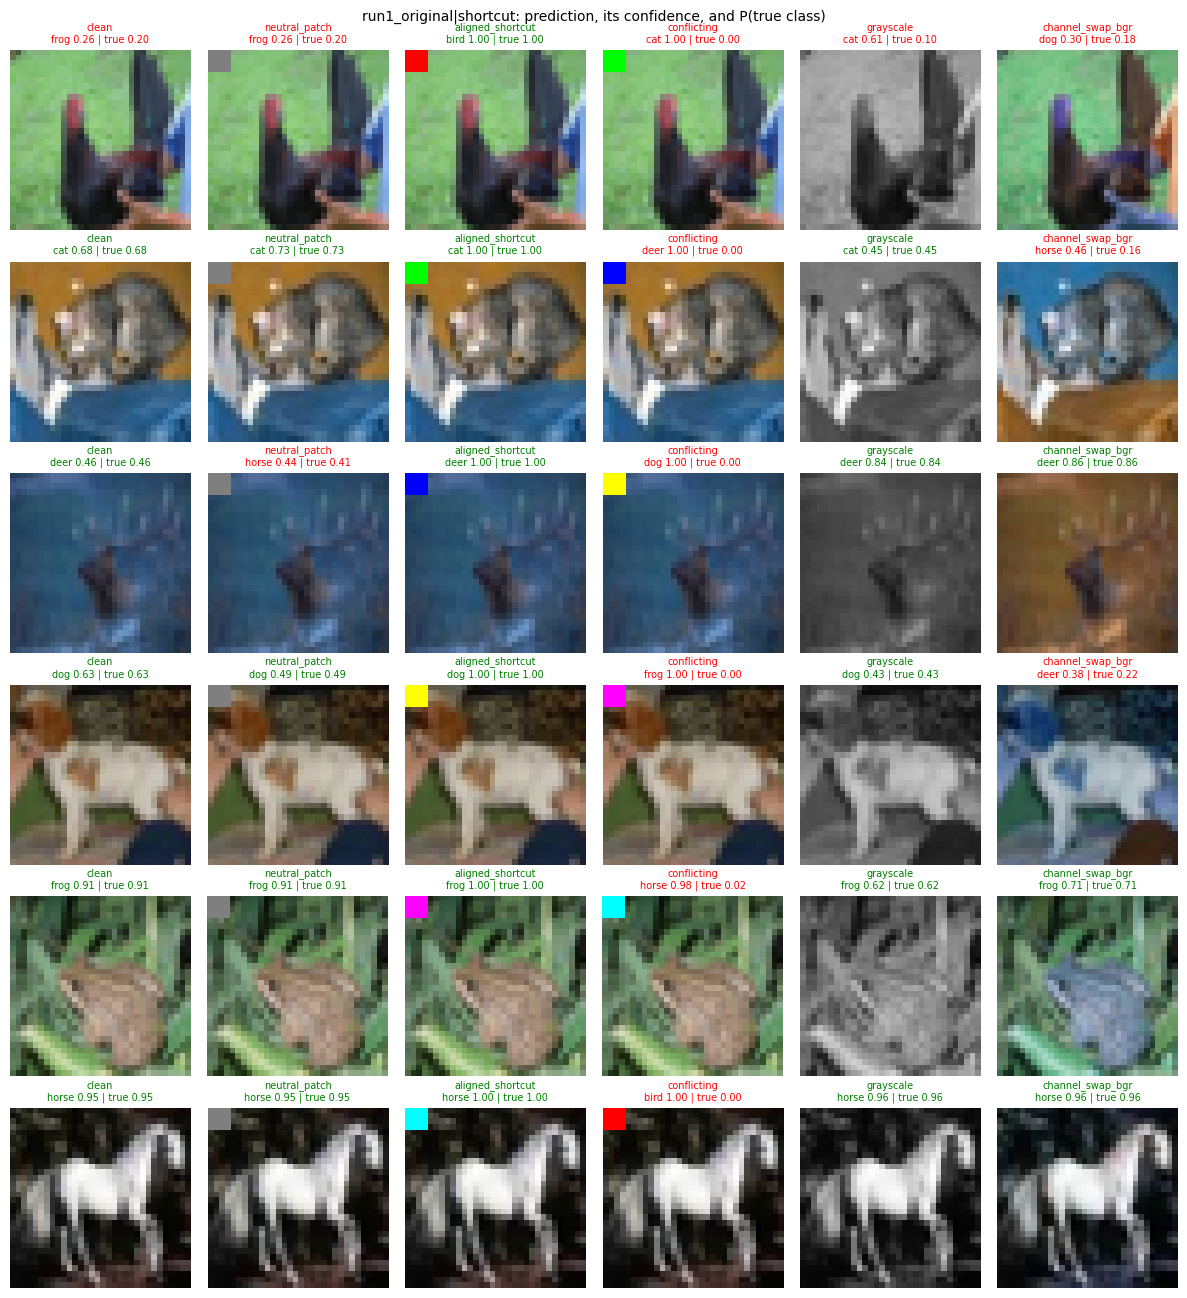

In [18]:
# [SHORTCUT 9/9] Figures (saved to SC_DIR). Optional - skip if you only need the numbers.
require('sc_effects', cell='SHORTCUT 6/9')
piv = sc_summary.pivot(index='condition', columns='model', values='mean_true_conf').loc[list(SC_CONDITIONS)]
ax = piv.plot.bar(figsize=(11, 4.5), rot=20)
ax.set_ylabel('mean P(true class)'); ax.set_title('Confidence with vs without the shortcut')
ax.axhline(1 / NC, ls=':', c='grey'); plt.tight_layout()
plt.savefig(os.path.join(SC_DIR, 'confidence_by_condition.png'), dpi=120); plt.show()

key = 'shortcut_gain (aligned - neutral)'
plt.figure(figsize=(8, 3.5))
for mname, g in sc_paired.groupby('model', sort=False):
    plt.hist(g[key], bins=50, range=(-1, 1), histtype='step', lw=1.5, label=mname)
plt.xlabel('per-image change in P(true class)'); plt.title(key); plt.legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(SC_DIR, 'shortcut_gain_hist.png'), dpi=120); plt.show()

show_model = [m for m in sc_models if m.endswith('shortcut')][0]
pick = [int(np.where(sc_y0 == c)[0][0]) for c in range(NC)]
lookup = sc_per_image[sc_per_image.model == show_model].set_index(['condition', 'image_idx'])
fig, axes = plt.subplots(NC, len(SC_CONDITIONS), figsize=(2 * len(SC_CONDITIONS), 2.2 * NC))
for r, i in enumerate(pick):
    for c, (cname, (_, xc)) in enumerate(SC_CONDITIONS.items()):
        rec = lookup.loc[(cname, sc_idx[i])]
        a = axes[r, c]; a.imshow(xc[i]); a.axis('off')
        a.set_title(f"{cname}\n{rec.pred_name} {rec.max_conf:.2f} | true {rec.true_conf:.2f}",
                    fontsize=7, color='green' if rec.correct else 'red')
fig.suptitle(f'{show_model}: prediction, its confidence, and P(true class)', fontsize=10)
plt.tight_layout(); plt.savefig(os.path.join(SC_DIR, 'examples_grid.png'), dpi=120); plt.show()

## Track 1: Confidence with vs. without the shortcut
Measurement only; nothing is trained. A fixed, class-balanced set of **200 test images** is run through every saved model **with** the shortcut and **without** it:

| Pair | With shortcut | Without shortcut |
|---|---|---|
| `patch_vs_neutral` | correct-class patch | grey patch (neutralised) |
| `patch_vs_removed` | correct-class patch | no patch (removed) |
| `color_vs_grayscale` | original colour | grayscale (removed) |
| `color_vs_bgr` | original colour | RGB→BGR (neutralised) |

Per image: `conf_with`, `conf_without` (probability of the true class), `delta = conf_with − conf_without`, both predictions, and whether the prediction **flipped** (and in which direction). Output: `OUT_DIR/track1/<timestamp>/track1_results.json` plus CSV copies, with every run listed in `OUT_DIR/track1/index.json`. The last cell reloads any saved run.

In [19]:
# [TRACK 1 · 1/7] Settings, and the exact patch the shortcut models were trained with.
# Edit T1_CFG here; re-run this cell and the Track 1 cells below it.
require('xte', 'yte', cell='SETUP 3/6'); require('LEVELS', cell='SETUP 4/6')
T1_CFG = dict(
    n_images=200,                 # total images, split as evenly as possible across the 6 classes
    seed=SEED + 7,                # fixed seed -> the same 200 images every run
    levels=list(LEVELS),          # augmentation levels whose models to include (missing ones are skipped)
    pairs=['patch_vs_neutral', 'patch_vs_removed', 'color_vs_grayscale', 'color_vs_bgr'],
    extra_models=dict(grayscale='best', consistency='all'),  # other sections' saved models: 'best', 'all' or leave out
)
T1_ROOT = os.path.join(OUT_DIR, 'track1')
T1_SC_DIR = os.path.join(OUT_DIR, 'shortcut_experiment')

# Patch settings come from the shortcut experiment's saved config, so they always match training.
t1_cfg_path = os.path.join(T1_SC_DIR, 'config.json')
if os.path.exists(t1_cfg_path):
    with open(t1_cfg_path) as fh:
        _sc = json.load(fh)
    t1_patch_size = _sc['patch_size']
    t1_patch_colors = np.array([_sc['patch_colors'][a] for a in ANIMALS], 'float32')
    t1_neutral = np.array(_sc['neutral'], 'float32')
    print('Patch settings read from', t1_cfg_path)
else:
    t1_patch_size, t1_neutral = 4, np.full(3, 0.5, 'float32')
    t1_patch_colors = np.array([[1, 0, 0], [0, 1, 0], [0, 0, 1], [1, 1, 0], [1, 0, 1], [0, 1, 1]], 'float32')
    print('NOTE: shortcut_experiment/config.json not found - using the default patch settings.')

Patch settings read from /content/drive/MyDrive/cifar10_animal_runs/shortcut_experiment/config.json


In [20]:
# [TRACK 1 · 2/7] Pick the 200 images (class-balanced, seeded) and build the with/without versions.
require('T1_CFG', cell='TRACK 1 · 1/7')
NC = len(ANIMALS)
t1_rng = np.random.default_rng(T1_CFG['seed'])
t1_per_class = [T1_CFG['n_images'] // NC + (1 if c < T1_CFG['n_images'] % NC else 0) for c in range(NC)]
t1_idx = np.sort(np.concatenate([t1_rng.choice(np.where(yte == c)[0], k, replace=False)
                                 for c, k in enumerate(t1_per_class)]))
t1_x, t1_y = xte[t1_idx], yte[t1_idx]
t1_n = len(t1_idx)

def t1_paint(x, colors):
    x = x.copy(); x[:, :t1_patch_size, :t1_patch_size, :] = colors[:, None, None, :]; return x

T1_VIEWS = {   # every image variant, built once
    'clean':     t1_x,
    'patch':     t1_paint(t1_x, t1_patch_colors[t1_y]),
    'neutral':   t1_paint(t1_x, np.tile(t1_neutral, (t1_n, 1))),
    'grayscale': np.repeat(tf.image.rgb_to_grayscale(t1_x).numpy(), 3, -1),
    'bgr':       t1_x[..., ::-1].copy(),
}
T1_PAIRS = {   # name: (with-shortcut view, without-shortcut view, description)
    'patch_vs_neutral':   ('patch', 'neutral',   'correct-class patch vs grey patch (shortcut neutralised)'),
    'patch_vs_removed':   ('patch', 'clean',     'correct-class patch vs no patch (shortcut removed)'),
    'color_vs_grayscale': ('clean', 'grayscale', 'original colour vs grayscale (colour removed)'),
    'color_vs_bgr':       ('clean', 'bgr',       'original colour vs RGB->BGR (colour neutralised)'),
}
T1_PAIRS = {k: T1_PAIRS[k] for k in T1_CFG['pairs']}
print(f'{t1_n} images per class {dict(zip(ANIMALS, t1_per_class))}; pairs: {list(T1_PAIRS)}')

200 images per class {'bird': 34, 'cat': 34, 'deer': 33, 'dog': 33, 'frog': 33, 'horse': 33}; pairs: ['patch_vs_neutral', 'patch_vs_removed', 'color_vs_grayscale', 'color_vs_bgr']


In [21]:
# [TRACK 1 · 3/7] Find the saved models. Never trains; anything missing is listed and skipped.
require('T1_CFG', cell='TRACK 1 · 1/7')
t1_model_paths = {}
for level in T1_CFG['levels']:
    for kind, path in [('baseline', os.path.join(OUT_DIR, level, f'{level}_model.keras')),
                       ('baseline', os.path.join(T1_SC_DIR, f'{level}_baseline.keras')),
                       ('shortcut', os.path.join(T1_SC_DIR, f'{level}_shortcut.keras'))]:
        name = f'{level}|{kind}'
        if name not in t1_model_paths and os.path.exists(path):
            t1_model_paths[name] = path
t1_missing = [f'{l}|{k}' for l in T1_CFG['levels'] for k in ('baseline', 'shortcut')
              if f'{l}|{k}' not in t1_model_paths]
for section, which in T1_CFG.get('extra_models', {}).items():   # grayscale / consistency sections
    sdir = os.path.join(OUT_DIR, section)
    if not os.path.isdir(sdir):
        continue
    names = sorted(n for n in os.listdir(sdir) if os.path.exists(os.path.join(sdir, n, f'{n}_model.keras')))
    if which == 'best':
        bp = os.path.join(sdir, 'best.json')
        bj = json.load(open(bp)) if os.path.exists(bp) else {}
        names = [bj['variant']] if 'variant' in bj else list(bj.get('best_by_family', {}).values())
    for n in names:
        t1_model_paths[f'{n}|{section}'] = os.path.join(sdir, n, f'{n}_model.keras')
if not t1_model_paths:
    raise FileNotFoundError(f'No saved models under {OUT_DIR}. Run the four-run and shortcut sections first.')
print(f'{len(t1_model_paths)} models found:', list(t1_model_paths))
print('not available (skipped):', t1_missing or 'none')

13 models found: ['run1_original|baseline', 'run1_original|shortcut', 'run2_mild|baseline', 'run3_stronger|baseline', 'run4_heavy|baseline', 'run4_heavy|shortcut', 'g35_tone|grayscale', 'col_gray_l0|consistency', 'col_gray_l12|consistency', 'col_mixed_l0|consistency', 'col_mixed_l12|consistency', 'patch_l0|consistency', 'patch_l12|consistency']
not available (skipped): ['run2_mild|shortcut', 'run3_stronger|shortcut']


In [22]:
# [TRACK 1 · 4/7] How one with/without pair is measured. Definitions only.
def _r6(v):
    return round(float(v), 6)

def flip_type(true, pred_with, pred_without):
    if pred_with == pred_without: return None
    if pred_with == true:         return 'correct_to_wrong'   # right with the shortcut, wrong without it
    if pred_without == true:      return 'wrong_to_correct'   # the shortcut was actively misleading
    return 'wrong_to_wrong'

def measure_pair(prob_with, prob_without, y, idx):
    """Per-image records + summary stats. Confidence = probability of the TRUE class."""
    ar = np.arange(len(y))
    cw, co = prob_with[ar, y], prob_without[ar, y]
    pw, po = prob_with.argmax(1), prob_without.argmax(1)
    delta = cw - co
    flips = [flip_type(t, a, b) for t, a, b in zip(y, pw, po)]
    images = [dict(image_idx=int(idx[k]), true_label=int(y[k]), true_name=ANIMALS[y[k]],
                   conf_with=_r6(cw[k]), conf_without=_r6(co[k]), delta=_r6(delta[k]),
                   pred_with=ANIMALS[pw[k]], pred_conf_with=_r6(prob_with[k].max()),
                   pred_without=ANIMALS[po[k]], pred_conf_without=_r6(prob_without[k].max()),
                   flipped=flips[k] is not None, flip_type=flips[k]) for k in ar]
    n, sd = len(y), float(delta.std(ddof=1))
    try:
        p = float(wilcoxon(delta).pvalue) if np.any(delta != 0) else 1.0
    except ValueError:
        p = None
    summary = dict(n_images=n, mean_delta=_r6(delta.mean()), std_delta=_r6(sd), median_delta=_r6(np.median(delta)),
                   ci95=[_r6(delta.mean() - 1.96 * sd / np.sqrt(n)), _r6(delta.mean() + 1.96 * sd / np.sqrt(n))],
                   min_delta=_r6(delta.min()), max_delta=_r6(delta.max()),
                   n_conf_dropped_without=int((delta > 0.01).sum()), n_conf_rose_without=int((delta < -0.01).sum()),
                   n_flipped=sum(f is not None for f in flips),
                   flipped_correct_to_wrong=flips.count('correct_to_wrong'),
                   flipped_wrong_to_correct=flips.count('wrong_to_correct'),
                   flipped_wrong_to_wrong=flips.count('wrong_to_wrong'),
                   accuracy_with=_r6((pw == y).mean()), accuracy_without=_r6((po == y).mean()),
                   mean_conf_with=_r6(cw.mean()), mean_conf_without=_r6(co.mean()), wilcoxon_p=p)
    return summary, images

In [23]:
# [TRACK 1 · 5/7] Run every model on every view, then measure each with/without pair. Takes seconds.
require('T1_VIEWS', cell='TRACK 1 · 2/7'); require('t1_model_paths', cell='TRACK 1 · 3/7')
require('measure_pair', cell='TRACK 1 · 4/7')
t1_results, t1_summary_rows, t1_image_rows = {}, [], []
for mname, path in t1_model_paths.items():
    model = keras.models.load_model(path)
    probs = {v: model.predict(x, batch_size=256, verbose=0) for v, x in T1_VIEWS.items()}
    t1_results[mname] = dict(model_path=path, pairs={})
    for pname, (vw, vo, desc) in T1_PAIRS.items():
        s, images = measure_pair(probs[vw], probs[vo], t1_y, t1_idx)
        t1_results[mname]['pairs'][pname] = dict(description=desc, with_view=vw, without_view=vo,
                                                 summary=s, images=images)
        level, kind = mname.split('|')
        t1_summary_rows.append(dict(model=mname, train_level=level, model_kind=kind, pair=pname,
                                    **{k: v for k, v in s.items() if k != 'ci95'},
                                    ci95_low=s['ci95'][0], ci95_high=s['ci95'][1]))
        t1_image_rows += [dict(model=mname, pair=pname, **im) for im in images]
    del model; keras.backend.clear_session()
t1_summary = pd.DataFrame(t1_summary_rows)
print(f'Measured {len(t1_results)} models x {len(T1_PAIRS)} pairs x {t1_n} images')

Measured 13 models x 4 pairs x 200 images


In [24]:
# [TRACK 1 · 6/7] Save: one JSON with everything, CSV copies, and an entry in track1/index.json.
# Each run gets its own timestamped folder, so earlier runs are never overwritten.
require('t1_results', cell='TRACK 1 · 5/7')
t1_stamp = time.strftime('%Y-%m-%d_%H%M%S')
T1_DIR = os.path.join(T1_ROOT, t1_stamp); os.makedirs(T1_DIR, exist_ok=True)
t1_payload = dict(
    meta=dict(track='Track 1 - confidence with vs without shortcut', created=t1_stamp,
              confidence_definition='softmax probability of the true class',
              delta_definition='conf_with - conf_without',
              flip_definition='predicted class differs between with and without',
              n_images=t1_n, images_per_class=dict(zip(ANIMALS, t1_per_class)), seed=T1_CFG['seed'],
              image_indices=t1_idx.tolist(), image_index_refers_to='animal-only test set (xte), 6000 images',
              patch=dict(size=t1_patch_size, colors=dict(zip(ANIMALS, t1_patch_colors.tolist())),
                         neutral=t1_neutral.tolist(), position='top-left'),
              pairs={k: v[2] for k, v in T1_PAIRS.items()}, models_skipped=t1_missing),
    models=t1_results)
t1_json_path = os.path.join(T1_DIR, 'track1_results.json')
with open(t1_json_path, 'w') as fh:
    json.dump(t1_payload, fh, indent=1)
t1_summary.to_csv(os.path.join(T1_DIR, 'track1_summary.csv'), index=False)
pd.DataFrame(t1_image_rows).to_csv(os.path.join(T1_DIR, 'track1_per_image.csv'), index=False)

T1_INDEX = os.path.join(T1_ROOT, 'index.json')
t1_index = json.load(open(T1_INDEX)) if os.path.exists(T1_INDEX) else []
t1_index.append(dict(run=t1_stamp, json=t1_json_path, n_images=t1_n, seed=T1_CFG['seed'],
                     models=list(t1_model_paths), pairs=list(T1_PAIRS)))
with open(T1_INDEX, 'w') as fh:
    json.dump(t1_index, fh, indent=1)
print(f'Saved {t1_json_path}\n  + track1_summary.csv, track1_per_image.csv; run listed in {T1_INDEX}')

Saved /content/drive/MyDrive/cifar10_animal_runs/track1/2026-11-09_215158/track1_results.json
  + track1_summary.csv, track1_per_image.csv; run listed in /content/drive/MyDrive/cifar10_animal_runs/track1/index.json


In [25]:
# [TRACK 1 · 7/7] Summary stats: mean delta, std, flips (Δ = conf with − conf without, conf = P(true class)).
require('t1_summary', cell='TRACK 1 · 5/7')
t1_show = t1_summary.assign(**{
    'mean Δ': t1_summary.mean_delta.round(3), 'std Δ': t1_summary.std_delta.round(3),
    'flipped': t1_summary.n_flipped.astype(str) + f'/{t1_n}',
    'correct→wrong': t1_summary.flipped_correct_to_wrong,
    'wrong→correct': t1_summary.flipped_wrong_to_correct,
    'acc with': t1_summary.accuracy_with.round(3), 'acc without': t1_summary.accuracy_without.round(3)})
t1_cols = ['mean Δ', 'std Δ', 'flipped', 'correct→wrong', 'wrong→correct', 'acc with', 'acc without']
for pname, (_, _, desc) in T1_PAIRS.items():
    print(f'\n{pname}: {desc}')
    display(t1_show[t1_show.pair == pname].set_index('model')[t1_cols])


patch_vs_neutral: correct-class patch vs grey patch (shortcut neutralised)


,mean Δ,std Δ,flipped,correct→wrong,wrong→correct,acc with,acc without
model,,,,,,,
run1_original|baseline,-0.000,0.081,9/200,2,4,0.865,0.875
run1_original|shortcut,0.418,0.309,60/200,60,0,1.000,0.700
run2_mild|baseline,-0.000,0.056,7/200,5,2,0.870,0.855
run3_stronger|baseline,-0.004,0.040,7/200,1,5,0.820,0.840
run4_heavy|baseline,-0.002,0.021,7/200,2,4,0.785,0.795
run4_heavy|shortcut,0.560,0.294,85/200,85,0,1.000,0.575
g35_tone|grayscale,-0.002,0.034,4/200,2,0,0.895,0.885
col_gray_l0|consistency,-0.002,0.028,2/200,2,0,0.820,0.810
col_gray_l12|consistency,-0.000,0.024,3/200,1,2,0.825,0.830



patch_vs_removed: correct-class patch vs no patch (shortcut removed)


,mean Δ,std Δ,flipped,correct→wrong,wrong→correct,acc with,acc without
model,,,,,,,
run1_original|baseline,-0.000,0.097,11/200,3,5,0.865,0.875
run1_original|shortcut,0.415,0.309,60/200,60,0,1.000,0.700
run2_mild|baseline,0.004,0.070,6/200,4,2,0.870,0.860
run3_stronger|baseline,-0.005,0.051,7/200,1,4,0.820,0.835
run4_heavy|baseline,-0.006,0.042,8/200,1,3,0.785,0.795
run4_heavy|shortcut,0.556,0.295,85/200,85,0,1.000,0.575
g35_tone|grayscale,0.001,0.053,5/200,3,2,0.895,0.890
col_gray_l0|consistency,-0.002,0.038,4/200,2,1,0.820,0.815
col_gray_l12|consistency,-0.004,0.030,4/200,1,3,0.825,0.835



color_vs_grayscale: original colour vs grayscale (colour removed)


,mean Δ,std Δ,flipped,correct→wrong,wrong→correct,acc with,acc without
model,,,,,,,
run1_original|baseline,0.075,0.239,28/200,18,4,0.875,0.805
run1_original|shortcut,0.066,0.160,43/200,23,11,0.700,0.640
run2_mild|baseline,0.100,0.234,35/200,24,4,0.860,0.760
run3_stronger|baseline,0.025,0.103,14/200,9,3,0.835,0.805
run4_heavy|baseline,-0.004,0.035,4/200,1,2,0.795,0.800
run4_heavy|shortcut,0.007,0.038,11/200,3,5,0.575,0.585
g35_tone|grayscale,0.020,0.093,13/200,9,1,0.890,0.850
col_gray_l0|consistency,0.007,0.097,12/200,7,1,0.815,0.785
col_gray_l12|consistency,0.002,0.014,5/200,2,2,0.835,0.835



color_vs_bgr: original colour vs RGB->BGR (colour neutralised)


,mean Δ,std Δ,flipped,correct→wrong,wrong→correct,acc with,acc without
model,,,,,,,
run1_original|baseline,0.145,0.286,42/200,31,1,0.875,0.725
run1_original|shortcut,0.129,0.250,62/200,37,13,0.700,0.580
run2_mild|baseline,0.187,0.308,59/200,42,5,0.860,0.675
run3_stronger|baseline,0.033,0.131,20/200,13,4,0.835,0.790
run4_heavy|baseline,0.000,0.027,3/200,0,2,0.795,0.805
run4_heavy|shortcut,0.009,0.039,20/200,9,8,0.575,0.570
g35_tone|grayscale,0.075,0.198,21/200,16,0,0.890,0.810
col_gray_l0|consistency,0.030,0.114,19/200,8,2,0.815,0.785
col_gray_l12|consistency,0.005,0.037,9/200,3,2,0.835,0.830


In [26]:
# [TRACK 1 · reload] Read back a saved Track 1 run without re-running anything above in this section.
# Needs only SETUP 1/6. load_track1() = latest run; load_track1(path) = a specific run.
def load_track1(path=None):
    """Returns (payload dict, summary DataFrame, per-image DataFrame)."""
    index_path = os.path.join(OUT_DIR, 'track1', 'index.json')
    path = path or json.load(open(index_path))[-1]['json']
    with open(path) as fh:
        p = json.load(fh)
    rows = [dict(model=m, pair=k, **im) for m, r in p['models'].items()
            for k, v in r['pairs'].items() for im in v['images']]
    summ = [dict(model=m, pair=k, **{a: b for a, b in v['summary'].items() if a != 'ci95'})
            for m, r in p['models'].items() for k, v in r['pairs'].items()]
    print('Loaded', path)
    return p, pd.DataFrame(summ), pd.DataFrame(rows)

# Example:
# t1_payload_loaded, t1_summary_loaded, t1_images_loaded = load_track1()

## Grayscale robustness

**Goal:** a model that recognises the 6 animals just as well in grayscale as in colour.

The four runs never see a grayscale image during training, so their accuracy drops on grayscale photos (the `grayscale` probes above measure exactly this). This section trains extra models whose **only** change is a grayscale step added to the training pipeline, tunes that step's settings, and keeps the best one. The data split, CNN (`build_run_model`), optimiser, learning-rate schedule, epochs and base augmentation are the same as the four runs. Nothing above is changed or retrained.

| Grayscale setting | What it does |
|---|---|
| `gray_p` | chance a training image is turned grayscale (0.35 = about 1 in 3) |
| `method` | `'luma'` = standard weights (0.299 R + 0.587 G + 0.114 B, the same as the grayscale test images); `'random_mix'` = random channel weights each time, so the model can't depend on one particular gray conversion |
| `mix_jitter` | how far `random_mix` weights can move from the standard ones (±) before re-normalising |
| `partial` | (min, max) desaturation strength; 1.0 = fully gray, 0.5 = colour half faded |
| `gray_contrast` | extra contrast jitter, applied only to the grayscale images |
| `gray_gamma` | brightness-curve jitter, applied only to the grayscale images (old photos, scans, poor exposure) |
| `seed` (optional) | a variant's own random seed; the same settings with a different seed shows how much results move by chance alone |

**Choosing the winner without peeking at the test set:** the validation set is the usual 3,600 validation images in colour **plus** the same images in grayscale. Early stopping watches that combined set, and the best variant is picked by validation accuracy (`select_on`). Test images are only used for the final report.

Results go to `OUT_DIR/grayscale/`. Trained variants are reloaded in later sessions; changing a variant's settings retrains just that variant.

| Cell | Run when |
|---|---|
| GRAYSCALE 1/5 – 2/5 | Every session (settings + definitions) |
| GRAYSCALE 3/5 | Trains missing variants (~3 min each on GPU), loads the rest |
| GRAYSCALE 4/5 – 5/5 | Measurement and figures; seconds |

In [27]:
# [GRAYSCALE 1/5] Grayscale settings, the variants to try, and the colour / grayscale evaluation images.
# Edit GRAY_CFG / GRAY_VARIANTS here; re-run this cell and the grayscale cells below it.
require('xtr', 'xval', 'yval', 'xte', 'yte', cell='SETUP 3/6'); require('LEVELS', 'make_alter', cell='SETUP 4/6')
require('build_run_model', cell='SETUP 6/6')
GRAY_CFG = dict(
    base_level='auto',     # existing augmentation applied before the grayscale step (unchanged).
                           # 'auto' = the four-run level with the best saved validation accuracy
    select_on='val_mean',  # 'val_mean' = average of colour + grayscale val accuracy; 'val_gray' = grayscale only
    epochs=25, batch=64, seed=SEED,  # same training recipe as the four runs
)
GRAY_DEFAULTS = dict(gray_p=0.35, method='luma', mix_jitter=0.0, partial=(1.0, 1.0),
                     gray_contrast=0.0, gray_gamma=0.0)
GRAY_VARIANTS = {  # name: settings that differ from GRAY_DEFAULTS
    'g20_luma':      dict(gray_p=0.20),
    'g35_luma':      dict(gray_p=0.35),
    'g50_luma':      dict(gray_p=0.50),
    'g35_mix':       dict(gray_p=0.35, method='random_mix', mix_jitter=0.25),
    'g35_mix_tone':  dict(gray_p=0.35, method='random_mix', mix_jitter=0.25, gray_contrast=0.25, gray_gamma=0.25),
    'g50_partial':   dict(gray_p=0.50, partial=(0.4, 1.0)),
    # round 2: fine-tune around the round-1 winner (g35_luma)
    'g30_luma':      dict(gray_p=0.30),
    'g40_luma':      dict(gray_p=0.40),
    'g35_tone':      dict(gray_p=0.35, gray_contrast=0.25, gray_gamma=0.25),
    'g35_partial':   dict(gray_p=0.35, partial=(0.5, 1.0)),
    'g35_luma_s2':   dict(gray_p=0.35, seed=SEED + 1),  # same as g35_luma, different seed = noise check
}
GRAY_VARIANTS = {k: {**GRAY_DEFAULTS, **v} for k, v in GRAY_VARIANTS.items()}
GRAY_DIR = os.path.join(OUT_DIR, 'grayscale'); os.makedirs(GRAY_DIR, exist_ok=True)

if GRAY_CFG['base_level'] == 'auto':  # read the four runs' saved results; no model is loaded or trained
    _val = {}
    for _lvl in LEVELS:
        _p = os.path.join(OUT_DIR, _lvl, f'{_lvl}_results.json')
        if os.path.exists(_p):
            _v = json.load(open(_p)).get('best_val_accuracy')
            if _v is not None:
                _val[_lvl] = _v
    GRAY_BASE = max(_val, key=_val.get) if _val else 'run1_original'
    print('saved four-run val accuracy:', {k: round(v, 4) for k, v in _val.items()})
else:
    GRAY_BASE = GRAY_CFG['base_level']
print('base augmentation for the grayscale models:', GRAY_BASE, LEVELS[GRAY_BASE])

def to_gray(x, weights=None):
    """3-channel grayscale copy. weights=None = tf.image.rgb_to_grayscale, the same as the grayscale probes above."""
    if weights is None:
        g = tf.image.rgb_to_grayscale(x).numpy()
    else:
        g = (x @ np.asarray(weights, 'float32'))[..., None]
    return np.repeat(g, 3, -1).astype('float32')

# Validation = colour + grayscale copies of the same images (used by early stopping and to pick the winner).
xval_gray = to_gray(xval)
xval_cg, yval_cg = np.concatenate([xval, xval_gray]), np.concatenate([yval, yval])
# Test views, used only for the final report.
GRAY_TEST_VIEWS = {
    'color': xte,
    'gray': to_gray(xte),                         # standard luma grayscale (as in the probes above)
    'gray_avg': to_gray(xte, [1 / 3, 1 / 3, 1 / 3]),  # a different gray conversion (plain channel average)
}
print(f'{len(GRAY_VARIANTS)} variants: {list(GRAY_VARIANTS)}')
print('val (colour + gray):', xval_cg.shape, '| test views:', {k: v.shape for k, v in GRAY_TEST_VIEWS.items()})

saved four-run val accuracy: {'run1_original': 0.8464, 'run2_mild': 0.8256, 'run3_stronger': 0.8186, 'run4_heavy': 0.7811}
base augmentation for the grayscale models: run1_original None
11 variants: ['g20_luma', 'g35_luma', 'g50_luma', 'g35_mix', 'g35_mix_tone', 'g50_partial', 'g30_luma', 'g40_luma', 'g35_tone', 'g35_partial', 'g35_luma_s2']
val (colour + gray): (7200, 32, 32, 3) | test views: {'color': (6000, 32, 32, 3), 'gray': (6000, 32, 32, 3), 'gray_avg': (6000, 32, 32, 3)}


In [28]:
# [GRAYSCALE 2/5] The grayscale training step and train-or-load for one variant. Definitions only.
LUMA = tf.constant([0.2989, 0.5870, 0.1140], tf.float32)  # tf.image.rgb_to_grayscale weights

def make_gray_step(g):
    """Applied AFTER the base augmentation. Each image is turned (fully or partly) gray with chance gray_p."""
    lo, hi = g['partial']
    def step(x):
        b = tf.shape(x)[0]
        if g['method'] == 'random_mix':  # random channel weights near luma, re-normalised to sum to 1
            w = tf.nn.relu(LUMA[None] + tf.random.uniform([b, 3], -g['mix_jitter'], g['mix_jitter'])) + 1e-3
            w = w / tf.reduce_sum(w, -1, keepdims=True)
        else:
            w = tf.tile(LUMA[None], [b, 1])
        gray = tf.einsum('bhwc,bc->bhw', x, w)[..., None]
        if g['gray_contrast'] > 0:  # tone changes only touch the gray version
            mean = tf.reduce_mean(gray, axis=[1, 2, 3], keepdims=True)
            gray = (gray - mean) * tf.random.uniform([b, 1, 1, 1], 1 - g['gray_contrast'], 1 + g['gray_contrast']) + mean
        if g['gray_gamma'] > 0:
            gray = tf.pow(tf.clip_by_value(gray, 0., 1.),
                          tf.exp(tf.random.uniform([b, 1, 1, 1], -g['gray_gamma'], g['gray_gamma'])))
        strength = tf.random.uniform([b, 1, 1, 1], lo, hi) if hi > lo else tf.fill([b, 1, 1, 1], float(hi))
        faded = x + strength * (tf.repeat(gray, 3, -1) - x)
        pick = tf.cast(tf.random.uniform([b, 1, 1, 1]) < g['gray_p'], x.dtype)
        return tf.clip_by_value(pick * faded + (1 - pick) * x, 0., 1.)
    return step

def gray_val_scores(model):
    """Validation accuracy on colour, grayscale, and their mean (the selection score)."""
    c = float(model.evaluate(xval, yval, verbose=0, batch_size=512)[1])
    g = float(model.evaluate(xval_gray, yval, verbose=0, batch_size=512)[1])
    return dict(val_color=c, val_gray=g, val_mean=(c + g) / 2)

def train_or_load_gray(name, g):
    """Returns (model, results). Reloads when a saved model was trained with these exact settings."""
    vdir = os.path.join(GRAY_DIR, name); os.makedirs(vdir, exist_ok=True)
    model_path = os.path.join(vdir, f'{name}_model.keras')
    res_path = os.path.join(vdir, f'{name}_results.json')
    settings = json.loads(json.dumps(dict(g, base_level=GRAY_BASE)))
    if not FORCE_RETRAIN and os.path.exists(model_path) and os.path.exists(res_path):
        res = json.load(open(res_path))
        if res.get('settings') == settings:
            print(f'{name}: saved model found -> loading (no retraining)')
            return keras.models.load_model(model_path), res
        print(f'{name}: settings changed since it was saved -> retraining')
    print(f'\n=== {name}: training, {settings} ===')
    seed = g.get('seed', GRAY_CFG['seed'])  # a variant may set its own seed (to check run-to-run noise)
    tf.keras.utils.set_random_seed(seed)
    alter = make_alter(LEVELS[GRAY_BASE], seed=100 + list(LEVELS).index(GRAY_BASE))  # same as the four runs
    gstep = make_gray_step(g)
    ds = (tf.data.Dataset.from_tensor_slices((xtr, ytr)).shuffle(len(xtr), seed=seed)
          .batch(GRAY_CFG['batch']).map(lambda x, y: (gstep(alter(x)), y)).prefetch(tf.data.AUTOTUNE))
    model = build_run_model()
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    t0 = time.time()
    hist = model.fit(ds, validation_data=(xval_cg, yval_cg), epochs=GRAY_CFG['epochs'], verbose=2, callbacks=[
        keras.callbacks.EarlyStopping('val_loss', patience=5, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau('val_loss', factor=0.5, patience=2, min_lr=1e-6)])
    save_model_atomic(model, model_path)
    history = {k: [float(v) for v in vs] for k, vs in hist.history.items()}
    res = dict(variant=name, settings=settings, epochs_trained=len(history['loss']),
               minutes=round((time.time() - t0) / 60, 1), **gray_val_scores(model), history=history)
    with open(res_path, 'w') as fh:
        json.dump(res, fh, indent=2)
    print(f"{name}: val colour {res['val_color']:.4f} | val gray {res['val_gray']:.4f} | saved {model_path}")
    return model, res

def load_gray_model(name=None):
    """Reload a grayscale variant; name=None loads the current winner (GRAYSCALE 3/5 writes best.json)."""
    name = name or json.load(open(os.path.join(GRAY_DIR, 'best.json')))['variant']
    return keras.models.load_model(os.path.join(GRAY_DIR, name, f'{name}_model.keras'))

In [29]:
# [GRAYSCALE 3/5] Train (or load) every variant, then pick the winner on VALIDATION accuracy only.
require('GRAY_VARIANTS', 'xval_cg', cell='GRAYSCALE 1/5'); require('train_or_load_gray', cell='GRAYSCALE 2/5')
gray_models, gray_results = {}, {}
for name, g in GRAY_VARIANTS.items():
    gray_models[name], gray_results[name] = train_or_load_gray(name, g)

gray_val_table = pd.DataFrame({n: {k: r[k] for k in ('val_color', 'val_gray', 'val_mean', 'epochs_trained', 'minutes')}
                               for n, r in gray_results.items()}).T
gray_val_table = gray_val_table.sort_values(GRAY_CFG['select_on'], ascending=False)
GRAY_BEST = gray_val_table.index[0]
gray_val_table.to_csv(os.path.join(GRAY_DIR, 'validation_summary.csv'))
with open(os.path.join(GRAY_DIR, 'best.json'), 'w') as fh:
    json.dump(dict(variant=GRAY_BEST, selected_on=GRAY_CFG['select_on'], base_level=GRAY_BASE,
                   settings=GRAY_VARIANTS[GRAY_BEST], **{k: float(v) for k, v in gray_val_table.loc[GRAY_BEST].items()},
                   saved_at=time.strftime('%Y-%m-%d %H:%M:%S')), fh, indent=2)
print(f"Validation accuracy % (sorted by {GRAY_CFG['select_on']}):")
display((gray_val_table[['val_color', 'val_gray', 'val_mean']] * 100).round(2))
print(f'Winner: {GRAY_BEST}  {GRAY_VARIANTS[GRAY_BEST]}  -> saved to', os.path.join(GRAY_DIR, 'best.json'))

g20_luma: saved model found -> loading (no retraining)
g35_luma: saved model found -> loading (no retraining)
g50_luma: saved model found -> loading (no retraining)
g35_mix: saved model found -> loading (no retraining)
g35_mix_tone: saved model found -> loading (no retraining)
g50_partial: saved model found -> loading (no retraining)
g30_luma: saved model found -> loading (no retraining)
g40_luma: saved model found -> loading (no retraining)
g35_tone: saved model found -> loading (no retraining)
g35_partial: saved model found -> loading (no retraining)
g35_luma_s2: saved model found -> loading (no retraining)
Validation accuracy % (sorted by val_mean):


,val_color,val_gray,val_mean
g35_tone,83.17,81.44,82.31
g35_mix_tone,83.06,81.22,82.14
g35_luma,82.97,81.31,82.14
g20_luma,83.06,80.67,81.86
g35_partial,83.14,80.53,81.83
g35_mix,82.75,80.67,81.71
g40_luma,82.31,80.81,81.56
g35_luma_s2,82.61,80.25,81.43
g30_luma,82.08,80.25,81.17
g50_luma,81.81,80.39,81.10


Winner: g35_tone  {'gray_p': 0.35, 'method': 'luma', 'mix_jitter': 0.0, 'partial': (1.0, 1.0), 'gray_contrast': 0.25, 'gray_gamma': 0.25}  -> saved to /content/drive/MyDrive/cifar10_animal_runs/grayscale/best.json


In [30]:
# [GRAYSCALE 4/5] Final report on the TEST set: the four-run models (never saw grayscale) vs every grayscale variant.
require('gray_models', 'GRAY_BEST', cell='GRAYSCALE 3/5')
gray_test_rows, gray_preds = {}, {}
def _score(tag, model):
    gray_preds[tag] = {v: model.predict(x, batch_size=512, verbose=0).argmax(1) for v, x in GRAY_TEST_VIEWS.items()}
    gray_test_rows[tag] = {f'test_{v}': float((p == yte).mean()) for v, p in gray_preds[tag].items()}
for level in LEVELS:  # references: the saved four-run models (loaded, not retrained)
    if os.path.exists(os.path.join(OUT_DIR, level, f'{level}_model.keras')):
        m = load_run_model(level); _score(f'four-run: {level}', m); del m
for name, m in gray_models.items():
    _score(f'grayscale: {name}', m)
gray_test = pd.DataFrame(gray_test_rows).T
gray_test['gap (color - gray)'] = gray_test.test_color - gray_test.test_gray
gray_test.to_csv(os.path.join(GRAY_DIR, 'test_summary.csv'))
print('Test accuracy % (6,000 test images per column):')
display((gray_test * 100).round(2))

ref, best = f'four-run: {GRAY_BASE}', f'grayscale: {GRAY_BEST}'
per_class = pd.DataFrame({f'{t} | {v}': [(gray_preds[t][v][yte == c] == c).mean() for c in range(len(ANIMALS))]
                          for t in (ref, best) for v in ('color', 'gray')}, index=ANIMALS)
per_class.to_csv(os.path.join(GRAY_DIR, 'per_class_best_vs_base.csv'))
print(f'Per-class accuracy % - {GRAY_BEST} vs the four-run model with the same base augmentation ({GRAY_BASE}):')
display((per_class * 100).round(1))
r, b = gray_test.loc[ref], gray_test.loc[best]
print(f"{GRAY_BEST}: grayscale {r.test_gray:.1%} -> {b.test_gray:.1%} ({(b.test_gray - r.test_gray) * 100:+.1f} pts), "
      f"colour {r.test_color:.1%} -> {b.test_color:.1%} ({(b.test_color - r.test_color) * 100:+.1f} pts), "
      f"colour-gray gap {r['gap (color - gray)'] * 100:.1f} -> {b['gap (color - gray)'] * 100:.1f} pts")

Test accuracy % (6,000 test images per column):


,test_color,test_gray,test_gray_avg,gap (color - gray)
four-run: run1_original,84.02,77.52,77.73,6.50
four-run: run2_mild,82.35,75.70,75.43,6.65
four-run: run3_stronger,81.97,79.33,79.28,2.63
four-run: run4_heavy,76.95,76.78,77.08,0.17
grayscale: g20_luma,82.75,80.45,80.50,2.30
grayscale: g35_luma,82.43,80.62,80.38,1.82
grayscale: g50_luma,82.00,81.18,81.02,0.82
grayscale: g35_mix,81.87,80.20,80.17,1.67
grayscale: g35_mix_tone,82.43,80.67,80.63,1.77
grayscale: g50_partial,81.60,79.62,79.73,1.98


Per-class accuracy % - g35_tone vs the four-run model with the same base augmentation (run1_original):


,four-run: run1_original | color,four-run: run1_original | gray,grayscale: g35_tone | color,grayscale: g35_tone | gray
bird,80.5,71.5,80.4,76.2
cat,72.9,77.6,71.1,71.1
deer,88.3,74.9,87.2,86.5
dog,81.0,73.4,76.2,73.6
frog,92.1,83.0,88.4,85.4
horse,89.3,84.7,90.9,89.4


g35_tone: grayscale 77.5% -> 80.4% (+2.8 pts), colour 84.0% -> 82.4% (-1.6 pts), colour-gray gap 6.5 -> 2.0 pts


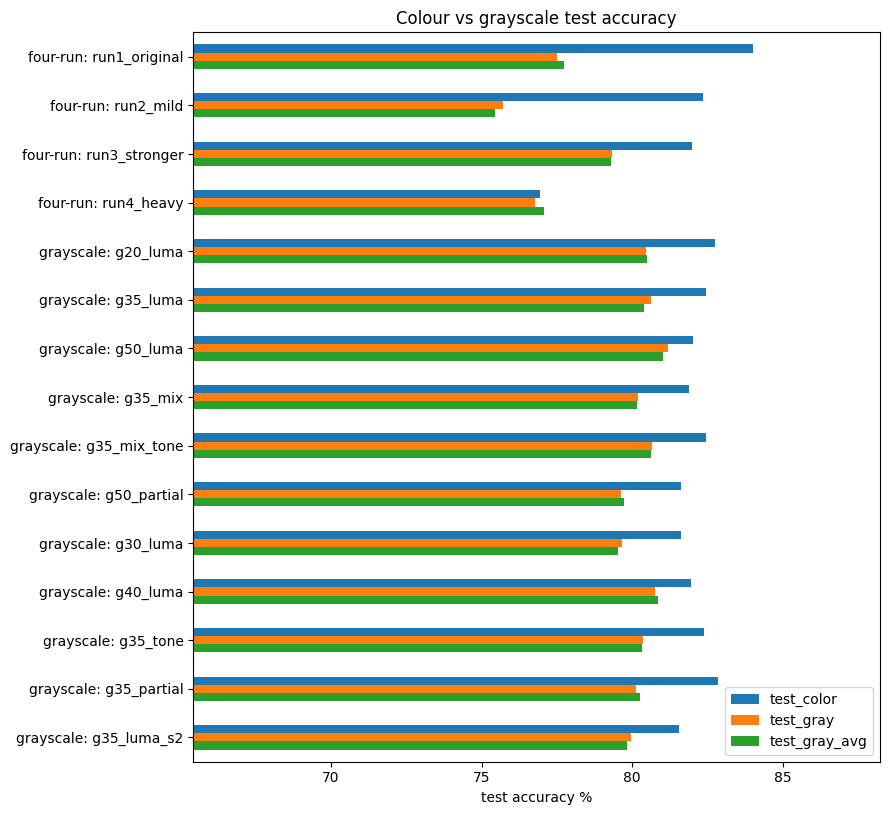

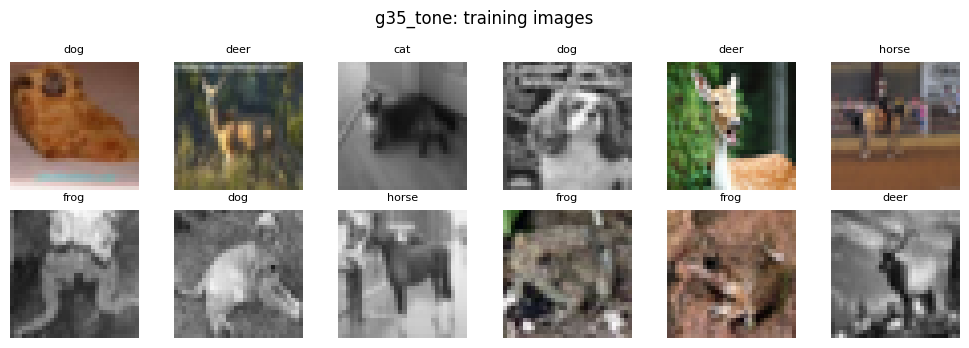

In [31]:
# [GRAYSCALE 5/5] Figures (saved to GRAY_DIR). Optional - skip if you only need the numbers.
require('gray_test', cell='GRAYSCALE 4/5')
ax = (gray_test[['test_color', 'test_gray', 'test_gray_avg']] * 100).plot.barh(figsize=(9, 0.45 * len(gray_test) + 1.5))
ax.set_xlabel('test accuracy %'); ax.set_xlim(left=max(0, gray_test.values[:, :3].min() * 100 - 10))
ax.invert_yaxis(); ax.set_title('Colour vs grayscale test accuracy'); plt.tight_layout()
plt.savefig(os.path.join(GRAY_DIR, 'color_vs_gray_accuracy.png'), dpi=120); plt.show()

# What the winning variant's training images look like (base augmentation + grayscale step).
tf.keras.utils.set_random_seed(GRAY_CFG['seed'])
_alter = make_alter(LEVELS[GRAY_BASE], seed=100 + list(LEVELS).index(GRAY_BASE))
_sx = make_gray_step(GRAY_VARIANTS[GRAY_BEST])(_alter(tf.constant(xtr[:12]))).numpy()
plt.figure(figsize=(10, 3.5))
for i in range(12):
    plt.subplot(2, 6, i + 1); plt.imshow(_sx[i]); plt.title(ANIMALS[ytr[i]], fontsize=8); plt.axis('off')
plt.suptitle(f'{GRAY_BEST}: training images'); plt.tight_layout()
plt.savefig(os.path.join(GRAY_DIR, f'{GRAY_BEST}_sample_images.png'), dpi=120); plt.show()

## Consistency training (method 2)

**Goal:** the model should give the same answer whether or not a shortcut is present, without losing accuracy.

The grayscale section above (method 3, "break the shortcut in the data") mixes grayscale images into training. The model learns to cope without colour, but nothing stops it from still trusting colour whenever colour is there. **Consistency training** shows the model each training image twice, as **view 1** (normal) and **view 2** (the shortcut removed or scrambled), and trains on

> loss = classification loss on both views + **λ ×** JS divergence(prediction on view 1, prediction on view 2)

The JS divergence is 0 when the two predictions are identical, so a large λ makes "answer differently when the shortcut changes" expensive.

| Family | View 1 | View 2 | Fixes |
|---|---|---|---|
| `col_gray_*` | colour image | grayscale | reliance on colour (compare with the grayscale section) |
| `col_mixed_*` | colour image | grayscale, channel swap or big hue shift | also being fooled by *wrong* colours (BGR test) |
| `patch_*` | shortcut data (class patch on 95% of images) | same image, patch turned grey | the injected patch shortcut |

Every λ = 12 variant has a **λ = 0 control** trained on exactly the same two views. The only difference is the consistency term, so comparing the pair shows what the term itself adds. Winners are picked on **validation** by worst-case accuracy within their family; the test set is used only for the scorecard (5/6).

Results go to `OUT_DIR/consistency/`. Each variant takes about twice as long as a normal run (two views per image), roughly 5–7 minutes on a Colab GPU, and is reloaded afterwards. Cell 5/6 needs `measure_pair` from **TRACK 1 · 4/7**.

In [32]:
# [CONSISTENCY 1/6] Settings, the variants to train, and fixed validation / test views.
# Edit CONS_CFG / CONS_VARIANTS here; re-run this cell and the consistency cells below it.
require('xtr', 'xval', 'yval', 'xte', 'yte', cell='SETUP 3/6'); require('LEVELS', 'make_alter', 'PERMS', cell='SETUP 4/6')
require('PATCH_COLORS', 'NEUTRAL', 'PATCH_SIZE', 'add_patch', 'tf_add_patch', 'xval_sc', cell='SHORTCUT 1/9')
CONS_CFG = dict(
    base_level='run1_original',  # same base augmentation as the grayscale section's winner, so they compare directly
    epochs=25, batch=64, seed=SEED,
    view2_ce_weight=1.0,         # weight of the usual classification loss on view 2 (view 1 always has weight 1)
    hue_shift=(0.25, 0.75),      # 'mixed' view: hue rotated by 90-270 degrees
)
CONS_VARIANTS = {  # lam = weight of the consistency term; lam=0 is the control (same two views, no consistency)
    # colour family - view 1: normal colour image, view 2: the same image with colour removed or scrambled
    'col_gray_l0':   dict(family='color', view2='gray',    lam=0.0),
    'col_gray_l12':  dict(family='color', view2='gray',    lam=12.0),
    'col_mixed_l0':  dict(family='color', view2='mixed',   lam=0.0),   # mixed = grayscale, channel swap or hue shift
    'col_mixed_l12': dict(family='color', view2='mixed',   lam=12.0),
    # patch family - trained on the shortcut data (class patch on 95% of images); view 2: patch turned grey
    'patch_l0':      dict(family='patch', view2='neutral', lam=0.0),
    'patch_l12':     dict(family='patch', view2='neutral', lam=12.0),
    # 'col_mixed_l12_s2': dict(family='color', view2='mixed', lam=12.0, seed=SEED + 1),  # noise check
}
CONS_DIR = os.path.join(OUT_DIR, 'consistency'); os.makedirs(CONS_DIR, exist_ok=True)
CONS_NC = len(ANIMALS)
FAMILY_CONDS = {'color': ['clean', 'gray', 'bgr'], 'patch': ['aligned', 'neutral', 'conflicting']}

def gray_np(x):
    return np.repeat(tf.image.rgb_to_grayscale(x).numpy(), 3, -1)

def condition_views(x, y):
    """The six test conditions for any image set (same definitions as the shortcut experiment and Track 1)."""
    return dict(clean=x, gray=gray_np(x), bgr=x[..., ::-1].copy(),
                aligned=add_patch(x, PATCH_COLORS[y]),
                neutral=add_patch(x, np.tile(NEUTRAL, (len(x), 1))),
                conflicting=add_patch(x, PATCH_COLORS[(y + 1) % CONS_NC]))

CONS_VAL_VIEWS = condition_views(xval, yval)    # used for early stopping checks and picking winners
CONS_TEST_VIEWS = condition_views(xte, yte)     # used only for the final scorecard
print(f'{len(CONS_VARIANTS)} variants: {list(CONS_VARIANTS)} | base level: {CONS_CFG["base_level"]}')

6 variants: ['col_gray_l0', 'col_gray_l12', 'col_mixed_l0', 'col_mixed_l12', 'patch_l0', 'patch_l12'] | base level: run1_original


In [33]:
# [CONSISTENCY 2/6] Second-view transforms, the consistency loss and the two-view model. Definitions only.
def tf_gray(x):
    return tf.repeat(tf.image.rgb_to_grayscale(x), 3, -1)

def tf_mixed(x):
    """Per image, one of: grayscale, a random channel swap, or a large hue rotation."""
    b = tf.shape(x)[0]
    swap = tf.einsum('bhwc,bcd->bhwd', x, tf.gather(PERMS, tf.random.uniform([b], 1, 6, dtype=tf.int32)))
    hsv = tf.image.rgb_to_hsv(x)
    h = tf.math.floormod(hsv[..., 0] + tf.random.uniform([b, 1, 1], *CONS_CFG['hue_shift']), 1.0)
    hue = tf.image.hsv_to_rgb(tf.stack([h, hsv[..., 1], hsv[..., 2]], -1))
    pick = tf.one_hot(tf.random.uniform([b], 0, 3, dtype=tf.int32), 3)[:, :, None, None, None]
    return tf.reduce_sum(tf.stack([tf_gray(x), swap, hue], 1) * pick, 1)

def tf_neutralise(x):
    """Paint the patch corner grey on every image (the patch, if any, no longer says anything)."""
    K, (H, W) = PATCH_SIZE, xtr.shape[1:3]
    region = tf.pad(tf.ones([K, K, 1], x.dtype), [[0, H - K], [0, W - K], [0, 0]])[None]
    return x * (1 - region) + tf.constant(NEUTRAL) * region

VIEW2 = {'gray': tf_gray, 'mixed': tf_mixed, 'neutral': tf_neutralise}

def js_div(p1, p2):
    """Jensen-Shannon divergence between two predicted distributions: 0 = identical predictions."""
    p1, p2 = tf.clip_by_value(p1, 1e-7, 1.0), tf.clip_by_value(p2, 1e-7, 1.0)
    m = 0.5 * (p1 + p2)
    return 0.5 * tf.reduce_sum(p1 * tf.math.log(p1 / m), -1) + 0.5 * tf.reduce_sum(p2 * tf.math.log(p2 / m), -1)

def make_cons_loss(lam, w2):
    """Classification loss on both views + lam x (how differently the model answers on the two views)."""
    def cons_loss(y, out):
        y = tf.reshape(tf.cast(y, tf.int32), [-1])
        p1, p2 = out[:, :CONS_NC], out[:, CONS_NC:]
        ce = (keras.losses.sparse_categorical_crossentropy(y, p1)
              + w2 * keras.losses.sparse_categorical_crossentropy(y, p2)) / (1 + w2)
        return ce + lam * js_div(p1, p2)
    return cons_loss

def _acc(y, p):
    return tf.cast(tf.equal(tf.reshape(tf.cast(y, tf.int64), [-1]), tf.argmax(p, -1)), tf.float32)
def acc_view1(y, out): return _acc(y, out[:, :CONS_NC])
def acc_view2(y, out): return _acc(y, out[:, CONS_NC:])
def js_gap(y, out):    return js_div(out[:, :CONS_NC], out[:, CONS_NC:])

def build_pair_model():
    """One shared CNN applied to both views. Only the shared CNN is saved, so it loads like every other model."""
    base = build_run_model()
    a, b = keras.Input((32, 32, 3), name='view1'), keras.Input((32, 32, 3), name='view2')
    return base, keras.Model([a, b], layers.Concatenate()([base(a), base(b)]))

In [34]:
# [CONSISTENCY 3/6] Train-or-load for one variant, and its validation scores. Definitions only.
def cons_val_scores(model):
    acc = {f'val_{k}': float((model.predict(v, batch_size=512, verbose=0).argmax(1) == yval).mean())
           for k, v in CONS_VAL_VIEWS.items()}
    for fam, conds in FAMILY_CONDS.items():
        acc[f'val_worst_{fam}'] = min(acc[f'val_{c}'] for c in conds)
    return acc

def train_or_load_cons(name, v):
    """Returns (model, results). Reloads when a saved model was trained with these exact settings."""
    vdir = os.path.join(CONS_DIR, name); os.makedirs(vdir, exist_ok=True)
    model_path, res_path = os.path.join(vdir, f'{name}_model.keras'), os.path.join(vdir, f'{name}_results.json')
    patch = v['family'] == 'patch'
    settings = json.loads(json.dumps(dict(v, **{k: CONS_CFG[k] for k in ('base_level', 'epochs', 'view2_ce_weight', 'hue_shift')},
                                          shortcut_p=SC_CFG['shortcut_p'] if patch else 0.0)))
    if not FORCE_RETRAIN and os.path.exists(model_path) and os.path.exists(res_path):
        res = json.load(open(res_path))
        if res.get('settings') == settings:
            print(f'{name}: saved model found -> loading (no retraining)')
            return keras.models.load_model(model_path), res
        print(f'{name}: settings changed since it was saved -> retraining')
    print(f'\n=== {name}: training, {settings} ===')
    view2, x1v = VIEW2[v['view2']], (xval_sc if patch else xval)
    tf.keras.utils.set_random_seed(CONS_CFG['seed'] + 5)          # fixed second view for validation
    x2v = np.concatenate([view2(tf.constant(x1v[i:i + 500])).numpy() for i in range(0, len(x1v), 500)])
    seed = v.get('seed', CONS_CFG['seed']); tf.keras.utils.set_random_seed(seed)
    base_level = CONS_CFG['base_level']
    alter = make_alter(LEVELS[base_level], seed=100 + list(LEVELS).index(base_level))
    p = SC_CFG['shortcut_p'] if patch else 0.0
    def make_pair(x, y):
        v1 = tf_add_patch(alter(x), y, p)                       # p = 0 -> no patch
        return (v1, view2(v1)), y
    ds = (tf.data.Dataset.from_tensor_slices((xtr, ytr)).shuffle(len(xtr), seed=seed)
          .batch(CONS_CFG['batch']).map(make_pair).prefetch(tf.data.AUTOTUNE))
    base, pair = build_pair_model()
    pair.compile(optimizer=keras.optimizers.Adam(1e-3), loss=make_cons_loss(v['lam'], CONS_CFG['view2_ce_weight']),
                 metrics=[acc_view1, acc_view2, js_gap])
    t0 = time.time()
    hist = pair.fit(ds, validation_data=((x1v, x2v), yval), epochs=CONS_CFG['epochs'], verbose=2, callbacks=[
        keras.callbacks.EarlyStopping('val_loss', patience=5, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau('val_loss', factor=0.5, patience=2, min_lr=1e-6)])
    save_model_atomic(base, model_path)
    history = {k: [float(x) for x in xs] for k, xs in hist.history.items()}
    res = dict(variant=name, settings=settings, epochs_trained=len(history['loss']),
               minutes=round((time.time() - t0) / 60, 1), **cons_val_scores(base), history=history)
    with open(res_path, 'w') as fh:
        json.dump(res, fh, indent=2)
    print(f'{name}: saved {model_path}')
    return base, res

In [35]:
# [CONSISTENCY 4/6] Train (or load) every variant, then pick each family's winner on VALIDATION only.
# Winner = best worst-case accuracy across the family's conditions (colour: clean/gray/bgr; patch: aligned/neutral/conflicting).
require('CONS_VARIANTS', cell='CONSISTENCY 1/6'); require('train_or_load_cons', cell='CONSISTENCY 3/6')
cons_models, cons_results = {}, {}
for name, v in CONS_VARIANTS.items():
    cons_models[name], cons_results[name] = train_or_load_cons(name, v)

val_cols = [f'val_{c}' for c in ['clean', 'gray', 'bgr', 'aligned', 'neutral', 'conflicting']]
cons_val_table = pd.DataFrame({n: {k: r[k] for k in val_cols + ['val_worst_color', 'val_worst_patch', 'epochs_trained']}
                               for n, r in cons_results.items()}).T
cons_val_table.to_csv(os.path.join(CONS_DIR, 'validation_summary.csv'))
CONS_BEST = {}
for fam in FAMILY_CONDS:
    names = [n for n, v in CONS_VARIANTS.items() if v['family'] == fam]
    if names:
        CONS_BEST[fam] = max(names, key=lambda n: cons_results[n][f'val_worst_{fam}'])
with open(os.path.join(CONS_DIR, 'best.json'), 'w') as fh:
    json.dump(dict(best_by_family=CONS_BEST, selected_on='worst-case validation accuracy within the family',
                   saved_at=time.strftime('%Y-%m-%d %H:%M:%S')), fh, indent=2)
print('Validation accuracy %:')
display((cons_val_table.drop(columns='epochs_trained') * 100).round(2))
print('Winners (validation only):', CONS_BEST)

col_gray_l0: saved model found -> loading (no retraining)
col_gray_l12: saved model found -> loading (no retraining)
col_mixed_l0: saved model found -> loading (no retraining)
col_mixed_l12: saved model found -> loading (no retraining)
patch_l0: saved model found -> loading (no retraining)
patch_l12: saved model found -> loading (no retraining)
Validation accuracy %:


,val_clean,val_gray,val_bgr,val_aligned,val_neutral,val_conflicting,val_worst_color,val_worst_patch
col_gray_l0,80.64,79.97,79.44,80.56,80.53,79.94,79.44,79.94
col_gray_l12,81.67,81.58,81.64,81.25,81.64,81.47,81.58,81.25
col_mixed_l0,79.69,79.72,79.56,79.42,79.50,79.42,79.56,79.42
col_mixed_l12,83.17,83.22,83.19,82.94,83.03,82.56,83.17,82.56
patch_l0,82.42,77.14,70.11,100.00,82.56,0.67,70.11,0.67
patch_l12,84.36,78.19,72.39,91.64,84.19,81.69,72.39,81.69


Winners (validation only): {'color': 'col_mixed_l12', 'patch': 'patch_l12'}


In [36]:
# [CONSISTENCY 5/6] TEST scorecard: consistency models vs the earlier models, all on the same 6,000 test images.
require('cons_models', cell='CONSISTENCY 4/6'); require('measure_pair', cell='TRACK 1 · 4/7')
cons_refs = {'four-run: run1_original': os.path.join(OUT_DIR, 'run1_original', 'run1_original_model.keras'),
             'four-run: run4_heavy': os.path.join(OUT_DIR, 'run4_heavy', 'run4_heavy_model.keras'),
             'shortcut: run1_original': os.path.join(OUT_DIR, 'shortcut_experiment', 'run1_original_shortcut.keras')}
_gbest = os.path.join(OUT_DIR, 'grayscale', 'best.json')
if os.path.exists(_gbest):
    _g = json.load(open(_gbest))['variant']
    cons_refs[f'grayscale: {_g}'] = os.path.join(OUT_DIR, 'grayscale', _g, f'{_g}_model.keras')
CONS_PAIRS = {'color_vs_gray': ('clean', 'gray'), 'color_vs_bgr': ('clean', 'bgr'), 'patch_vs_neutral': ('aligned', 'neutral')}

def score_model(model):
    probs = {k: model.predict(x, batch_size=512, verbose=0) for k, x in CONS_TEST_VIEWS.items()}
    row = {f'acc_{k}': float((p.argmax(1) == yte).mean()) for k, p in probs.items()}
    for fam, conds in FAMILY_CONDS.items():
        row[f'worst_{fam}'] = min(row[f'acc_{c}'] for c in conds)
    for pname, (a, b) in CONS_PAIRS.items():
        s, _ = measure_pair(probs[a], probs[b], yte, np.arange(len(yte)))
        row[f'{pname}_mean_delta'] = s['mean_delta']
        row[f'{pname}_correct_to_wrong'] = s['flipped_correct_to_wrong']
    return row

cons_score_rows = {}
for tag, path in cons_refs.items():
    if os.path.exists(path):
        m = keras.models.load_model(path); cons_score_rows[tag] = score_model(m); del m
    else:
        print('reference not found, skipped:', tag)
for name, m in cons_models.items():
    cons_score_rows[f'consistency: {name}'] = score_model(m)
cons_scores = pd.DataFrame(cons_score_rows).T

CONS_RUN_DIR = os.path.join(CONS_DIR, 'scorecards', time.strftime('%Y-%m-%d_%H%M%S')); os.makedirs(CONS_RUN_DIR)
cons_scores.to_csv(os.path.join(CONS_RUN_DIR, 'scorecard.csv'))
with open(os.path.join(CONS_RUN_DIR, 'scorecard.json'), 'w') as fh:
    json.dump(dict(n_test_images=int(len(yte)), conditions=list(CONS_TEST_VIEWS), family_conditions=FAMILY_CONDS,
                   pairs=CONS_PAIRS, winners=CONS_BEST, variants=CONS_VARIANTS, cfg=CONS_CFG,
                   models={k: {c: float(x) for c, x in r.items()} for k, r in cons_score_rows.items()}), fh, indent=1)
print(f'Scored {len(cons_scores)} models on {len(yte)} test images -> {CONS_RUN_DIR}')

Scored 10 models on 6000 test images -> /content/drive/MyDrive/cifar10_animal_runs/consistency/scorecards/2026-11-09_215407


In [37]:
# [CONSISTENCY 6/6] Report: accuracy per condition, worst case, and how much each shortcut still matters.
require('cons_scores', cell='CONSISTENCY 5/6')
acc_cols = ['acc_clean', 'acc_gray', 'acc_bgr', 'acc_aligned', 'acc_neutral', 'acc_conflicting']
print(f'Test accuracy % per condition ({len(yte):,} images each):')
display((cons_scores[acc_cols + ['worst_color', 'worst_patch']] * 100).round(2))
n = len(yte)
print(f'Shortcut reliance: mean Δ (P(true) with − without) and correct→wrong flips out of {n}:')
rel = cons_scores[[c for c in cons_scores.columns if c.endswith(('_mean_delta', '_correct_to_wrong'))]].copy()
for c in rel.columns:
    rel[c] = rel[c].round(3) if c.endswith('_mean_delta') else rel[c].astype(int)
display(rel)

def _line(tag):
    r = cons_scores.loc[tag]
    return (f"{tag:34s} clean {r.acc_clean:.1%} | gray {r.acc_gray:.1%} | bgr {r.acc_bgr:.1%} | "
            f"worst colour {r.worst_color:.1%} | worst patch {r.worst_patch:.1%}")
print('\nWinners (picked on validation) next to their lam=0 controls:')
for fam, name in CONS_BEST.items():
    ctrl = name.rsplit('_l', 1)[0] + '_l0'
    for tag in dict.fromkeys([f'consistency: {name}', f'consistency: {ctrl}']):
        if tag in cons_scores.index:
            print(_line(tag))
print('References:')
for tag in [t for t in cons_scores.index if not t.startswith('consistency')]:
    print(_line(tag))

Test accuracy % per condition (6,000 images each):


,acc_clean,acc_gray,acc_bgr,acc_aligned,acc_neutral,acc_conflicting,worst_color,worst_patch
four-run: run1_original,84.02,77.52,72.47,83.97,83.90,82.85,72.47,82.85
four-run: run4_heavy,76.95,76.78,76.78,76.58,76.80,76.60,76.78,76.58
shortcut: run1_original,67.08,62.83,55.62,100.00,67.03,0.25,55.62,0.25
grayscale: g35_tone,82.37,80.37,76.40,81.85,82.27,82.18,76.40,81.85
consistency: col_gray_l0,80.25,79.38,78.33,79.53,79.75,79.15,78.33,79.15
consistency: col_gray_l12,82.25,82.23,81.98,82.00,81.98,81.85,81.98,81.85
consistency: col_mixed_l0,79.70,79.22,79.25,79.42,79.30,79.08,79.22,79.08
consistency: col_mixed_l12,82.65,82.82,82.65,82.05,82.28,82.02,82.65,82.02
consistency: patch_l0,82.38,76.48,69.85,99.98,82.37,0.83,69.85,0.83
consistency: patch_l12,83.68,77.87,70.22,90.95,83.78,81.13,70.22,81.13


Shortcut reliance: mean Δ (P(true) with − without) and correct→wrong flips out of 6000:


,color_vs_gray_mean_delta,color_vs_gray_correct_to_wrong,color_vs_bgr_mean_delta,color_vs_bgr_correct_to_wrong,patch_vs_neutral_mean_delta,patch_vs_neutral_correct_to_wrong
four-run: run1_original,0.069,579,0.119,885,0.001,81
four-run: run4_heavy,-0.001,58,0.001,49,-0.002,37
shortcut: run1_original,0.058,553,0.117,1067,0.437,1978
grayscale: g35_tone,0.022,234,0.069,519,-0.003,54
consistency: col_gray_l0,0.013,184,0.026,278,-0.003,40
consistency: col_gray_l12,0.002,32,0.003,73,-0.001,50
consistency: col_mixed_l0,0.004,101,0.004,84,0.001,50
consistency: col_mixed_l12,0.001,46,0.001,25,-0.001,27
consistency: patch_l0,0.069,584,0.137,989,0.225,1057
consistency: patch_l12,0.070,534,0.144,984,0.067,430



Winners (picked on validation) next to their lam=0 controls:
consistency: col_mixed_l12         clean 82.7% | gray 82.8% | bgr 82.7% | worst colour 82.7% | worst patch 82.0%
consistency: col_mixed_l0          clean 79.7% | gray 79.2% | bgr 79.2% | worst colour 79.2% | worst patch 79.1%
consistency: patch_l12             clean 83.7% | gray 77.9% | bgr 70.2% | worst colour 70.2% | worst patch 81.1%
consistency: patch_l0              clean 82.4% | gray 76.5% | bgr 69.8% | worst colour 69.8% | worst patch 0.8%
References:
four-run: run1_original            clean 84.0% | gray 77.5% | bgr 72.5% | worst colour 72.5% | worst patch 82.8%
four-run: run4_heavy               clean 77.0% | gray 76.8% | bgr 76.8% | worst colour 76.8% | worst patch 76.6%
shortcut: run1_original            clean 67.1% | gray 62.8% | bgr 55.6% | worst colour 55.6% | worst patch 0.2%
grayscale: g35_tone                clean 82.4% | gray 80.4% | bgr 76.4% | worst colour 76.4% | worst patch 81.8%


---
## Final pipeline: image → prediction → ablation → Shortcut Reliance Score → Grad-CAM

Connects every part of the project into one flow. For each image (uploaded, a file path, or sample test images) it runs four models:

| Role | Model |
|---|---|
| Original | `run1_original` (no augmentation) |
| Mitigated, colour | consistency winner for colour (`best.json`) |
| Original, patch shortcut | the model trained with the class-coded corner patch |
| Mitigated, patch | consistency winner for the patch |

**What each model gets:**

- **Prediction:** the predicted class and its confidence.
- **Ablation:** the cue is removed or contradicted, using grayscale, 5 channel swaps, a grey patch and the 5 wrong-class patches.
- **Shortcut Reliance Score (SRS, 0–100):** how often altering the cue changes the answer. The reference is the model's own answer on the unaltered image, so no label is needed.
  - **Colour SRS:** % of the 6 colour ablations that change the prediction.
  - **Patch SRS:** % of the 5 wrong-class patches that switch the prediction to the patch's class.
- **Grad-CAM:** heatmaps on the clean, grayscale, BGR and wrong-patch versions, plus how much attention lands on the patch corner.

**Outputs:**

- **Per image:** `OUT_DIR/pipeline/<image>/report.png` and `report.json`.
- **Whole test set:** cells 8–9 run the same measurements on every saved model, saved to `OUT_DIR/pipeline/final_eval.*`, which feeds the final figures.
- **One image later:** `run_pipeline('/path/to/image.jpg')`.

The models were trained on 32×32 CIFAR images. Any photo is centre-cropped and shrunk to 32×32 first, so predictions on everyday photos are less reliable than on test images.

In [38]:
# [PIPELINE 1/9] Settings for the end-to-end pipeline and where the final outputs go.
# Runtime -> Run all runs the whole project top to bottom; saved models load, so nothing retrains.
require('OUT_DIR', 'SEED', 'ANIMALS', cell='SETUP 1/6')
PIPE_CFG = dict(
    image_paths=[],         # e.g. ['/content/my_cat.jpg']; leave empty to upload in Colab
    upload_in_colab=True,   # with no image_paths: ask for an upload in Colab (falls back to sample test images)
    repo_dir=None,          # your git clone, e.g. '/content/<repo>'; None = auto-detect, else save under OUT_DIR
    srs_per_class=200,      # test images per class for the dataset-level Shortcut Reliance Score
    gradcam_per_class=50,   # test images per class for the Grad-CAM attention statistics
    dpi=200,                # resolution of saved figures
)
NCLS = len(ANIMALS)

def _find_repo(start):
    d = os.path.abspath(start)
    while d != os.path.dirname(d):
        if os.path.isdir(os.path.join(d, '.git')):
            return d
        d = os.path.dirname(d)
    return None

REPO_DIR = PIPE_CFG['repo_dir'] or _find_repo(os.getcwd())
if REPO_DIR is None:
    REPO_DIR = os.path.join(OUT_DIR, 'repo_export')
    print(f'No git repository found: figures go to {REPO_DIR}/docs/final_figures. '
          "Set PIPE_CFG['repo_dir'] to your clone to save them straight into the repo.")
FINAL_FIG_DIR = os.path.join(REPO_DIR, 'docs', 'final_figures')
FINAL_DATA_DIR = os.path.join(FINAL_FIG_DIR, 'data')
PIPE_DIR = os.path.join(OUT_DIR, 'pipeline')
for d in (FINAL_FIG_DIR, FINAL_DATA_DIR, PIPE_DIR):
    os.makedirs(d, exist_ok=True)
print('Final figures ->', FINAL_FIG_DIR, '\nPipeline reports ->', PIPE_DIR)

No git repository found: figures go to /content/drive/MyDrive/cifar10_animal_runs/repo_export/docs/final_figures. Set PIPE_CFG['repo_dir'] to your clone to save them straight into the repo.
Final figures -> /content/drive/MyDrive/cifar10_animal_runs/repo_export/docs/final_figures 
Pipeline reports -> /content/drive/MyDrive/cifar10_animal_runs/pipeline


In [39]:
# [PIPELINE 2/9] Model roster: every saved model the pipeline and figures use, checked before anything runs.
import re
def _p(*parts): return os.path.join(OUT_DIR, *parts)

def cons_label(n):
    m = re.search(r'_s(\d+)$', n); seed = f', seed {m.group(1)}' if m else ''
    kind, lam = (n[:m.start()] if m else n).rsplit('_l', 1)
    view = {'col_gray': 'gray view', 'col_mixed': 'mixed-colour view', 'patch': 'grey-patch view'}.get(kind, kind)
    return f'Consistency ({view}, λ={lam}{seed})'

ROSTER = {}   # label -> path, family, role
def _add(label, path, family, role):
    ROSTER[label] = dict(path=path, family=family, role=role, found=os.path.exists(path))

for lvl, lab in [('run1_original', 'Original (run1, no aug)'), ('run2_mild', 'Mild aug (run2)'),
                 ('run3_stronger', 'Stronger aug (run3)'), ('run4_heavy', 'Heavy aug (run4)')]:
    _add(lab, _p(lvl, f'{lvl}_model.keras'), 'colour', 'original' if lvl == 'run1_original' else 'augmentation')
_add('Patch-shortcut model', _p('shortcut_experiment', 'run1_original_shortcut.keras'), 'patch', 'original')
if os.path.exists(_p('grayscale', 'best.json')):
    g = json.load(open(_p('grayscale', 'best.json')))['variant']
    _add(f'Grayscale aug ({g})', _p('grayscale', g, f'{g}_model.keras'), 'colour', 'mitigation: data')
CONS_WINNERS = (json.load(open(_p('consistency', 'best.json')))['best_by_family']
                if os.path.exists(_p('consistency', 'best.json')) else {})
for n in sorted(os.listdir(_p('consistency'))) if os.path.isdir(_p('consistency')) else []:
    if os.path.exists(_p('consistency', n, f'{n}_model.keras')):
        _add(cons_label(n), _p('consistency', n, f'{n}_model.keras'), 'patch' if n.startswith('patch') else 'colour',
             'mitigation: consistency' if n in CONS_WINNERS.values() else 'ablation')

ORIGINAL_COLOUR, ORIGINAL_PATCH = 'Original (run1, no aug)', 'Patch-shortcut model'
MITIGATED_COLOUR = cons_label(CONS_WINNERS['color']) if 'color' in CONS_WINNERS else None
MITIGATED_PATCH = cons_label(CONS_WINNERS['patch']) if 'patch' in CONS_WINNERS else None
PIPE_MODEL_LABELS = [ORIGINAL_COLOUR, MITIGATED_COLOUR, ORIGINAL_PATCH, MITIGATED_PATCH]
display(pd.DataFrame(ROSTER).T[['family', 'role', 'found']])
missing = [l for l in PIPE_MODEL_LABELS if l is None or not ROSTER.get(l, {}).get('found')]
if missing:
    raise FileNotFoundError(f'Pipeline models missing: {missing}. Run the four-run, shortcut and consistency sections '
                            '(they train once and save to Drive), then re-run this cell.')
print('Pipeline models:', PIPE_MODEL_LABELS)

,family,role,found
"Original (run1, no aug)",colour,original,True
Mild aug (run2),colour,augmentation,True
Stronger aug (run3),colour,augmentation,True
Heavy aug (run4),colour,augmentation,True
Patch-shortcut model,patch,original,True
Grayscale aug (g35_tone),colour,mitigation: data,True
"Consistency (gray view, λ=0)",colour,ablation,True
"Consistency (gray view, λ=12)",colour,ablation,True
"Consistency (mixed-colour view, λ=0)",colour,ablation,True
"Consistency (mixed-colour view, λ=12)",colour,mitigation: consistency,True


Pipeline models: ['Original (run1, no aug)', 'Consistency (mixed-colour view, λ=12)', 'Patch-shortcut model', 'Consistency (grey-patch view, λ=12)']


In [40]:
# [PIPELINE 3/9] Ablations and the Shortcut Reliance Score (SRS). Definitions only.
# SRS needs no labels: the reference is the model's own answer on the unaltered image.
#   SRS colour = % of 6 colour ablations (grayscale + 5 channel swaps) that change the answer
#   SRS patch  = % of the 5 wrong-class patches that pull the answer to the patch's class
# 0 = the cue never changes the answer; 100 = the cue always decides it.
require('add_patch', 'PATCH_COLORS', 'NEUTRAL', 'PATCH_SIZE', cell='SHORTCUT 1/9')
COLOUR_ABLATIONS = {'grayscale': None, 'swap RBG': (0, 2, 1), 'swap GRB': (1, 0, 2),
                    'swap GBR': (1, 2, 0), 'swap BRG': (2, 0, 1), 'swap BGR': (2, 1, 0)}

def colour_ablate(x, name):
    if COLOUR_ABLATIONS[name] is None:
        return np.repeat(tf.image.rgb_to_grayscale(x).numpy(), 3, -1)
    return x[..., list(COLOUR_ABLATIONS[name])].copy()

def patch_with(x, cls):
    return add_patch(x, np.tile(PATCH_COLORS[cls], (len(x), 1)))

def shortcut_reliance(model, x, batch=512):
    """Per-image SRS for a batch x (N,32,32,3). Also returns confidence drops (percentage points)."""
    P = lambda z: model.predict(z, batch_size=batch, verbose=0)
    ar = np.arange(len(x))
    p0 = P(x); ref = p0.argmax(1); c0 = p0[ar, ref]
    colour_probs = {k: P(colour_ablate(x, k)) for k in COLOUR_ABLATIONS}
    changed = np.mean([p.argmax(1) != ref for p in colour_probs.values()], 0)
    c_drop = np.mean([c0 - p[ar, ref] for p in colour_probs.values()], 0)
    patch_probs = {k: P(patch_with(x, k)) for k in range(NCLS)}
    other = [ref != k for k in range(NCLS)]
    hijack = np.sum([o & (patch_probs[k].argmax(1) == k) for k, o in enumerate(other)], 0) / (NCLS - 1)
    p_drop = np.sum([np.where(o, c0 - patch_probs[k][ar, ref], 0) for k, o in enumerate(other)], 0) / (NCLS - 1)
    neutral = P(add_patch(x, np.tile(NEUTRAL, (len(x), 1))))
    return dict(ref=ref, ref_conf=c0, probs_clean=p0, colour_probs=colour_probs, patch_probs=patch_probs,
                srs_colour=100 * changed, srs_patch=100 * hijack,
                colour_conf_drop=100 * c_drop, patch_conf_drop=100 * p_drop,
                occlusion_changed=neutral.argmax(1) != ref)

In [41]:
# [PIPELINE 4/9] Grad-CAM: which pixels drove the prediction. Definitions only.
import weakref
_GRADCAM_MODELS = weakref.WeakKeyDictionary()

def gradcam(model, x, class_idx=None, batch=128):
    """Heatmaps (N,32,32) scaled to [0,1], from the last conv layer, for class_idx (default: the prediction)."""
    if model not in _GRADCAM_MODELS:
        conv = [l for l in model.layers if isinstance(l, layers.Conv2D)][-1]
        _GRADCAM_MODELS[model] = keras.Model(model.inputs, [conv.output, model.outputs[0]])
    gm, out = _GRADCAM_MODELS[model], []
    idx_all = None if class_idx is None else np.broadcast_to(np.asarray(class_idx), (len(x),))
    for i in range(0, len(x), batch):
        xb = tf.constant(x[i:i + batch])
        with tf.GradientTape() as tape:
            conv_out, probs = gm(xb, training=False)
            idx = (tf.argmax(probs, 1, output_type=tf.int32) if idx_all is None
                   else tf.constant(idx_all[i:i + batch], tf.int32))
            score = tf.math.log(tf.gather(probs, idx, batch_dims=1) + 1e-9)   # log-prob: avoids saturated gradients
        grads = tape.gradient(score, conv_out)
        cam = tf.nn.relu(tf.reduce_sum(tf.reduce_mean(grads, (1, 2), keepdims=True) * conv_out, -1))
        cam = tf.image.resize(cam[..., None], x.shape[1:3], 'bilinear')[..., 0]
        out.append((cam / (tf.reduce_max(cam, (1, 2), keepdims=True) + 1e-9)).numpy())
    return np.concatenate(out)

def patch_attention(cam):
    """Grad-CAM share on the patch corner divided by the corner's share of the image (1 = no special attention)."""
    k = PATCH_SIZE
    share = cam[:, :k, :k].sum((1, 2)) / (cam.sum((1, 2)) + 1e-9)
    return share / (k * k / (cam.shape[1] * cam.shape[2]))

def cam_panel(ax, img, cam, title, color='black'):
    ax.imshow(img, interpolation='nearest')
    ax.imshow(cam, cmap='jet', alpha=0.45, vmin=0, vmax=1, interpolation='bilinear')
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title, fontsize=9, color=color)

In [42]:
# [PIPELINE 5/9] Getting images in: uploads, file paths, or (if neither) one sample test image per class.
# Definitions only. Any size or format works; images are centre-cropped to a square and resized to 32x32.
from PIL import Image

def load_image_32(path):
    im = Image.open(path).convert('RGB'); w, h = im.size; s = min(w, h)
    sq = im.crop(((w - s) // 2, (h - s) // 2, (w - s) // 2 + s, (h - s) // 2 + s))
    return np.asarray(sq.resize((32, 32), Image.BICUBIC), 'float32') / 255.0, np.asarray(sq)

def get_pipeline_images():
    paths = list(PIPE_CFG['image_paths'])
    if not paths and PIPE_CFG['upload_in_colab']:
        try:
            from google.colab import files
            print('Choose image(s) to analyse (or cancel to use sample test images):')
            up_dir = os.path.join(PIPE_DIR, 'uploads'); os.makedirs(up_dir, exist_ok=True)
            for fname, data in files.upload().items():
                paths.append(os.path.join(up_dir, fname))
                with open(paths[-1], 'wb') as fh:
                    fh.write(data)
        except ImportError:
            pass                                     # not in Colab
    images = {}
    for p in paths:
        x, full = load_image_32(p)
        images[os.path.splitext(os.path.basename(p))[0]] = dict(x=x, full=full, source=p, true=None)
    if not images:
        rng = np.random.default_rng(SEED + 11)
        for c in range(NCLS):
            i = int(rng.choice(np.where(yte == c)[0]))
            images[f'test{i}_{ANIMALS[c]}'] = dict(x=xte[i], full=(xte[i] * 255).astype('uint8'),
                                                   source=f'test image {i}', true=ANIMALS[c])
        print('No images given: using one sample test image per class.')
    return images

In [43]:
# [PIPELINE 6/9] Full analysis of one image: predictions, ablations, SRS and Grad-CAM for each model. Definitions only.
def analyse_image(name, item, models):
    x, out_dir = item['x'][None], os.path.join(PIPE_DIR, name)
    os.makedirs(out_dir, exist_ok=True)
    pred0 = int(models[ORIGINAL_COLOUR].predict(x, verbose=0).argmax())
    wrong = next(c for c in [(pred0 + k) % NCLS for k in range(1, NCLS)] if ANIMALS[c] != item['true'])  # not the answer, not the truth
    views = {'Clean': x, 'Grayscale': colour_ablate(x, 'grayscale'), 'BGR swap': colour_ablate(x, 'swap BGR'),
             f'Wrong patch ({ANIMALS[wrong]})': patch_with(x, wrong)}
    report = dict(image=name, source=item['source'], true_label=item['true'], models={})
    fig = plt.figure(figsize=(17, 3.2 * len(models)))
    gs = fig.add_gridspec(len(models), 6, width_ratios=[1.3, 1, 1, 1, 1, 1.4])
    axf = fig.add_subplot(gs[:, 0]); axf.imshow(item['full']); axf.axis('off')
    axf.set_title('Input' + (f"\ntrue class: {item['true']}" if item['true'] else ''))
    for r, (label, m) in enumerate(models.items()):
        s = shortcut_reliance(m, x)
        rec = dict(prediction=ANIMALS[s['ref'][0]], confidence=float(s['ref_conf'][0]),
                   probs=dict(zip(ANIMALS, map(float, s['probs_clean'][0]))),
                   srs_colour=float(s['srs_colour'][0]), srs_patch=float(s['srs_patch'][0]),
                   colour_conf_drop_pp=float(s['colour_conf_drop'][0]), patch_conf_drop_pp=float(s['patch_conf_drop'][0]),
                   grey_patch_changes_answer=bool(s['occlusion_changed'][0]),
                   colour_ablation={k: ANIMALS[int(p[0].argmax())] for k, p in s['colour_probs'].items()},
                   patch_ablation={ANIMALS[k]: ANIMALS[int(p[0].argmax())] for k, p in s['patch_probs'].items()}, views={})
        for c, (vname, xv) in enumerate(views.items()):
            p, cam = m.predict(xv, verbose=0)[0], gradcam(m, xv)[0]
            rec['views'][vname] = dict(pred=ANIMALS[int(p.argmax())], conf=float(p.max()),
                                       patch_attention=float(patch_attention(cam[None])[0]))
            cam_panel(fig.add_subplot(gs[r, c + 1]), xv[0], cam, f'{vname}\n→ {ANIMALS[int(p.argmax())]} ({p.max():.0%})')
        axt = fig.add_subplot(gs[r, 5]); axt.axis('off')
        axt.text(0, 0.5, f"{label}\n\nprediction: {rec['prediction']} ({rec['confidence']:.0%})\n"
                 f"SRS colour: {rec['srs_colour']:.0f}/100\nSRS patch:  {rec['srs_patch']:.0f}/100\n"
                 f"conf. drop, colour: {rec['colour_conf_drop_pp']:+.1f} pp\nconf. drop, patch:  {rec['patch_conf_drop_pp']:+.1f} pp",
                 va='center', fontsize=9, family='monospace', wrap=True)
        report['models'][label] = rec
    fig.suptitle(f'Pipeline report: {name}  (heatmap = Grad-CAM, red = most influence on the prediction)', fontsize=13)
    fig.tight_layout(); fig.savefig(os.path.join(out_dir, 'report.png'), dpi=PIPE_CFG['dpi'], bbox_inches='tight', facecolor='white')
    with open(os.path.join(out_dir, 'report.json'), 'w') as fh:
        json.dump(report, fh, indent=1)
    return report, fig

Choose image(s) to analyse (or cancel to use sample test images):


No images given: using one sample test image per class.


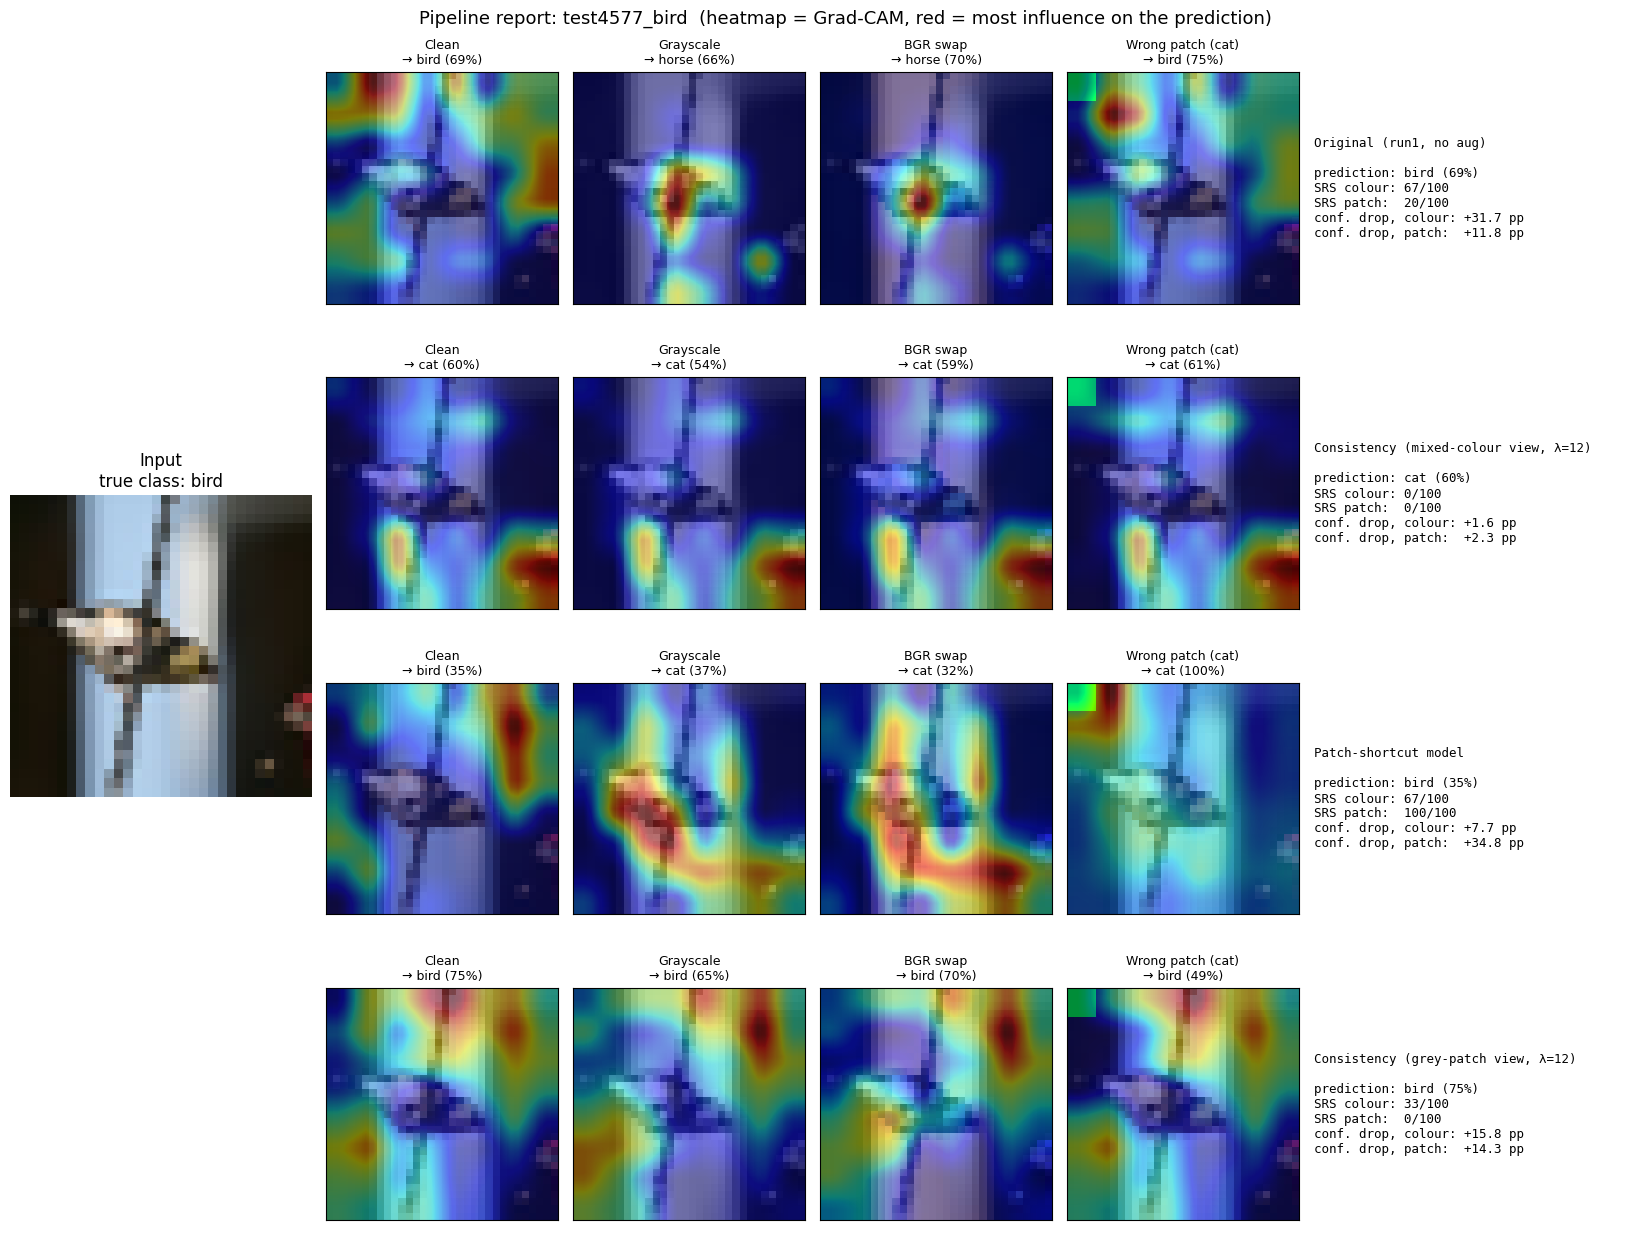

saved /content/drive/MyDrive/cifar10_animal_runs/pipeline/test4577_bird/report.png + report.json


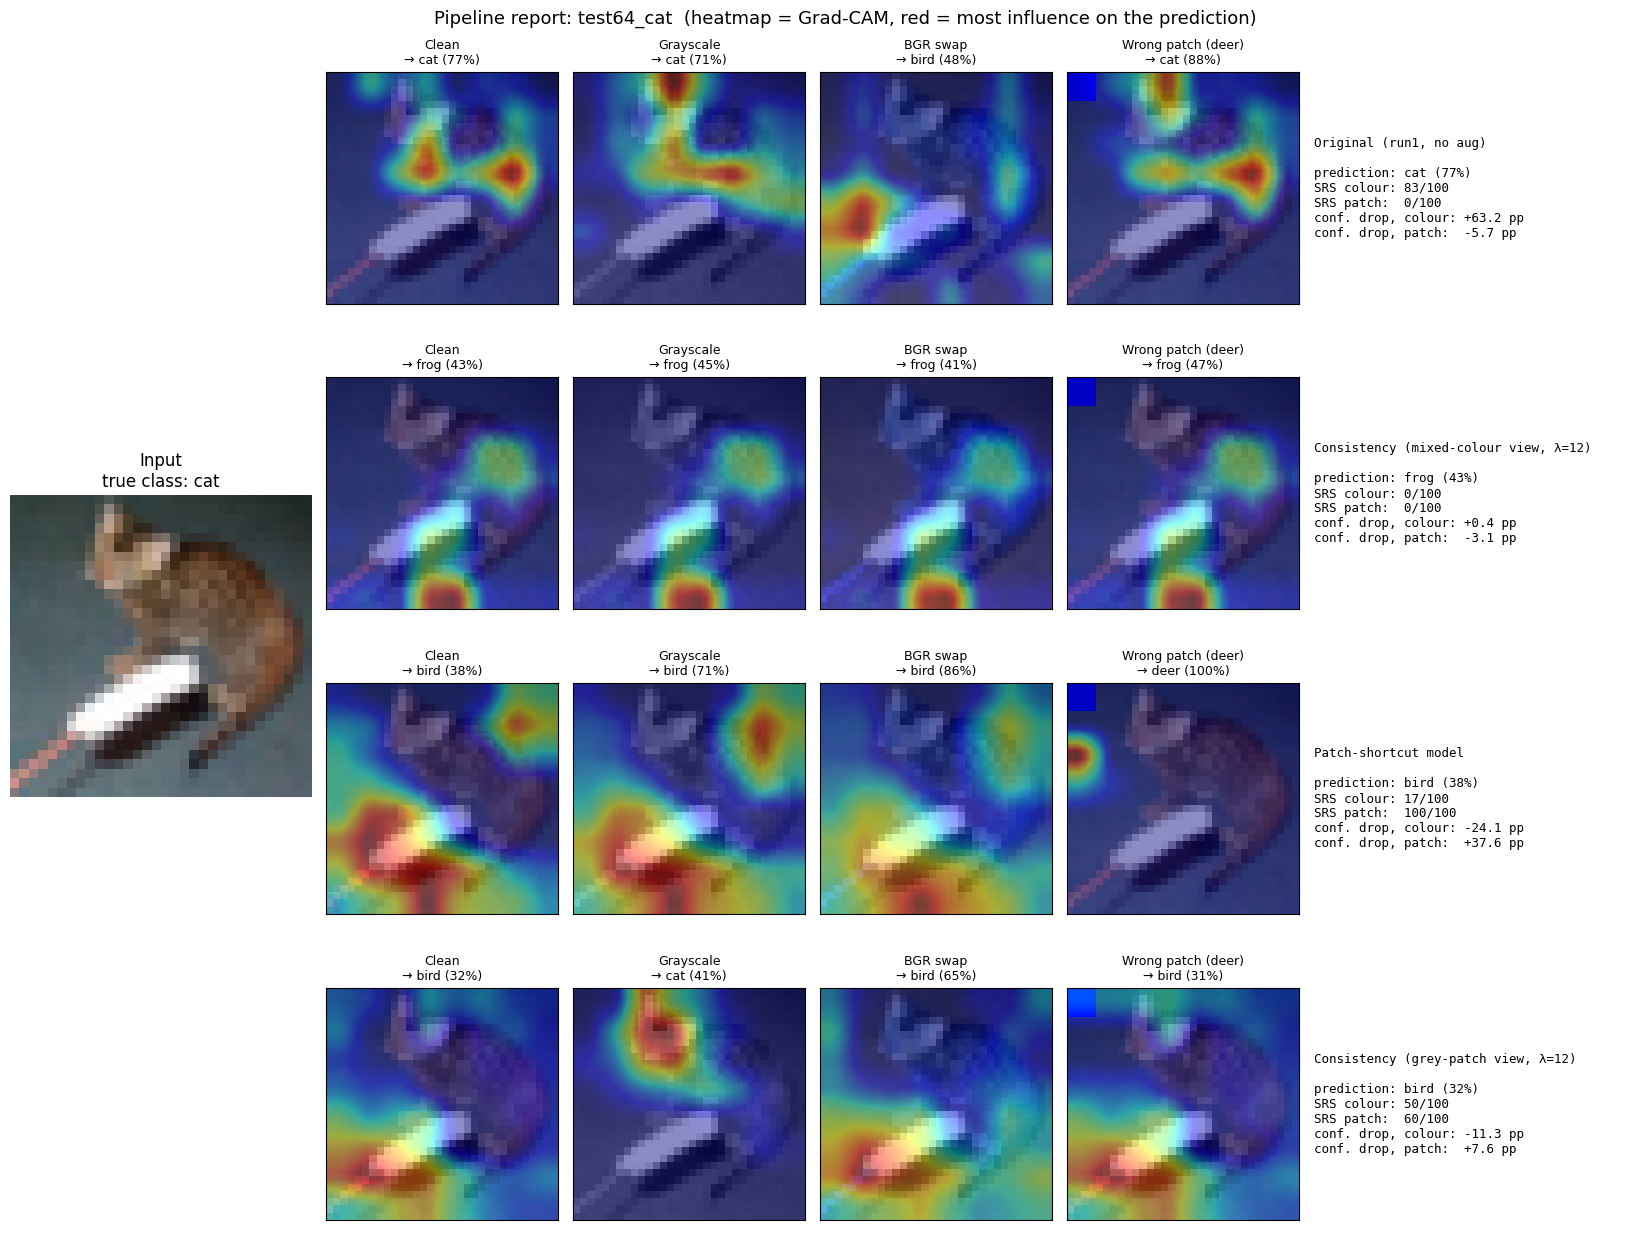

saved /content/drive/MyDrive/cifar10_animal_runs/pipeline/test64_cat/report.png + report.json


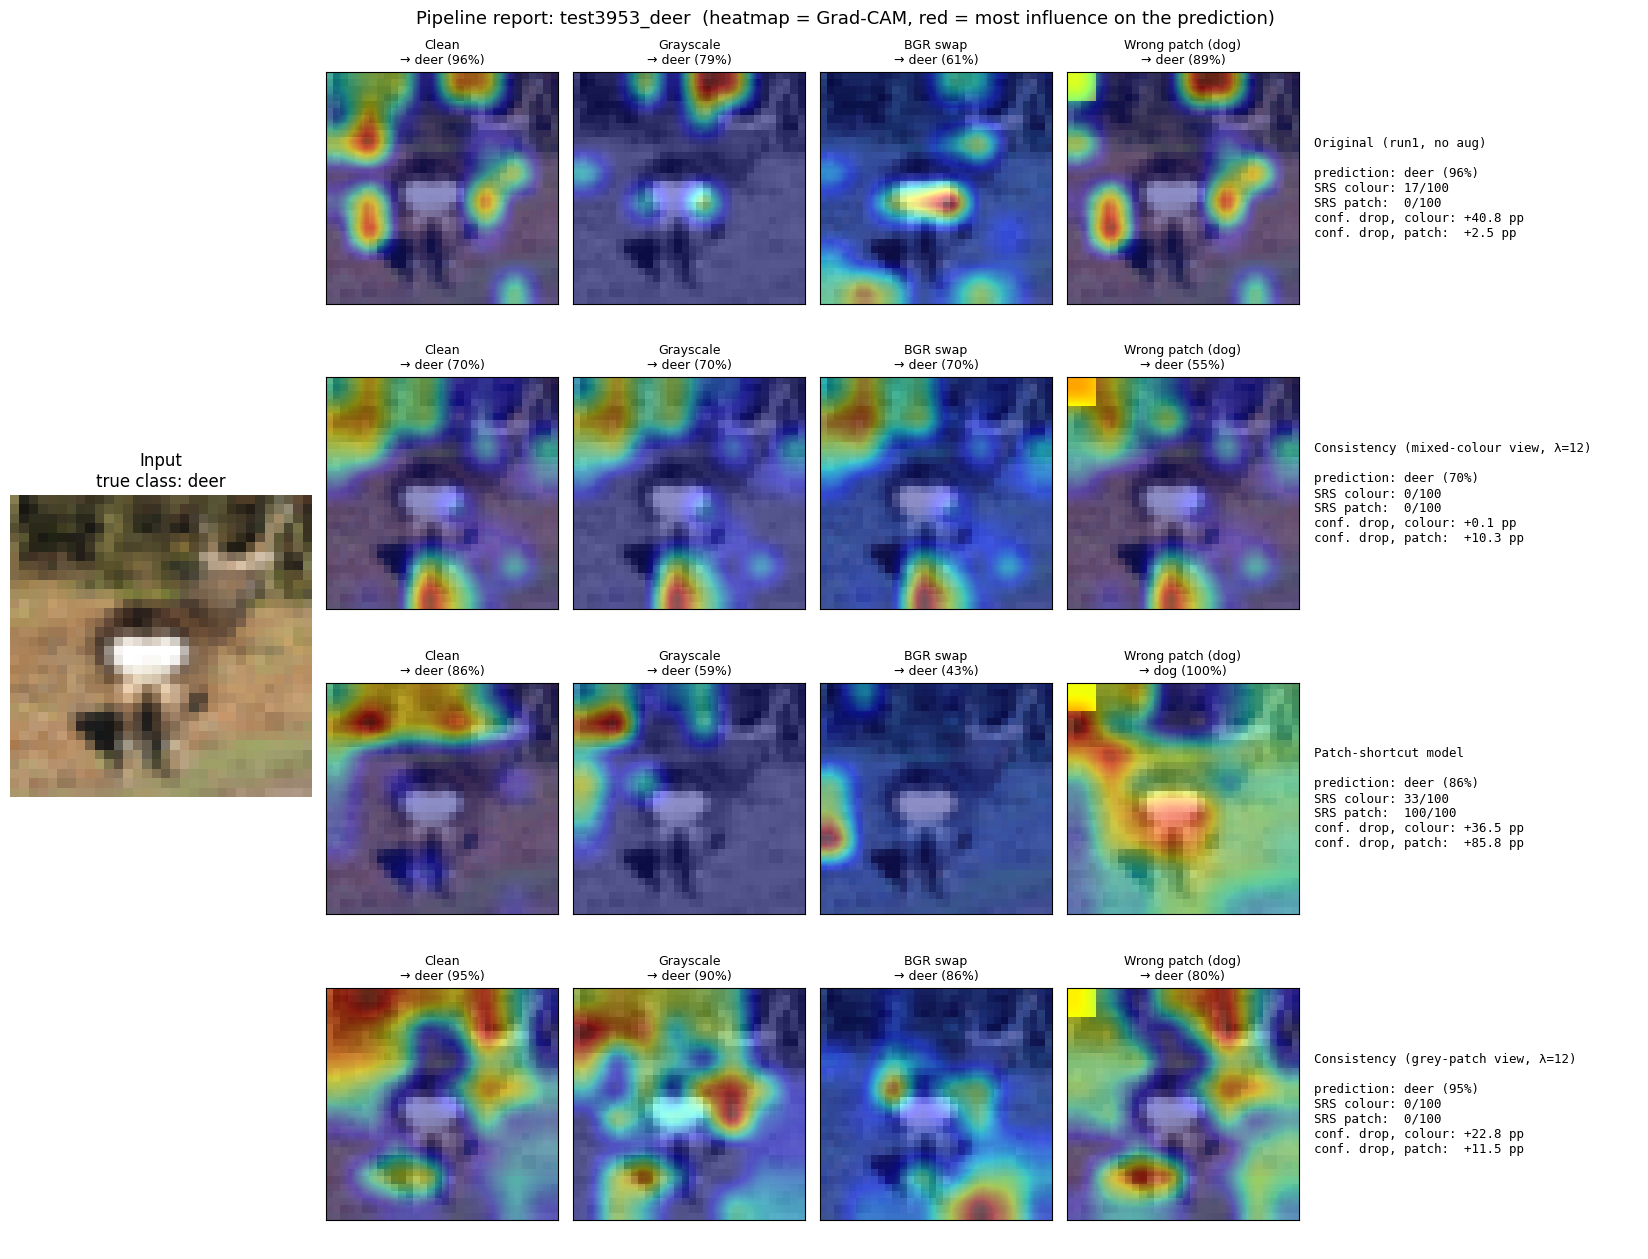

saved /content/drive/MyDrive/cifar10_animal_runs/pipeline/test3953_deer/report.png + report.json


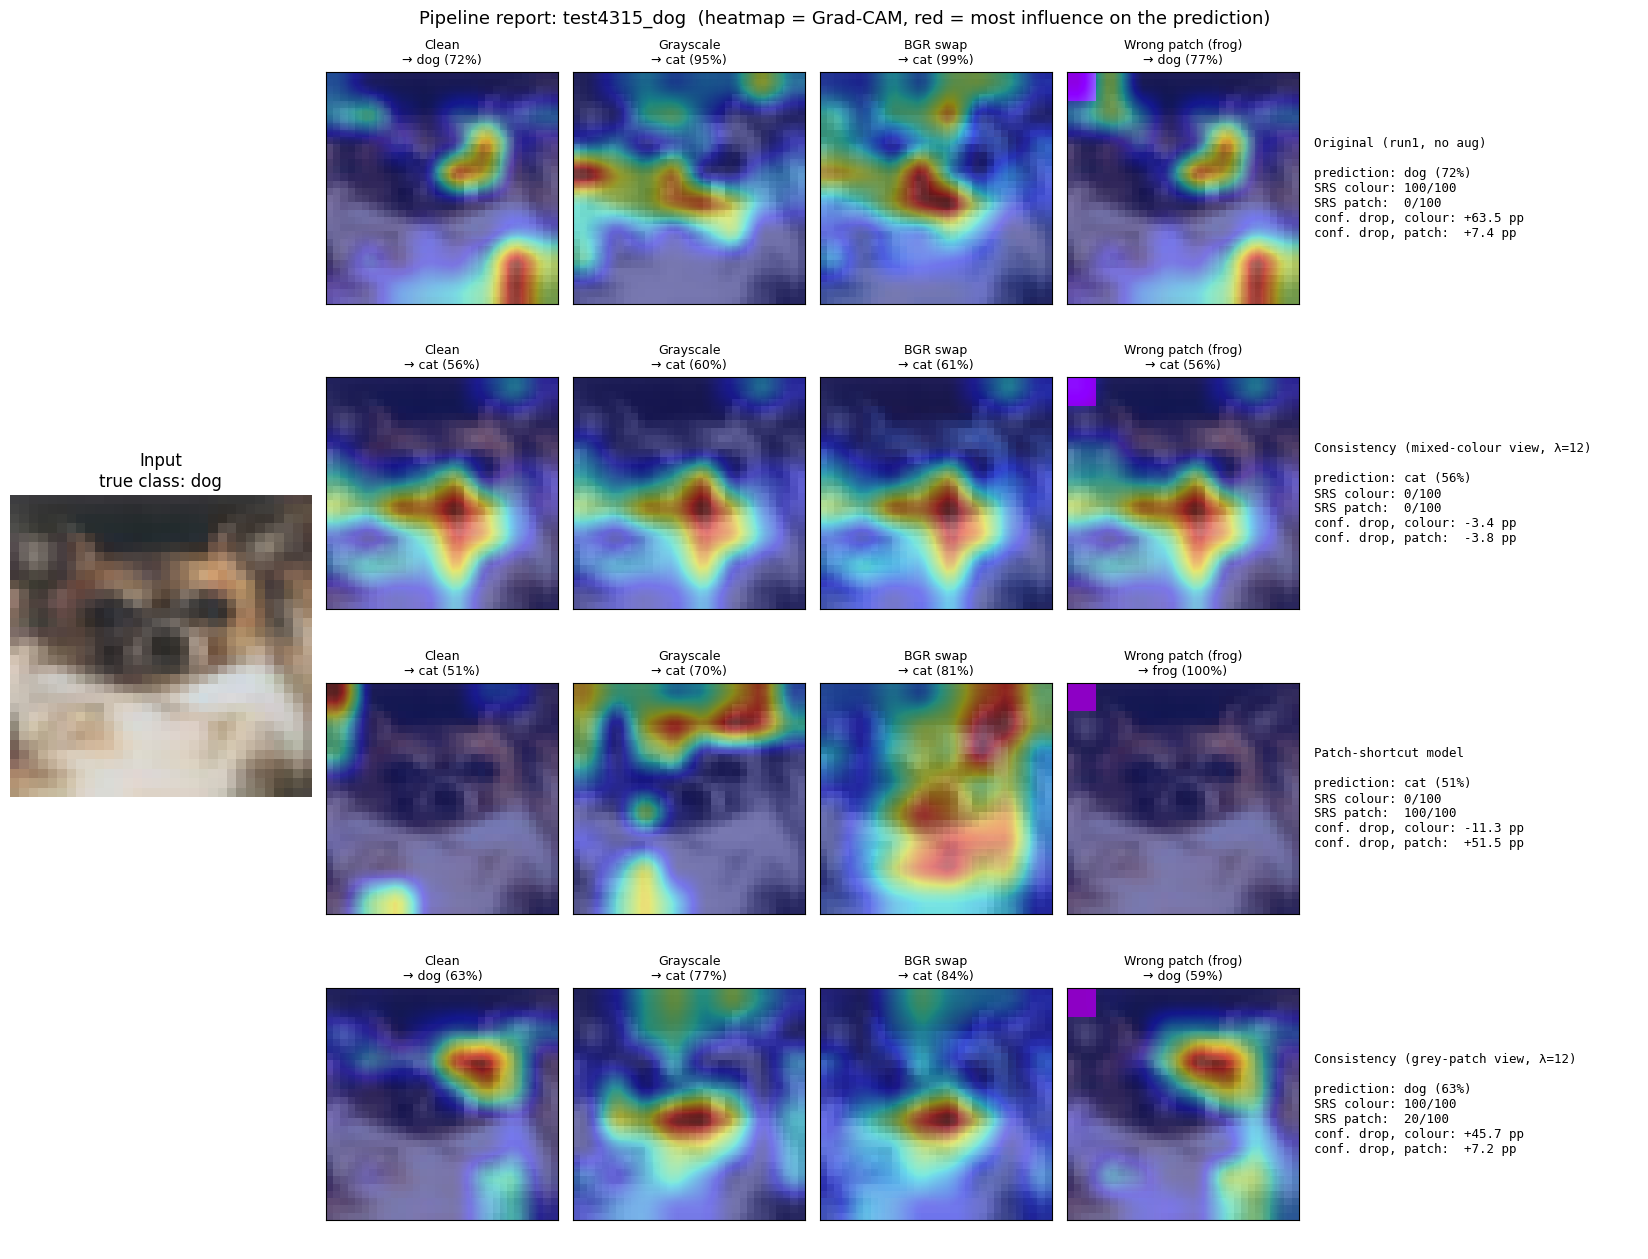

saved /content/drive/MyDrive/cifar10_animal_runs/pipeline/test4315_dog/report.png + report.json


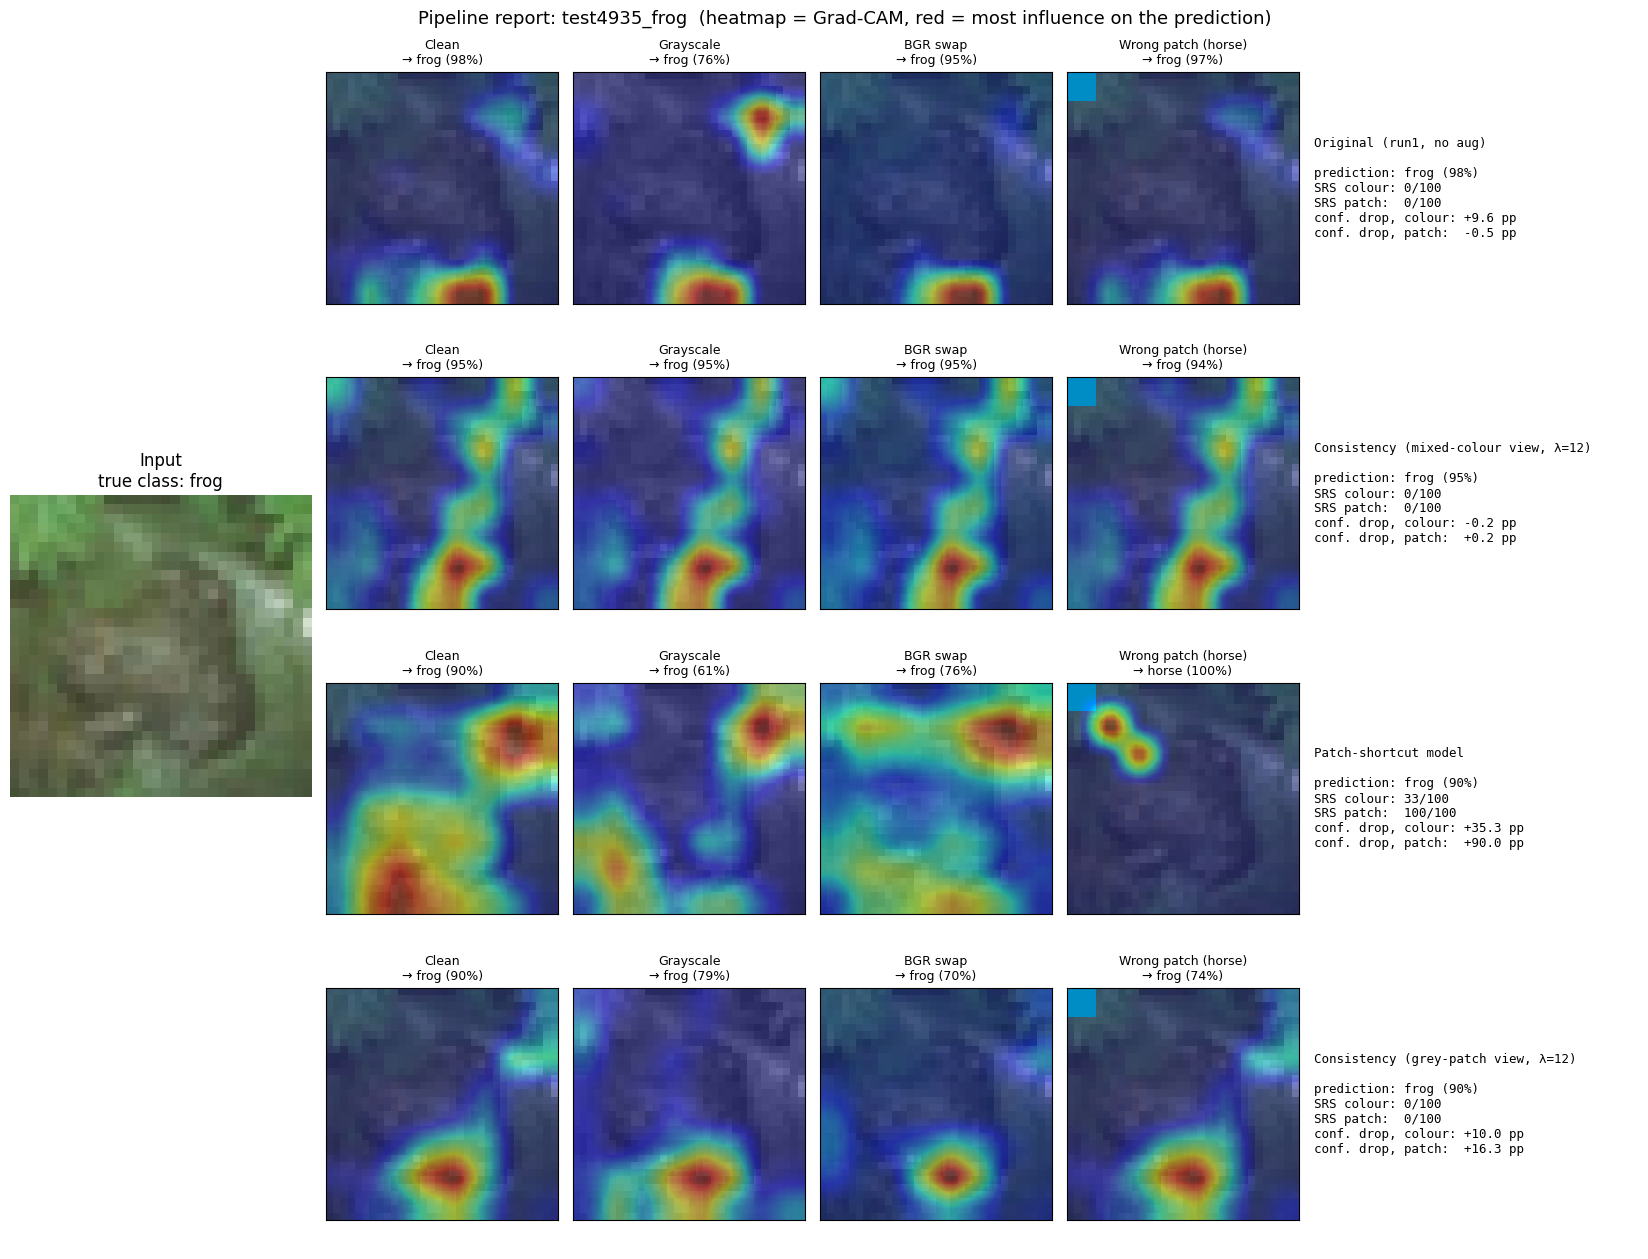

saved /content/drive/MyDrive/cifar10_animal_runs/pipeline/test4935_frog/report.png + report.json


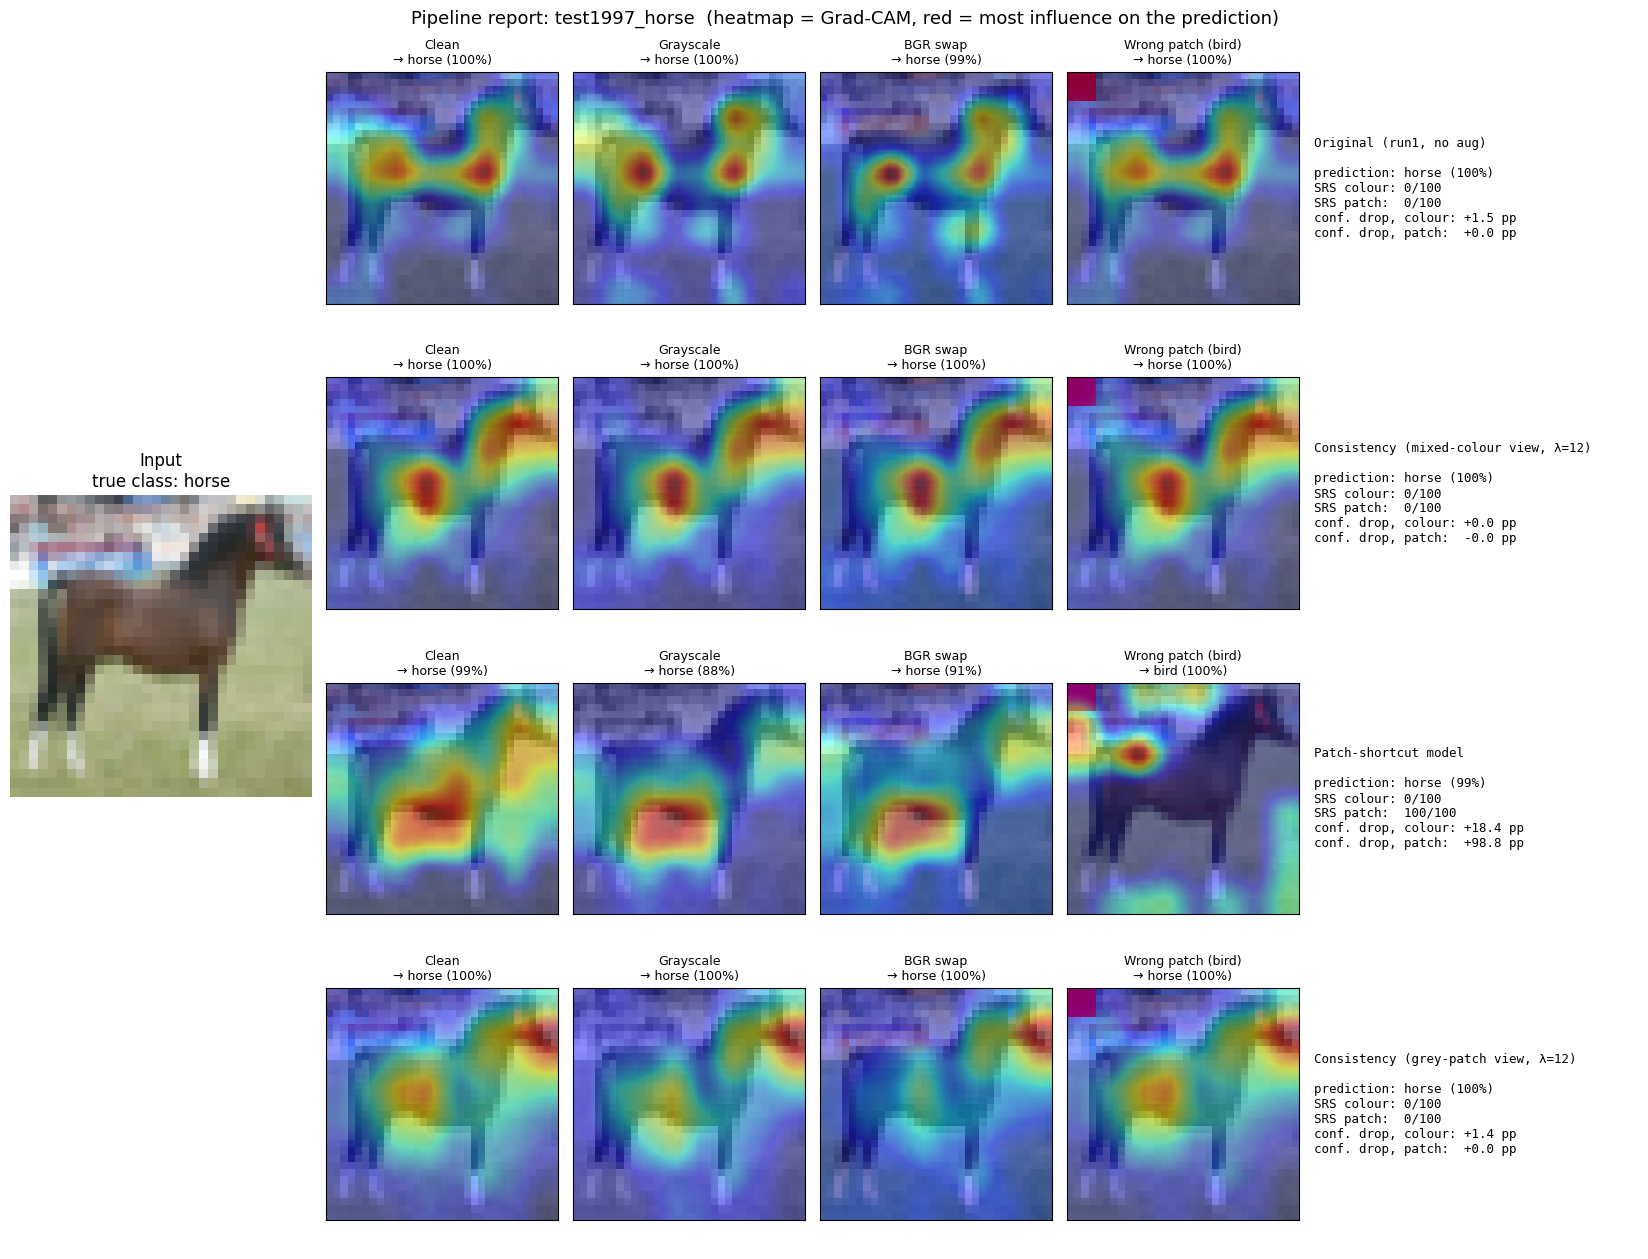

saved /content/drive/MyDrive/cifar10_animal_runs/pipeline/test1997_horse/report.png + report.json


prediction  confidence  \
image          model                                                          
test4577_bird  Original (run1, no aug)                     bird       0.694   
               Consistency (mixed-colour view, λ=12)        cat       0.598   
               Patch-shortcut model                        bird       0.348   
               Consistency (grey-patch view, λ=12)         bird       0.751   
test64_cat     Original (run1, no aug)                      cat       0.774   
               Consistency (mixed-colour view, λ=12)       frog       0.430   
               Patch-shortcut model                        bird       0.376   
               Consistency (grey-patch view, λ=12)         bird       0.323   
test3953_deer  Original (run1, no aug)                     deer       0.959   
               Consistency (mixed-colour view, λ=12)       deer       0.695   
               Patch-shortcut model                        deer       0.858   
               Consistency (grey-patch view, λ=12)         deer       0.946   
test4315_dog   Original (run1, no aug)                      dog       0.721   
               Consistency (mixed-colour view, λ=12)        cat       0.559   
               Patch-shortcut model                         cat       0.515   
               Consistency (grey-patch view, λ=12)          dog       0.632   
test4935_frog  Original (run1, no aug)                     frog       0.978   
               Consistency (mixed-colour view, λ=12)       frog       0.950   
               Patch-shortcut model                        frog       0.901   
               Consistency (grey-patch view, λ=12)         frog       0.902   
test1997_horse Original (run1, no aug)                    horse       1.000   
               Consistency (mixed-colour view, λ=12)      horse       1.000   
               Patch-shortcut model                       horse       0.991   
               Consistency (grey-patch view, λ=12)        horse       1.000   

                                                      srs_colour  srs_patch  
image          model                                                         
test4577_bird  Original (run1, no aug)                 66.666667       20.0  
               Consistency (mixed-colour view, λ=12)    0.000000        0.0  
               Patch-shortcut model                    66.666667      100.0  
               Consistency (grey-patch view, λ=12)     33.333333        0.0  
test64_cat     Original (run1, no aug)                 83.333333        0.0  
               Consistency (mixed-colour view, λ=12)    0.000000        0.0  
               Patch-shortcut model                    16.666667      100.0  
               Consistency (grey-patch view, λ=12)     50.000000       60.0  
test3953_deer  Original (run1, no aug)                 16.666667        0.0  
               Consistency (mixed-colour view, λ=12)    0.000000        0.0  
               Patch-shortcut model                    33.333333      100.0  
               Consistency (grey-patch view, λ=12)      0.000000        0.0  
test4315_dog   Original (run1, no aug)                100.000000        0.0  
               Consistency (mixed-colour view, λ=12)    0.000000        0.0  
               Patch-shortcut model                     0.000000      100.0  
               Consistency (grey-patch view, λ=12)    100.000000       20.0  
test4935_frog  Original (run1, no aug)                  0.000000        0.0  
               Consistency (mixed-colour view, λ=12)    0.000000        0.0  
               Patch-shortcut model                    33.333333      100.0  
               Consistency (grey-patch view, λ=12)      0.000000        0.0  
test1997_horse Original (run1, no aug)                  0.000000        0.0  
               Consistency (mixed-colour view, λ=12)    0.000000        0.0  
               Patch-shortcut model                     0.000000      100.0  
               Consistency (grey-patch view, λ=1

In [44]:
# [PIPELINE 7/9] RUN THE PIPELINE ON IMAGES: upload (or sample) -> predictions, ablations, SRS, Grad-CAM -> saved report.
# For a single image later: run_pipeline('/path/to/image.jpg')
require('analyse_image', cell='PIPELINE 6/9'); require('get_pipeline_images', cell='PIPELINE 5/9')
PIPE_MODELS = {label: keras.models.load_model(ROSTER[label]['path']) for label in PIPE_MODEL_LABELS}

def run_pipeline(path=None):
    """Analyse one image file (or, with no path, whatever get_pipeline_images() provides)."""
    imgs = get_pipeline_images() if path is None else {
        os.path.splitext(os.path.basename(path))[0]: dict(zip(['x', 'full'], load_image_32(path)), source=path, true=None)}
    out = {}
    for name, item in imgs.items():
        report, fig = analyse_image(name, item, PIPE_MODELS)
        plt.show(); plt.close(fig); out[name] = report
        print(f'saved {os.path.join(PIPE_DIR, name)}/report.png + report.json')
    return out

PIPE_REPORTS = run_pipeline()
rows = [dict(image=img, model=m, prediction=r['prediction'], confidence=round(r['confidence'], 3),
             srs_colour=r['srs_colour'], srs_patch=r['srs_patch'])
        for img, rep in PIPE_REPORTS.items() for m, r in rep['models'].items()]
display(pd.DataFrame(rows).set_index(['image', 'model']))

In [45]:
# [PIPELINE 8/9] Dataset-level evaluation of one model (accuracy, SRS, Grad-CAM attention). Definitions only.
require('condition_views', cell='CONSISTENCY 1/6')
FINAL_TEST_VIEWS = CONS_TEST_VIEWS if 'CONS_TEST_VIEWS' in globals() else condition_views(xte, yte)
_rng = np.random.default_rng(SEED + 21)
_pick = lambda k: np.sort(np.concatenate([_rng.choice(np.where(yte == c)[0], k, replace=False) for c in range(NCLS)]))
FINAL_SRS_IDX, FINAL_GC_IDX = _pick(PIPE_CFG['srs_per_class']), _pick(PIPE_CFG['gradcam_per_class'])

def _mean_ci(v):
    return float(np.mean(v)), float(1.96 * np.std(v, ddof=1) / np.sqrt(len(v)))

def eval_model(label, model):
    row = dict(model=label, family=ROSTER[label]['family'], role=ROSTER[label]['role'])
    for k, x in FINAL_TEST_VIEWS.items():
        row[f'acc_{k}'] = 100 * float((model.predict(x, batch_size=512, verbose=0).argmax(1) == yte).mean())
    row['worst_colour'] = min(row[f'acc_{c}'] for c in ('clean', 'gray', 'bgr'))
    row['worst_patch'] = min(row[f'acc_{c}'] for c in ('aligned', 'neutral', 'conflicting'))
    s = shortcut_reliance(model, xte[FINAL_SRS_IDX])
    for key in ('srs_colour', 'srs_patch', 'colour_conf_drop', 'patch_conf_drop'):
        row[key], row[f'{key}_ci95'] = _mean_ci(s[key])
    xg, yg = xte[FINAL_GC_IDX], yte[FINAL_GC_IDX]
    for cond, cls in [('aligned', yg), ('wrong', (yg + 1) % NCLS)]:
        row[f'patch_attention_{cond}'], row[f'patch_attention_{cond}_ci95'] = _mean_ci(
            patch_attention(gradcam(model, add_patch(xg, PATCH_COLORS[cls]))))
    per_image = pd.DataFrame(dict(model=label, image_idx=FINAL_SRS_IDX, true=np.array(ANIMALS)[yte[FINAL_SRS_IDX]],
                                  reference=np.array(ANIMALS)[s['ref']], **{k: s[k] for k in
                                  ('srs_colour', 'srs_patch', 'colour_conf_drop', 'patch_conf_drop')}))
    return row, per_image

In [46]:
# [PIPELINE 9/9] Evaluate every model in the roster on the test set. Feeds all final figures. A few minutes on a GPU.
require('eval_model', cell='PIPELINE 8/9')
rows, per_image = [], []
for label, info in ROSTER.items():
    if not info['found']:
        print('skipped (not trained yet):', label); continue
    m = PIPE_MODELS.get(label) or keras.models.load_model(info['path'])
    r, pi = eval_model(label, m); rows.append(r); per_image.append(pi)
    print(f"{label:48s} clean {r['acc_clean']:5.1f}% | SRS colour {r['srs_colour']:5.1f} | SRS patch {r['srs_patch']:5.1f}")
    del m
FINAL_EVAL = pd.DataFrame(rows)
FINAL_SRS_IMG = pd.concat(per_image, ignore_index=True)
FINAL_EVAL.to_csv(os.path.join(PIPE_DIR, 'final_eval.csv'), index=False)
FINAL_SRS_IMG.to_csv(os.path.join(PIPE_DIR, 'final_srs_per_image.csv'), index=False)
with open(os.path.join(PIPE_DIR, 'final_eval.json'), 'w') as fh:
    json.dump(dict(created=time.strftime('%Y-%m-%d %H:%M:%S'), n_test=int(len(yte)), n_srs=int(len(FINAL_SRS_IDX)),
                   n_gradcam=int(len(FINAL_GC_IDX)), models=FINAL_EVAL.to_dict(orient='records')), fh, indent=1)
print('Saved final_eval.csv / .json and final_srs_per_image.csv to', PIPE_DIR)

Original (run1, no aug)                          clean  84.0% | SRS colour  25.4 | SRS patch   1.0
Mild aug (run2)                                  clean  82.3% | SRS colour  24.4 | SRS patch   0.9
Stronger aug (run3)                              clean  82.0% | SRS colour   9.2 | SRS patch   0.8
Heavy aug (run4)                                 clean  77.0% | SRS colour   2.1 | SRS patch   0.7
Patch-shortcut model                             clean  67.1% | SRS colour  34.4 | SRS patch 100.0
Grayscale aug (g35_tone)                         clean  82.4% | SRS colour  14.6 | SRS patch   0.8
Consistency (gray view, λ=0)                     clean  80.2% | SRS colour  13.3 | SRS patch   0.5
Consistency (gray view, λ=12)                    clean  82.2% | SRS colour   3.1 | SRS patch   0.6
Consistency (mixed-colour view, λ=0)             clean  79.7% | SRS colour   3.4 | SRS patch   0.7
Consistency (mixed-colour view, λ=12)            clean  82.7% | SRS colour   1.2 | SRS patch   0.4
Consistenc

## Final figures

Each figure is saved as a PNG in `docs/final_figures/` (inside your repo when `PIPE_CFG['repo_dir']` points to it, or when the notebook runs from inside a git clone). The numbers behind each figure are saved as CSV in `docs/final_figures/data/`. The last cell writes `docs/final_figures/README.md`, with every figure and its caption, then checks that every output of the project exists.

In [47]:
# [FIGURES 1/10] Shared style, colours and the save helper. Every figure is saved to docs/final_figures/
# as a PNG, with the numbers behind it as CSV in docs/final_figures/data/.
require('FINAL_EVAL', cell='PIPELINE 9/9')
import textwrap
from matplotlib.patches import Patch
plt.rcParams.update({'figure.dpi': 100, 'savefig.dpi': PIPE_CFG['dpi'], 'font.size': 10, 'axes.titlesize': 12,
                     'axes.titleweight': 'bold', 'axes.labelsize': 11, 'legend.fontsize': 9,
                     'axes.spines.top': False, 'axes.spines.right': False, 'grid.alpha': 0.3})
ROLE_STYLE = {'original': ('#c0392b', 'Original model'),
              'augmentation': ('#95a5a6', 'Augmentation only'),
              'mitigation: data': ('#2e86c1', 'Grayscale augmentation (method 3)'),
              'ablation': ('#a9dfbf', 'Consistency control / other variant'),
              'mitigation: consistency': ('#1e8449', 'Consistency training (method 2, selected)')}
FIG_INDEX = {}   # file name -> caption, written to the README by FIGURES 10/10
E = FINAL_EVAL.set_index('model')

def role_legend(where, roles=None, **kw):
    roles = roles or list(dict.fromkeys(E.role))
    where.legend(handles=[Patch(color=ROLE_STYLE[r][0], label=ROLE_STYLE[r][1]) for r in roles], **kw)

def wrap(s, n=22):
    return '\n'.join(textwrap.wrap(s, n))

def save_fig(fig, name, caption, data=None):
    path = os.path.join(FINAL_FIG_DIR, f'{name}.png')
    fig.savefig(path, bbox_inches='tight', facecolor='white')
    if data is not None:
        data.to_csv(os.path.join(FINAL_DATA_DIR, f'{name}.csv'))
    FIG_INDEX[name] = caption
    plt.show(); plt.close(fig); print('saved', path)

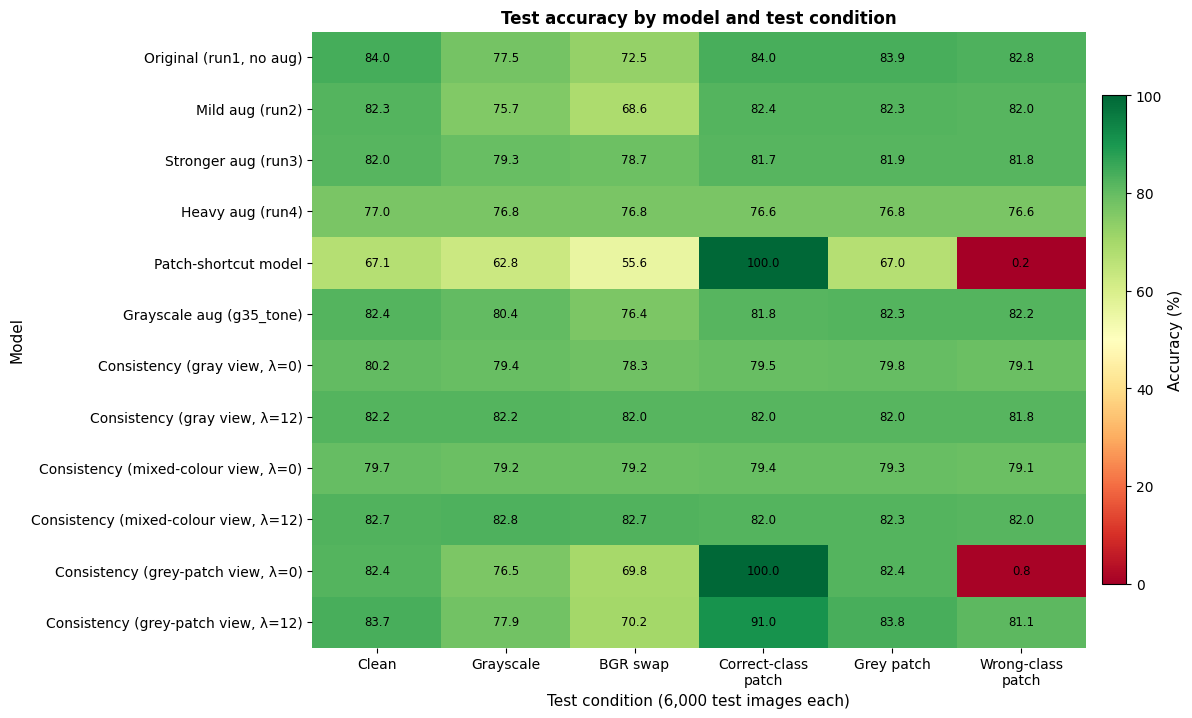

saved /content/drive/MyDrive/cifar10_animal_runs/repo_export/docs/final_figures/fig01_accuracy_by_condition.png


In [48]:
# [FIGURES 2/10] Figure 1: accuracy of every model under every test condition (heatmap).
cols = {'acc_clean': 'Clean', 'acc_gray': 'Grayscale', 'acc_bgr': 'BGR swap',
        'acc_aligned': 'Correct-class\npatch', 'acc_neutral': 'Grey patch', 'acc_conflicting': 'Wrong-class\npatch'}
d = E[list(cols)].rename(columns=cols)
fig, ax = plt.subplots(figsize=(10.5, 0.5 * len(d) + 2))
im = ax.imshow(d.values, cmap='RdYlGn', vmin=0, vmax=100, aspect='auto')
ax.set_xticks(range(len(cols)), d.columns); ax.set_yticks(range(len(d)), d.index)
for i in range(d.shape[0]):
    for j in range(d.shape[1]):
        ax.text(j, i, f'{d.values[i, j]:.1f}', ha='center', va='center', fontsize=8.5)
ax.set_xlabel(f'Test condition ({len(yte):,} test images each)'); ax.set_ylabel('Model')
ax.set_title('Test accuracy by model and test condition')
ax.spines[:].set_visible(False)
fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02).set_label('Accuracy (%)')
save_fig(fig, 'fig01_accuracy_by_condition',
         'Test accuracy (%) of every model under six conditions: clean, colour removed (grayscale), colours swapped '
         '(BGR), and the corner patch in the correct class colour, grey, or a wrong class colour.', d)

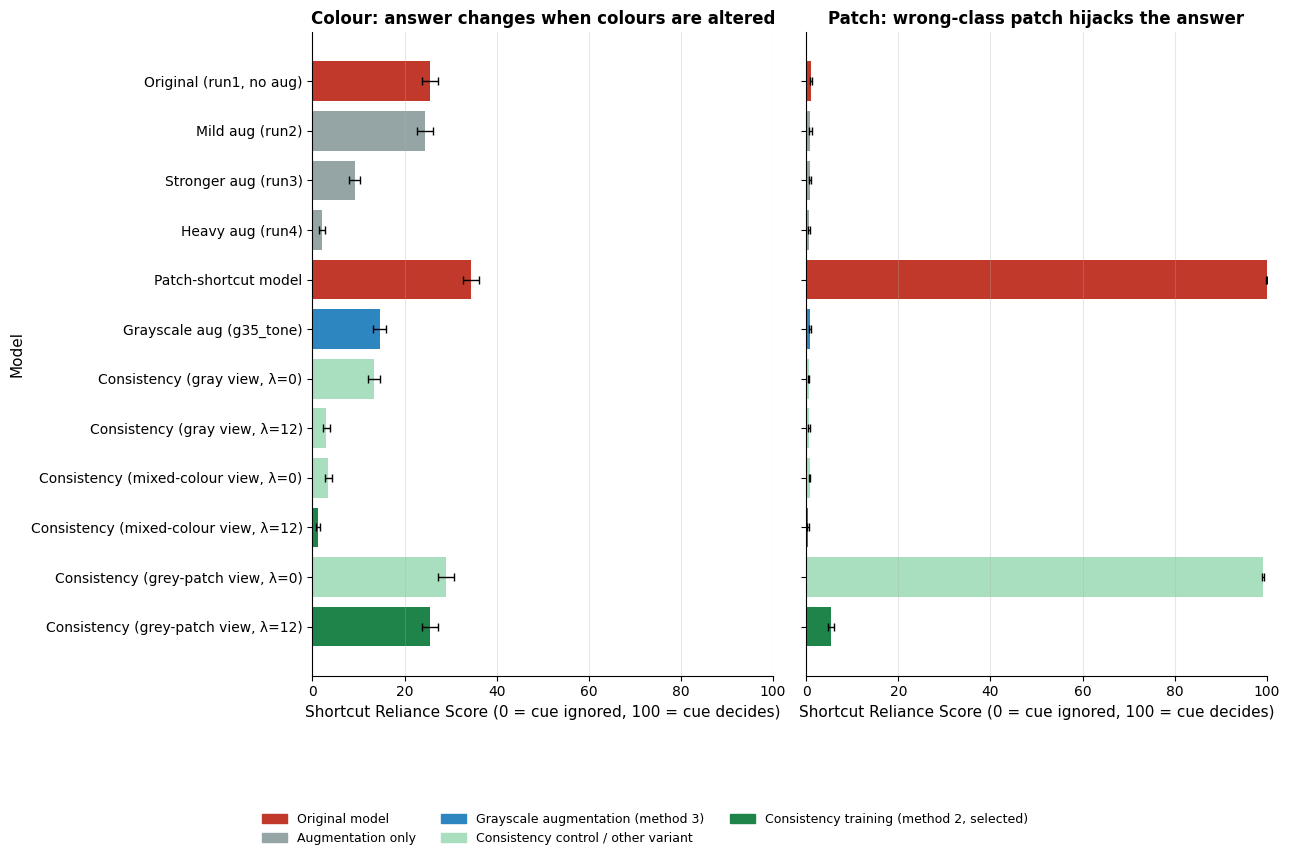

saved /content/drive/MyDrive/cifar10_animal_runs/repo_export/docs/final_figures/fig02_shortcut_reliance_score.png


In [49]:
# [FIGURES 3/10] Figure 2: Shortcut Reliance Score per model, colour and patch, with 95% confidence intervals.
def hbar_panels(keys, titles, xlabel, name, caption, xlim=(0, 100), ref=None, ref_label=None):
    fig, axes = plt.subplots(1, len(keys), figsize=(6.5 * len(keys), 0.45 * len(E) + 2), sharey=True)
    y = np.arange(len(E))
    for ax, key, title in zip(np.atleast_1d(axes), keys, titles):
        ax.barh(y, E[key], xerr=E[f'{key}_ci95'], color=[ROLE_STYLE[r][0] for r in E.role],
                capsize=3, error_kw=dict(lw=1))
        if ref is not None:
            ax.axvline(ref, ls='--', c='k', lw=1, label=ref_label); ax.legend(loc='lower right')
        ax.set_title(title); ax.set_xlabel(xlabel); ax.set_xlim(*xlim); ax.grid(axis='x')
    axes = np.atleast_1d(axes); axes[0].set_yticks(y, E.index); axes[0].invert_yaxis(); axes[0].set_ylabel('Model')
    role_legend(fig, loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.02 - 0.012 * len(E)), frameon=False)
    fig.tight_layout()
    save_fig(fig, name, caption, E[[c for k in keys for c in (k, f'{k}_ci95')]])

hbar_panels(['srs_colour', 'srs_patch'],
            ['Colour: answer changes when colours are altered', 'Patch: wrong-class patch hijacks the answer'],
            'Shortcut Reliance Score (0 = cue ignored, 100 = cue decides)', 'fig02_shortcut_reliance_score',
            f'Shortcut Reliance Score on {len(FINAL_SRS_IDX):,} class-balanced test images (error bars: 95% CI). '
            'Colour SRS = % of 6 colour ablations (grayscale, 5 channel swaps) that change the prediction; '
            'patch SRS = % of the 5 wrong-class patches that switch the prediction to the patch class.')

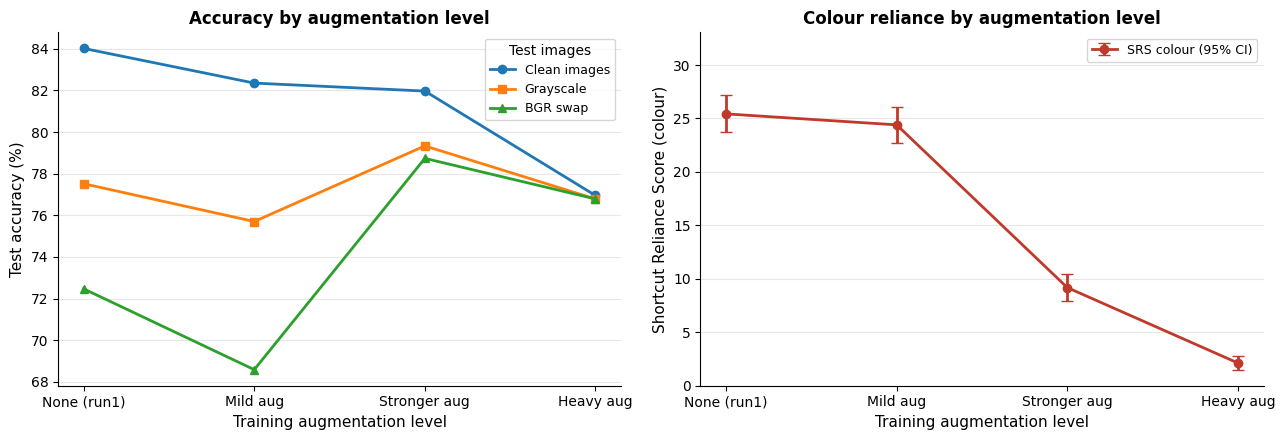

saved /content/drive/MyDrive/cifar10_animal_runs/repo_export/docs/final_figures/fig03_augmentation_levels.png


In [50]:
# [FIGURES 4/10] Figure 3: what increasing augmentation strength does to colour robustness.
lv = [l for l in ['Original (run1, no aug)', 'Mild aug (run2)', 'Stronger aug (run3)', 'Heavy aug (run4)'] if l in E.index]
d = E.loc[lv, ['acc_clean', 'acc_gray', 'acc_bgr', 'srs_colour', 'srs_colour_ci95']]
x = np.arange(len(lv)); short = [l.split(' (')[0] if 'run1' not in l else 'None (run1)' for l in lv]
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4.5))
for col, lab, mk in [('acc_clean', 'Clean images', 'o'), ('acc_gray', 'Grayscale', 's'), ('acc_bgr', 'BGR swap', '^')]:
    a.plot(x, d[col], marker=mk, lw=2, label=lab)
a.set_xticks(x, short); a.set_xlabel('Training augmentation level'); a.set_ylabel('Test accuracy (%)')
a.set_title('Accuracy by augmentation level'); a.legend(title='Test images'); a.grid(axis='y')
b.errorbar(x, d.srs_colour, yerr=d.srs_colour_ci95, marker='o', lw=2, capsize=4, color='#c0392b', label='SRS colour (95% CI)')
b.set_xticks(x, short); b.set_xlabel('Training augmentation level'); b.set_ylabel('Shortcut Reliance Score (colour)')
b.set_title('Colour reliance by augmentation level'); b.set_ylim(0, max(5, d.srs_colour.max() * 1.3)); b.legend(); b.grid(axis='y')
fig.tight_layout()
save_fig(fig, 'fig03_augmentation_levels',
         'Effect of training augmentation strength (run1 to run4): accuracy on clean, grayscale and colour-swapped test '
         'images (left) and the colour Shortcut Reliance Score (right).', d)

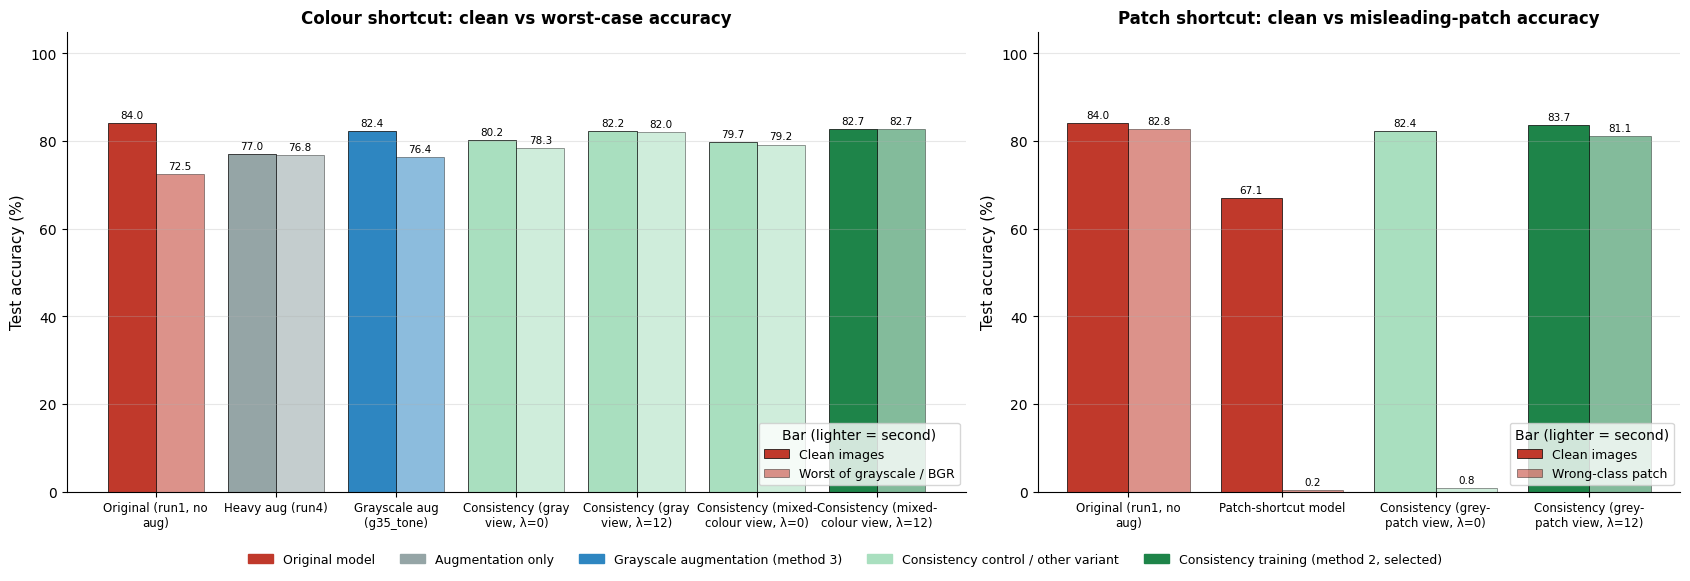

saved /content/drive/MyDrive/cifar10_animal_runs/repo_export/docs/final_figures/fig04_mitigation_ablation.png


In [51]:
# [FIGURES 5/10] Figure 4: mitigation ablation - which part of each method buys the robustness.
def grouped(ax, labels, cols, names, title, ylabel='Test accuracy (%)'):
    labels = [l for l in labels if l and l in E.index]
    x, w = np.arange(len(labels)), 0.8 / len(cols)
    for i, (c, n) in enumerate(zip(cols, names)):
        bars = ax.bar(x + (i - (len(cols) - 1) / 2) * w, E.loc[labels, c], w, label=n,
                      color=[ROLE_STYLE[E.loc[l, 'role']][0] for l in labels], alpha=1 - 0.45 * i, edgecolor='k', lw=0.5)
        ax.bar_label(bars, fmt='%.1f', fontsize=7.5, padding=2)
    ax.set_xticks(x, [wrap(l) for l in labels], fontsize=8.5); ax.set_ylabel(ylabel); ax.set_ylim(0, 105)
    ax.set_title(title); ax.grid(axis='y'); ax.legend(title='Bar (lighter = second)', loc='lower right')
    return labels

colour_models = [ORIGINAL_COLOUR, 'Heavy aug (run4)'] + [l for l in E.index if l.startswith('Grayscale aug')] + \
                [l for l in E.index if l.startswith('Consistency') and E.loc[l, 'family'] == 'colour']
patch_models = [ORIGINAL_COLOUR, ORIGINAL_PATCH] + [l for l in E.index if l.startswith('Consistency') and E.loc[l, 'family'] == 'patch']
fig, (a, b) = plt.subplots(1, 2, figsize=(17, 5.5), gridspec_kw=dict(width_ratios=[len(colour_models), len(patch_models) + 1]))
cl = grouped(a, colour_models, ['acc_clean', 'worst_colour'], ['Clean images', 'Worst of grayscale / BGR'],
             'Colour shortcut: clean vs worst-case accuracy')
pl = grouped(b, patch_models, ['acc_clean', 'acc_conflicting'], ['Clean images', 'Wrong-class patch'],
             'Patch shortcut: clean vs misleading-patch accuracy')
role_legend(fig, loc='lower center', ncol=5, bbox_to_anchor=(0.5, -0.06), frameon=False)
fig.tight_layout()
save_fig(fig, 'fig04_mitigation_ablation',
         'Ablation of the mitigations. Left: clean and worst-case colour accuracy for augmentation, grayscale '
         'augmentation and consistency training (λ=0 controls see the same views without the consistency term). '
         'Right: clean and wrong-class-patch accuracy for the patch-shortcut model and its consistency-trained versions.',
         E.loc[list(dict.fromkeys(cl + pl)), ['acc_clean', 'worst_colour', 'acc_conflicting']])

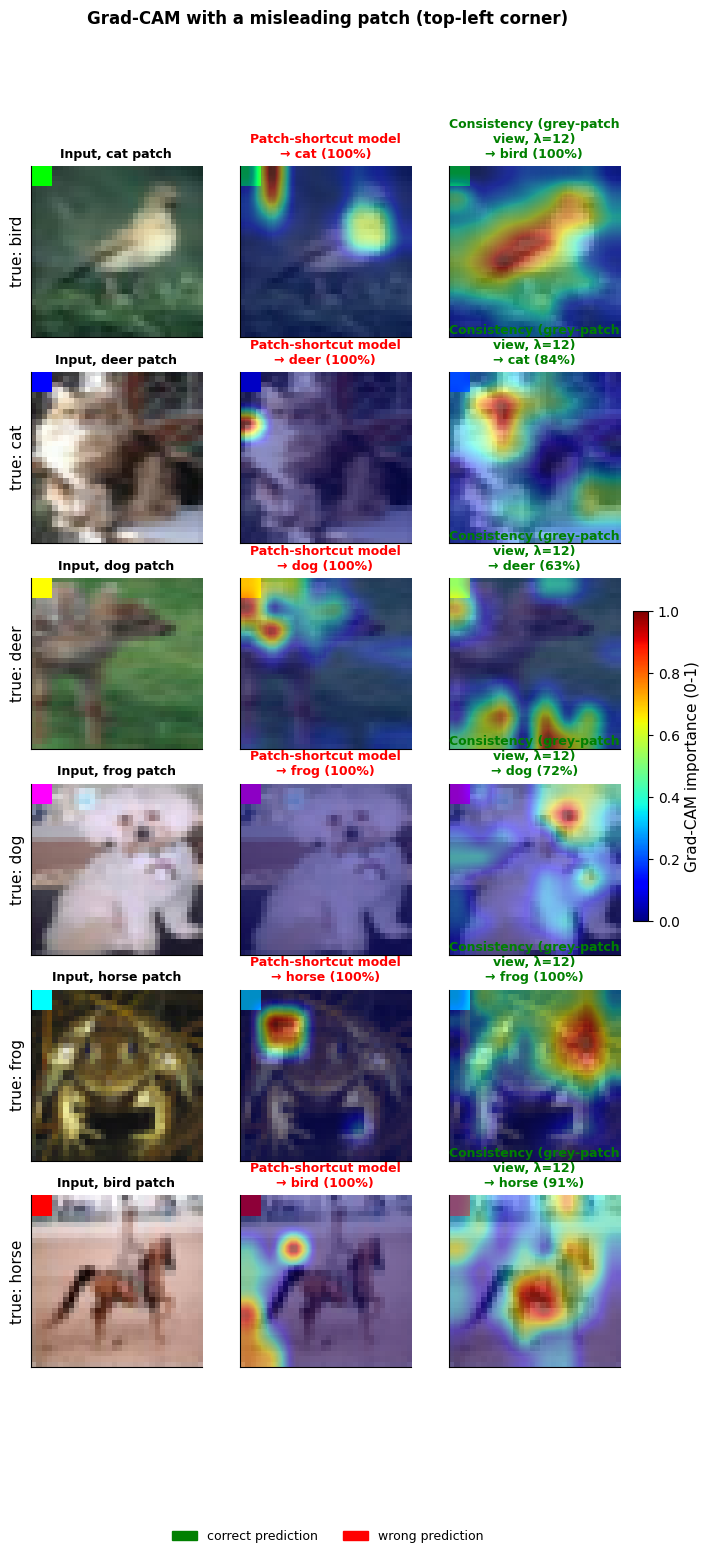

saved /content/drive/MyDrive/cifar10_animal_runs/repo_export/docs/final_figures/fig05_gradcam_patch.png


In [52]:
# [FIGURES 6/10] Figure 5: Grad-CAM with a wrong-class patch - the original looks at the patch, the mitigated model doesn't.
_r = np.random.default_rng(SEED + 31)
FIG_EX = np.array([int(_r.choice(np.where(yte == c)[0])) for c in range(NCLS)])   # one test image per class
xe, ye = xte[FIG_EX], yte[FIG_EX]; wrong_e = (ye + 1) % NCLS
xw = add_patch(xe, PATCH_COLORS[wrong_e])
fig, axes = plt.subplots(NCLS, 3, figsize=(8, 2.6 * NCLS))
rows = []
for j, label in enumerate([ORIGINAL_PATCH, MITIGATED_PATCH]):
    m = PIPE_MODELS[label]; p = m.predict(xw, verbose=0); cams = gradcam(m, xw)
    for i in range(NCLS):
        pred = int(p[i].argmax())
        cam_panel(axes[i, j + 1], xw[i], cams[i], f'{wrap(label, 26)}\n→ {ANIMALS[pred]} ({p[i].max():.0%})',
                  'green' if pred == ye[i] else 'red')
        rows.append(dict(model=label, image_idx=FIG_EX[i], true=ANIMALS[ye[i]], patch_class=ANIMALS[wrong_e[i]],
                         pred=ANIMALS[pred], conf=float(p[i].max()), patch_attention=float(patch_attention(cams[i:i + 1])[0])))
for i in range(NCLS):
    axes[i, 0].imshow(xw[i]); axes[i, 0].set_xticks([]); axes[i, 0].set_yticks([])
    axes[i, 0].set_ylabel(f'true: {ANIMALS[ye[i]]}'); axes[i, 0].set_title(f'Input, {ANIMALS[wrong_e[i]]} patch', fontsize=9)
fig.legend(handles=[Patch(color='green', label='correct prediction'), Patch(color='red', label='wrong prediction')],
           loc='lower center', ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.01))
fig.colorbar(plt.cm.ScalarMappable(cmap='jet', norm=plt.Normalize(0, 1)), ax=axes, fraction=0.025, pad=0.02,
             label='Grad-CAM importance (0-1)')
fig.suptitle('Grad-CAM with a misleading patch (top-left corner)', fontweight='bold')
save_fig(fig, 'fig05_gradcam_patch',
         'Grad-CAM on one test image per class with a wrong-class colour patch in the top-left corner. Titles show the '
         'prediction and its confidence (green = correct, red = wrong).', pd.DataFrame(rows))

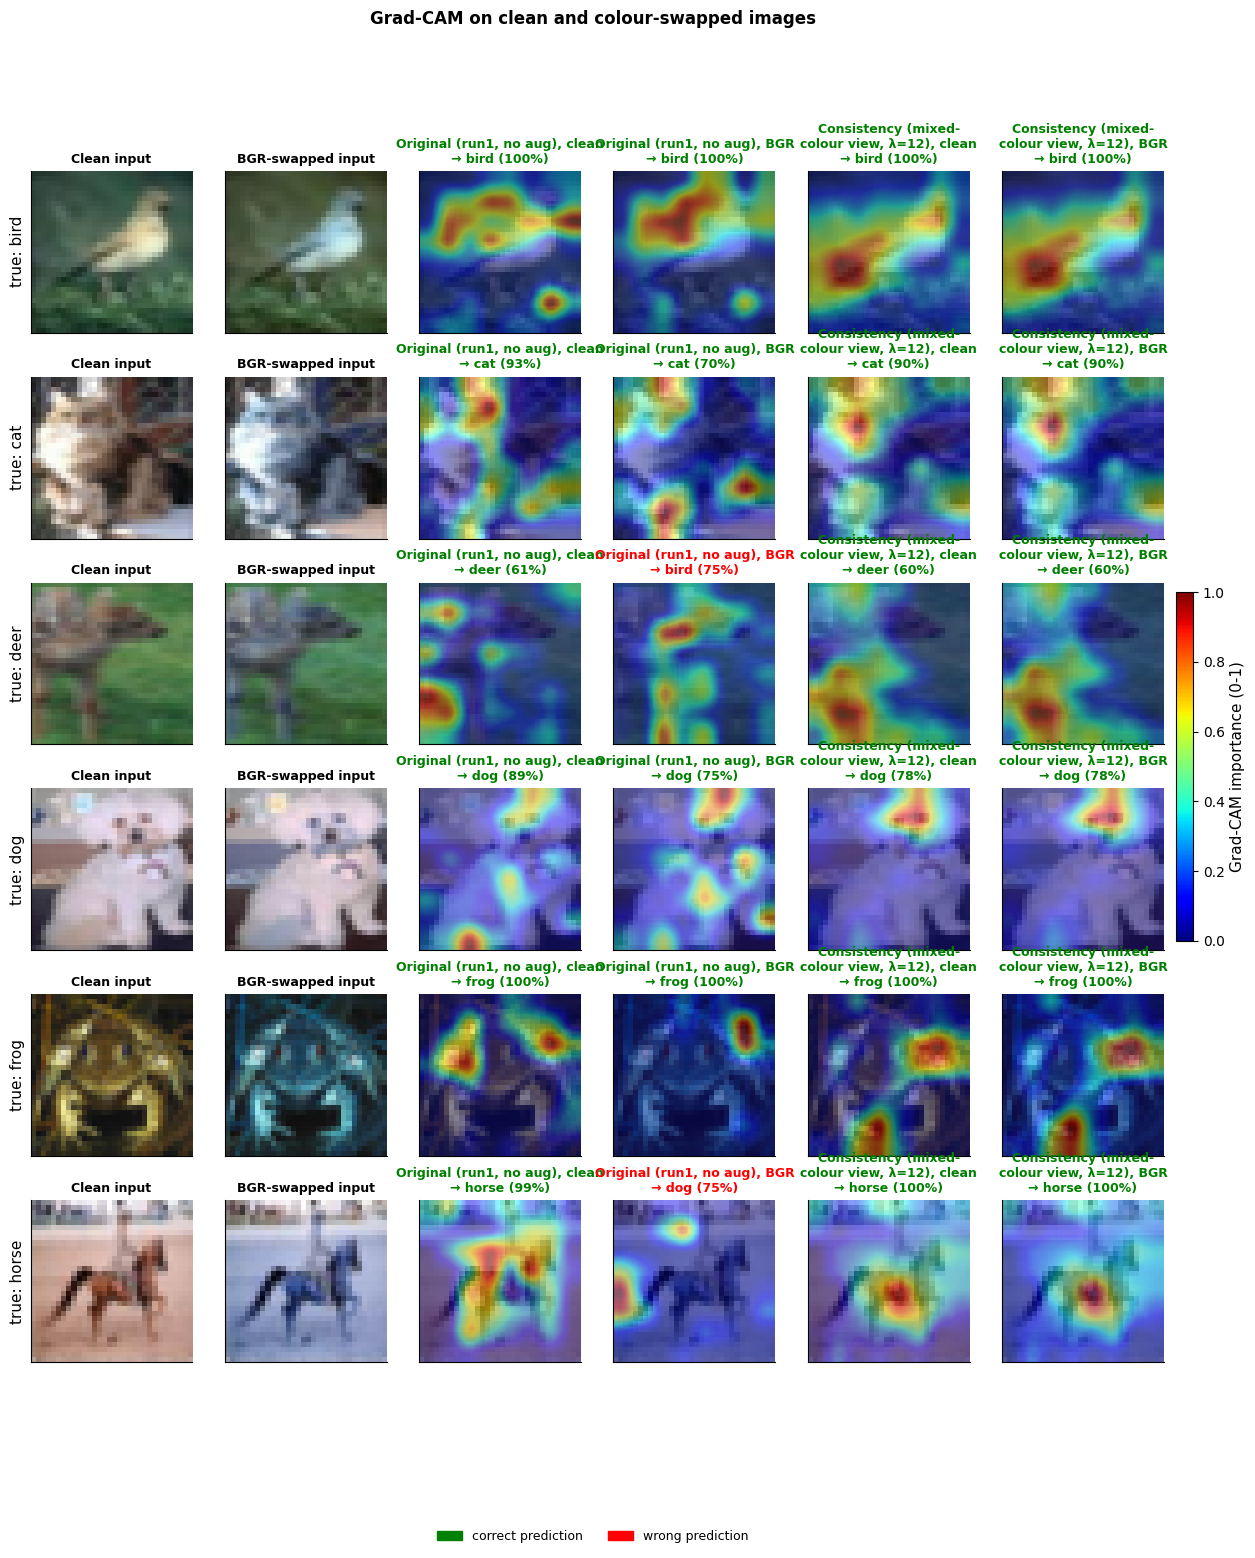

saved /content/drive/MyDrive/cifar10_animal_runs/repo_export/docs/final_figures/fig06_gradcam_colour.png


In [53]:
# [FIGURES 7/10] Figure 6: Grad-CAM on clean vs colour-swapped images, original vs colour-mitigated model.
xb = colour_ablate(xe, 'swap BGR')
fig, axes = plt.subplots(NCLS, 6, figsize=(15, 2.6 * NCLS))
rows = []
for i in range(NCLS):
    for c, (img, t) in enumerate([(xe[i], 'Clean input'), (xb[i], 'BGR-swapped input')]):
        axes[i, c].imshow(img); axes[i, c].set_xticks([]); axes[i, c].set_yticks([]); axes[i, c].set_title(t, fontsize=9)
    axes[i, 0].set_ylabel(f'true: {ANIMALS[ye[i]]}')
for j, label in enumerate([ORIGINAL_COLOUR, MITIGATED_COLOUR]):
    m = PIPE_MODELS[label]
    for k, (xx, vname) in enumerate([(xe, 'clean'), (xb, 'BGR')]):
        p, cams = m.predict(xx, verbose=0), gradcam(m, xx)
        for i in range(NCLS):
            pred = int(p[i].argmax())
            cam_panel(axes[i, 2 + 2 * j + k], xx[i], cams[i],
                      f'{wrap(label, 24)}, {vname}\n→ {ANIMALS[pred]} ({p[i].max():.0%})', 'green' if pred == ye[i] else 'red')
            rows.append(dict(model=label, view=vname, image_idx=FIG_EX[i], true=ANIMALS[ye[i]],
                             pred=ANIMALS[pred], conf=float(p[i].max())))
fig.legend(handles=[Patch(color='green', label='correct prediction'), Patch(color='red', label='wrong prediction')],
           loc='lower center', ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.01))
fig.colorbar(plt.cm.ScalarMappable(cmap='jet', norm=plt.Normalize(0, 1)), ax=axes, fraction=0.015, pad=0.01,
             label='Grad-CAM importance (0-1)')
fig.suptitle('Grad-CAM on clean and colour-swapped images', fontweight='bold')
save_fig(fig, 'fig06_gradcam_colour',
         'Grad-CAM for the original model and the colour-mitigated consistency model on the same images in normal '
         'colour and with red and blue swapped (BGR). Titles show prediction and confidence (green = correct).', pd.DataFrame(rows))

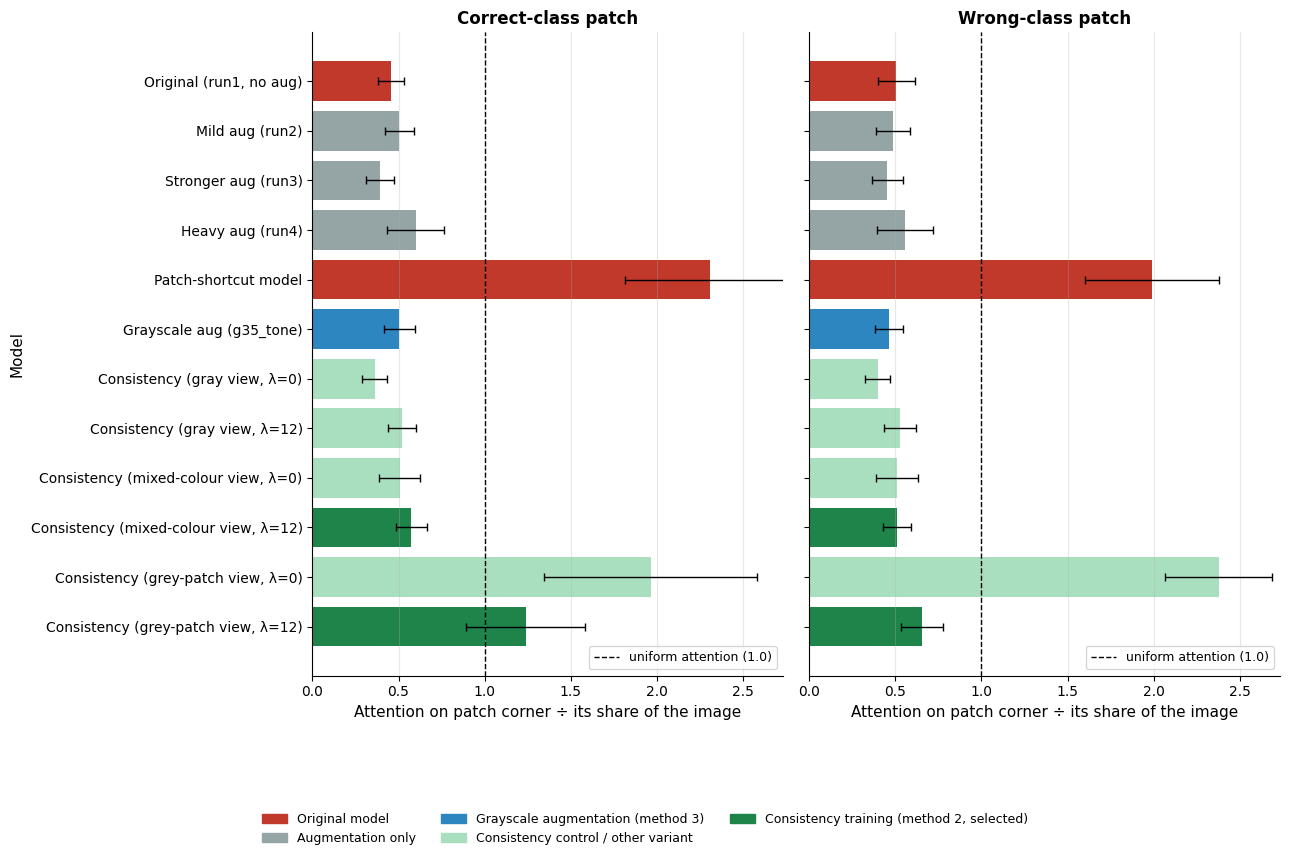

saved /content/drive/MyDrive/cifar10_animal_runs/repo_export/docs/final_figures/fig07_gradcam_patch_attention.png


In [54]:
# [FIGURES 8/10] Figure 7: how much Grad-CAM attention lands on the patch corner, across many test images.
hbar_panels(['patch_attention_aligned', 'patch_attention_wrong'],
            ['Correct-class patch', 'Wrong-class patch'],
            'Attention on patch corner ÷ its share of the image', 'fig07_gradcam_patch_attention',
            f'Grad-CAM attention on the 4x4 patch corner, relative to its 1.6% share of the image, averaged over '
            f'{len(FINAL_GC_IDX):,} test images (error bars: 95% CI). 1 = no more attention than any other pixel.',
            xlim=(0, max(2.0, float(E[["patch_attention_aligned", "patch_attention_wrong"]].max().max()) * 1.15)),
            ref=1.0, ref_label='uniform attention (1.0)')

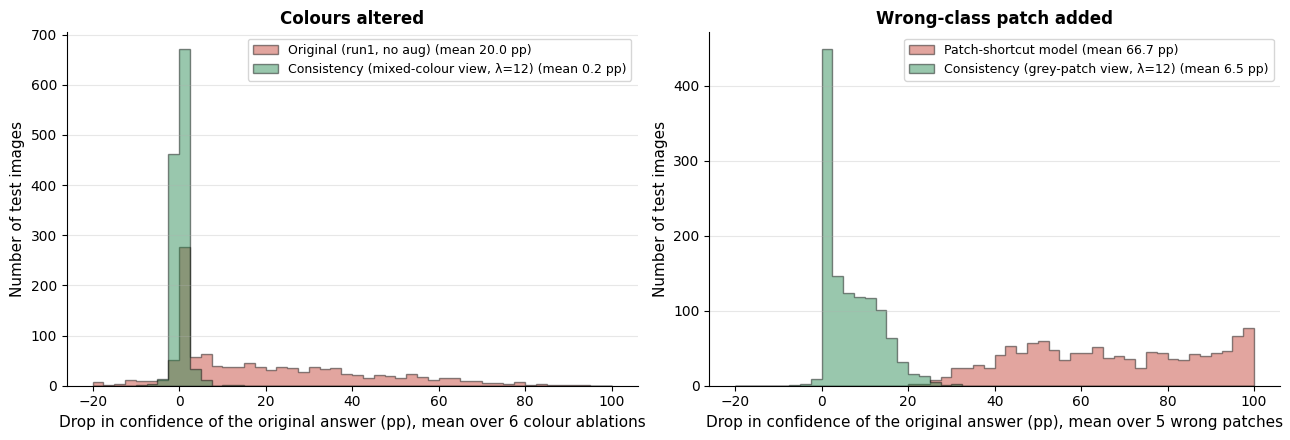

saved /content/drive/MyDrive/cifar10_animal_runs/repo_export/docs/final_figures/fig08_confidence_shift.png


In [55]:
# [FIGURES 9/10] Figure 8: per-image confidence drop when the shortcut is altered, original vs mitigated.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
bins = np.linspace(-20, 100, 49)
for ax, key, pair, title, xl in [
        (axes[0], 'colour_conf_drop', (ORIGINAL_COLOUR, MITIGATED_COLOUR), 'Colours altered',
         'Drop in confidence of the original answer (pp), mean over 6 colour ablations'),
        (axes[1], 'patch_conf_drop', (ORIGINAL_PATCH, MITIGATED_PATCH), 'Wrong-class patch added',
         'Drop in confidence of the original answer (pp), mean over 5 wrong patches')]:
    for label in pair:
        v = FINAL_SRS_IMG.loc[FINAL_SRS_IMG.model == label, key].clip(bins[0], bins[-1])
        ax.hist(v, bins=bins, histtype='stepfilled', alpha=0.45, color=ROLE_STYLE[ROSTER[label]['role']][0],
                edgecolor='k', lw=0.6, label=f'{wrap(label, 40)} (mean {v.mean():.1f} pp)')
    ax.set_title(title); ax.set_xlabel(xl); ax.set_ylabel('Number of test images'); ax.legend(); ax.grid(axis='y')
fig.tight_layout()
save_fig(fig, 'fig08_confidence_shift',
         f'Distribution over {len(FINAL_SRS_IDX):,} test images of how much confidence in the original prediction drops '
         'when colours are altered (left) or a wrong-class patch is added (right), original vs mitigated model.',
         FINAL_SRS_IMG[FINAL_SRS_IMG.model.isin([ORIGINAL_COLOUR, MITIGATED_COLOUR, ORIGINAL_PATCH, MITIGATED_PATCH])]
         .set_index(['model', 'image_idx'])[['colour_conf_drop', 'patch_conf_drop']])

In [56]:
# [FIGURES 10/10] Copy a pipeline example, write docs/final_figures/README.md, and check every project output exists.
import shutil
if PIPE_REPORTS:
    first = next(iter(PIPE_REPORTS))
    shutil.copy(os.path.join(PIPE_DIR, first, 'report.png'), os.path.join(FINAL_FIG_DIR, 'fig09_pipeline_example.png'))
    FIG_INDEX['fig09_pipeline_example'] = (f'End-to-end pipeline output for one image ({first}): each model\'s prediction, '
                                           'Grad-CAM under four conditions, and its Shortcut Reliance Scores.')
lines = ['# Final figures', '', f'Generated {time.strftime("%Y-%m-%d %H:%M")} by the notebook\'s PIPELINE and FIGURES '
         'sections. The numbers behind each figure are in `data/`.', '',
         '**Shortcut Reliance Score (SRS):** reference = the model\'s own prediction on the unaltered image. '
         'Colour SRS = % of 6 colour ablations (grayscale, 5 channel swaps) that change the prediction. '
         'Patch SRS = % of the 5 wrong-class corner patches that switch the prediction to the patch class. '
         '0 = cue ignored, 100 = cue always decides.', '']
for name, cap in FIG_INDEX.items():
    lines += [f'## {name}', '', f'![{name}]({name}.png)', '', cap, '']
with open(os.path.join(FINAL_FIG_DIR, 'README.md'), 'w') as fh:
    fh.write('\n'.join(lines))

checks = {'dataset cache': DATA_FILE,
          **{f'four-run {l}': os.path.join(OUT_DIR, l, f'{l}_results.json') for l in LEVELS},
          'shortcut experiment': os.path.join(OUT_DIR, 'shortcut_experiment', 'summary_by_condition.csv'),
          'track 1 index': os.path.join(OUT_DIR, 'track1', 'index.json'),
          'grayscale winner': os.path.join(OUT_DIR, 'grayscale', 'best.json'),
          'consistency winners': os.path.join(OUT_DIR, 'consistency', 'best.json'),
          'final evaluation': os.path.join(PIPE_DIR, 'final_eval.json'),
          **{f'pipeline report {n}': os.path.join(PIPE_DIR, n, 'report.json') for n in PIPE_REPORTS},
          **{f'figure {n}': os.path.join(FINAL_FIG_DIR, f'{n}.png') for n in FIG_INDEX},
          'figures README': os.path.join(FINAL_FIG_DIR, 'README.md')}
status = pd.DataFrame([dict(output=k, ok=os.path.exists(p) and os.path.getsize(p) > 0, path=p) for k, p in checks.items()])
display(status.set_index('output'))
bad = status[~status.ok]
assert bad.empty, f'Missing outputs: {list(bad.output)}'
print(f'All {len(status)} outputs present. Figures and README are in {FINAL_FIG_DIR}')

,ok,path
output,,
dataset cache,True,/content/drive/MyDrive/cifar10_animal_runs/dat...
four-run run1_original,True,/content/drive/MyDrive/cifar10_animal_runs/run...
four-run run2_mild,True,/content/drive/MyDrive/cifar10_animal_runs/run...
four-run run3_stronger,True,/content/drive/MyDrive/cifar10_animal_runs/run...
four-run run4_heavy,True,/content/drive/MyDrive/cifar10_animal_runs/run...
shortcut experiment,True,/content/drive/MyDrive/cifar10_animal_runs/sho...
track 1 index,True,/content/drive/MyDrive/cifar10_animal_runs/tra...
grayscale winner,True,/content/drive/MyDrive/cifar10_animal_runs/gra...
consistency winners,True,/content/drive/MyDrive/cifar10_animal_runs/con...


All 26 outputs present. Figures and README are in /content/drive/MyDrive/cifar10_animal_runs/repo_export/docs/final_figures


---
## Push your branch

The notebook can't push to GitHub for you, because that needs your credentials. From a terminal, or a Colab cell prefixed with `!`, inside your clone:

```bash
git checkout -b final-pipeline-and-figures      # or your branch name
git add cifar10_animal_classification.ipynb docs/final_figures
git commit -m "Final pipeline (prediction, ablation, SRS, Grad-CAM) and final figures"
git push -u origin final-pipeline-and-figures
```

Models and data stay on Drive (`OUT_DIR`). Only the notebook and `docs/final_figures/` need to go in the repo.